# EDA and Visualization: NYC Taxi Demand (Manhattan + Queens)

Data: `features.csv` (one row per zone per hour, 8 Sep 2025 - 28 Feb 2026). Charts go to `EDA_doc/figures/`, tables to `EDA_doc/tables/`.

Sections: 1. Zone segmentation (#59) · 2. Demand over time (#60) · 3. Weather (#61) · 4. Feature relationships (#62)

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

In [2]:
# Dataset files (in the dataset/ folder next to the git folder)
DATA_DIR = "../../../dataset/archive"
FEATURES_FILE = DATA_DIR + "/features.csv"
ZONES_FILE = DATA_DIR + "/NYC-taxi-demand-Manhattan-Queens/kaggle_upload/taxi_zones_manhattan_queens.csv"

# Where charts and tables are saved
FIG_DIR = "../EDA_doc/figures"
TABLE_DIR = "../EDA_doc/tables"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)


def save_fig(name):
    # Save the current chart as a PNG and show it
    plt.tight_layout()
    plt.savefig(FIG_DIR + "/" + name + ".png", dpi=120, bbox_inches="tight")
    plt.show()

### Load the data and join zone names

In [3]:
df = pd.read_csv(FEATURES_FILE, parse_dates=["pickup_hour"])
zones = pd.read_csv(ZONES_FILE)

print("Rows:", len(df))
print("Zones:", df["PULocationID"].nunique())
print("Period:", df["pickup_hour"].min(), "to", df["pickup_hour"].max())
print("Total trips:", df["trip_count"].sum())
df.head()

Rows: 576288
Zones: 138
Period: 2025-09-08 00:00:00 to 2026-02-28 23:00:00
Total trips: 21728117


,PULocationID,pickup_hour,trip_count,apparent_temperature,rain,snowfall,precipitation_probability,hour,day_of_week,month,is_weekend,is_holiday,trip_count_lag_1h,trip_count_lag_24h,trip_count_lag_168h,trip_count_roll_3h,trip_count_roll_24h
0,2,2025-09-08 00:00:00,0,13.8,0.0,0.0,0,0,0,9,False,False,0,0,0,0.0,0.0
1,2,2025-09-08 01:00:00,0,13.5,0.0,0.0,0,1,0,9,False,False,0,0,0,0.0,0.0
2,2,2025-09-08 02:00:00,0,13.5,0.0,0.0,0,2,0,9,False,False,0,0,0,0.0,0.0
3,2,2025-09-08 03:00:00,0,12.7,0.0,0.0,0,3,0,9,False,False,0,0,0,0.0,0.0
4,2,2025-09-08 04:00:00,0,12.3,0.0,0.0,0,4,0,9,False,False,0,0,0,0.0,0.0


In [4]:
# Rename the lookup columns so they match the feature table
zones = zones.rename(columns={
    "LocationID": "PULocationID",
    "Borough": "borough",
    "Zone": "zone_name",
})

# Some zone names repeat (e.g. the three island zones), so add the ID to the label
zones["zone_label"] = zones["zone_name"] + " (" + zones["PULocationID"].astype(str) + ")"

df = df.merge(zones, on="PULocationID", how="left")
zones.head()

,PULocationID,borough,zone_name,service_zone,latitude,longitude,zone_label
0,2,Queens,Jamaica Bay,Boro Zone,40.61675,-73.83130,Jamaica Bay (2)
1,4,Manhattan,Alphabet City,Yellow Zone,40.72375,-73.97697,Alphabet City (4)
2,7,Queens,Astoria,Boro Zone,40.76149,-73.91969,Astoria (7)
3,8,Queens,Astoria Park,Boro Zone,40.77856,-73.92309,Astoria Park (8)
4,9,Queens,Auburndale,Boro Zone,40.75103,-73.78795,Auburndale (9)


### Helper columns (in memory only)

In [5]:
df["date"] = df["pickup_hour"].dt.normalize()


def get_time_band(hour):
    if hour <= 4:
        return "Late night"
    elif hour <= 6:
        return "Early morning"
    elif hour <= 9:
        return "AM rush"
    elif hour <= 15:
        return "Midday"
    elif hour <= 19:
        return "PM rush"
    else:
        return "Evening"


df["time_band"] = df["hour"].apply(get_time_band)

# Day type: Holiday first, then Weekend, otherwise Weekday
df["day_type"] = "Weekday"
df.loc[df["is_weekend"] == True, "day_type"] = "Weekend"
df.loc[df["is_holiday"] == True, "day_type"] = "Holiday"

# The daylight saving hour has about double the normal trips (two clock hours in one)
df["is_dst_hour"] = df["pickup_hour"] == pd.Timestamp("2025-11-02 01:00:00")

df["is_zero"] = df["trip_count"] == 0

DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
TIME_BANDS = ["Late night", "Early morning", "AM rush", "Midday", "PM rush", "Evening"]
BOROUGH_COLORS = {"Manhattan": "tab:blue", "Queens": "tab:orange"}

df[["pickup_hour", "zone_label", "borough", "trip_count", "time_band", "day_type"]].head()

,pickup_hour,zone_label,borough,trip_count,time_band,day_type
0,2025-09-08 00:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday
1,2025-09-08 01:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday
2,2025-09-08 02:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday
3,2025-09-08 03:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday
4,2025-09-08 04:00:00,Jamaica Bay (2),Queens,0,Late night,Weekday


### Zone summary table

In [6]:
zone_stats = df.groupby("PULocationID").agg(
    total_trips=("trip_count", "sum"),
    avg_per_hour=("trip_count", "mean"),
    zero_share=("is_zero", "mean"),
).reset_index()

zone_stats = zone_stats.merge(zones, on="PULocationID")
zone_stats = zone_stats.sort_values("total_trips", ascending=False).reset_index(drop=True)
zone_stats.head(10)

,PULocationID,total_trips,avg_per_hour,zero_share,borough,zone_name,service_zone,latitude,longitude,zone_label
0,237,1015744,243.233716,0.002155,Manhattan,Upper East Side South,Yellow Zone,40.76862,-73.96563,Upper East Side South (237)
1,161,921353,220.630508,0.000479,Manhattan,Midtown Center,Yellow Zone,40.75803,-73.97770,Midtown Center (161)
2,236,919941,220.292385,0.003831,Manhattan,Upper East Side North,Yellow Zone,40.78044,-73.95701,Upper East Side North (236)
3,132,844604,202.251916,0.003592,Queens,JFK Airport,Airports,40.64699,-73.78653,JFK Airport (132)
4,186,690164,165.269157,0.000479,Manhattan,Penn Station/Madison Sq West,Yellow Zone,40.74850,-73.99244,Penn Station/Madison Sq West (186)
5,162,683449,163.661159,0.000479,Manhattan,Midtown East,Yellow Zone,40.75669,-73.97236,Midtown East (162)
6,142,664996,159.242337,0.002395,Manhattan,Lincoln Square East,Yellow Zone,40.77363,-73.98153,Lincoln Square East (142)
7,230,648767,155.356082,0.001676,Manhattan,Times Sq/Theatre District,Yellow Zone,40.75982,-73.98420,Times Sq/Theatre District (230)
8,234,596884,142.931992,0.001437,Manhattan,Union Sq,Yellow Zone,40.74034,-73.99046,Union Sq (234)
9,79,590795,141.473898,0.000479,Manhattan,East Village,Yellow Zone,40.72762,-73.98594,East Village (79)


---
# 1. Zone demand segmentation and predictability (#59)

## C1. Zone ranking

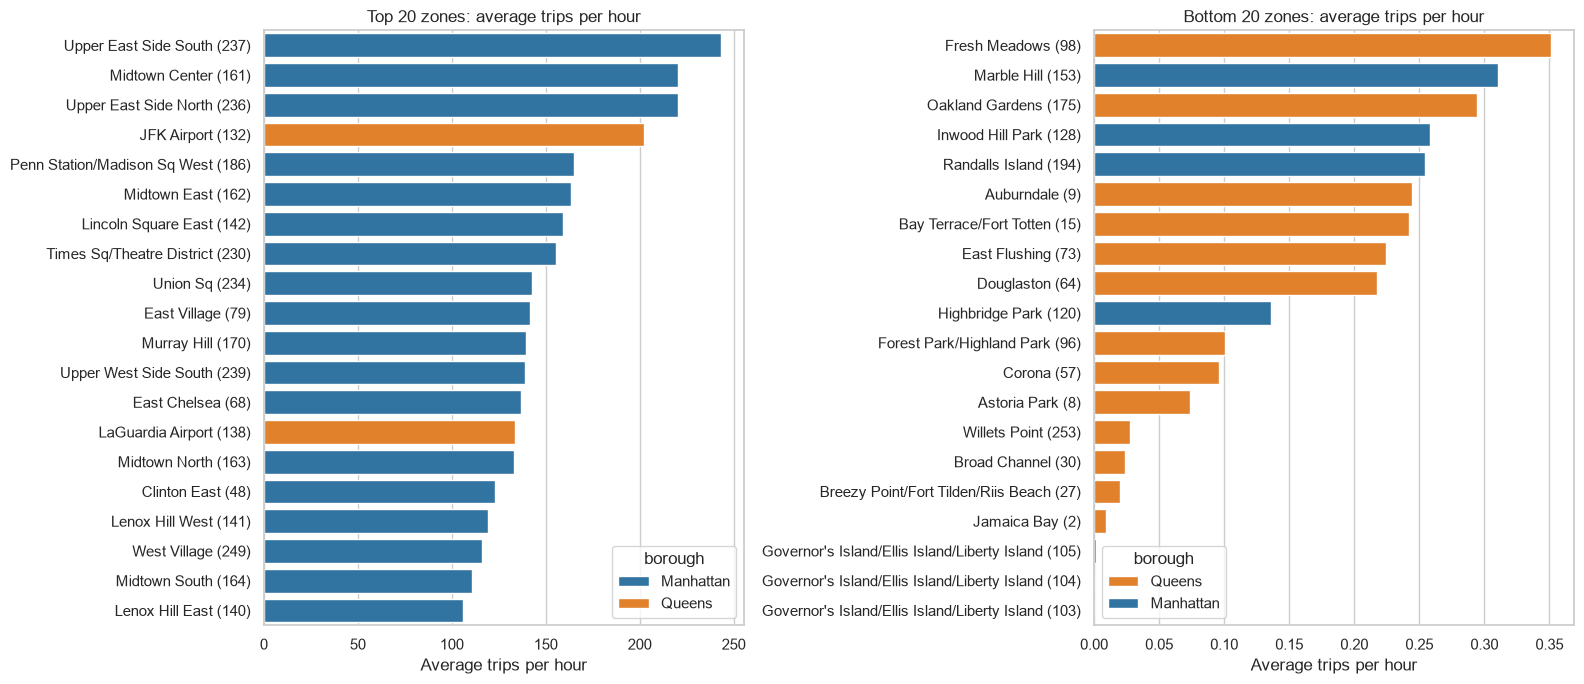

In [7]:
top20 = zone_stats.head(20)
bottom20 = zone_stats.tail(20)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(data=top20, y="zone_label", x="avg_per_hour", hue="borough",
            palette=BOROUGH_COLORS, dodge=False, ax=axes[0])
axes[0].set_title("Top 20 zones: average trips per hour")
axes[0].set_xlabel("Average trips per hour")
axes[0].set_ylabel("")

sns.barplot(data=bottom20, y="zone_label", x="avg_per_hour", hue="borough",
            palette=BOROUGH_COLORS, dodge=False, ax=axes[1])
axes[1].set_title("Bottom 20 zones: average trips per hour")
axes[1].set_xlabel("Average trips per hour")
axes[1].set_ylabel("")

save_fig("C1_top_bottom_zones")

In [8]:
# Totals by borough
borough_totals = zone_stats.groupby("borough")["total_trips"].sum()
print(borough_totals)
print()
print("Manhattan share of trips:", round(borough_totals["Manhattan"] / borough_totals.sum() * 100, 1), "%")
print()
print("Top 10 zones:")
print(zone_stats[["zone_label", "borough", "total_trips", "avg_per_hour"]].head(10).to_string(index=False))

borough
Manhattan    19679535
Queens        2048582
Name: total_trips, dtype: int64

Manhattan share of trips: 90.6 %

Top 10 zones:
                        zone_label   borough  total_trips  avg_per_hour
       Upper East Side South (237) Manhattan      1015744    243.233716
              Midtown Center (161) Manhattan       921353    220.630508
       Upper East Side North (236) Manhattan       919941    220.292385
                 JFK Airport (132)    Queens       844604    202.251916
Penn Station/Madison Sq West (186) Manhattan       690164    165.269157
                Midtown East (162) Manhattan       683449    163.661159
         Lincoln Square East (142) Manhattan       664996    159.242337
   Times Sq/Theatre District (230) Manhattan       648767    155.356082
                    Union Sq (234) Manhattan       596884    142.931992
                 East Village (79) Manhattan       590795    141.473898


**Finding:** Manhattan has 90.6% of trips. Busiest: Upper East Side South (243/hour), Midtown Center, Upper East Side North. JFK is the only Queens zone in the top 10.

## C2. Demand concentration (Pareto, Lorenz, Gini)

Zones needed for 50% of trips: 16 of 138
Zones needed for 80% of trips: 33 of 138


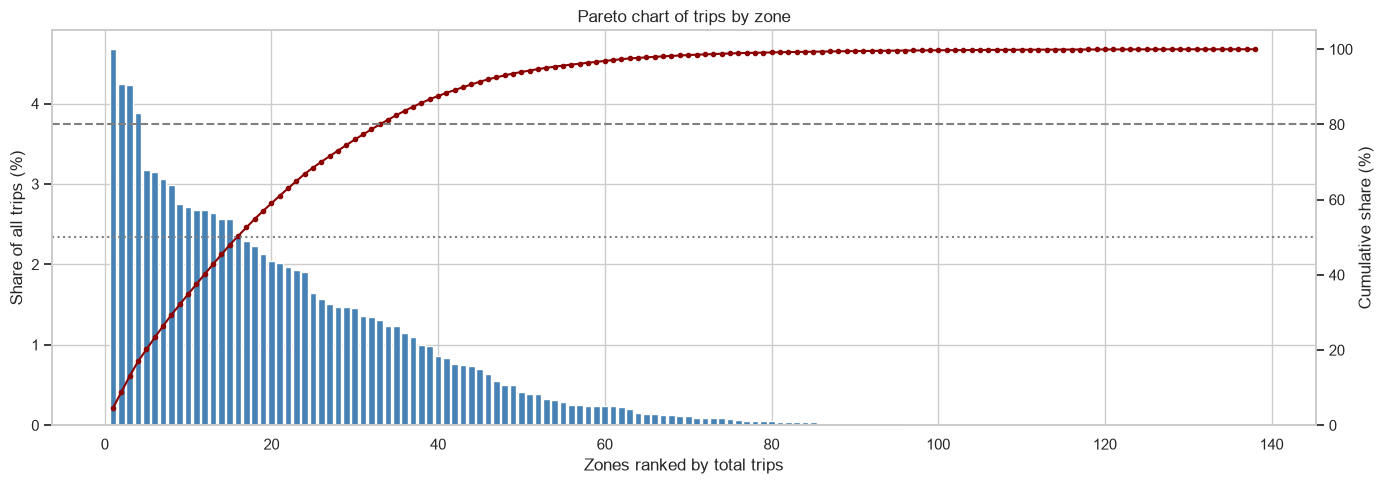

In [9]:
trips_sorted = zone_stats["total_trips"].values          # already sorted high to low
cum_share = trips_sorted.cumsum() / trips_sorted.sum()

zones_for_50 = (cum_share < 0.5).sum() + 1
zones_for_80 = (cum_share < 0.8).sum() + 1
print("Zones needed for 50% of trips:", zones_for_50, "of", len(zone_stats))
print("Zones needed for 80% of trips:", zones_for_80, "of", len(zone_stats))

fig, ax1 = plt.subplots(figsize=(14, 5))
x = np.arange(1, len(trips_sorted) + 1)
ax1.bar(x, trips_sorted / trips_sorted.sum() * 100, color="steelblue")
ax1.set_xlabel("Zones ranked by total trips")
ax1.set_ylabel("Share of all trips (%)")

ax2 = ax1.twinx()
ax2.plot(x, cum_share * 100, color="darkred", marker=".")
ax2.axhline(80, color="gray", linestyle="--")
ax2.axhline(50, color="gray", linestyle=":")
ax2.set_ylabel("Cumulative share (%)")
ax2.set_ylim(0, 105)
ax2.grid(False)

plt.title("Pareto chart of trips by zone")
save_fig("C2_pareto_chart")

All zones Gini: 0.709
Manhattan Gini: 0.486
Queens Gini: 0.844


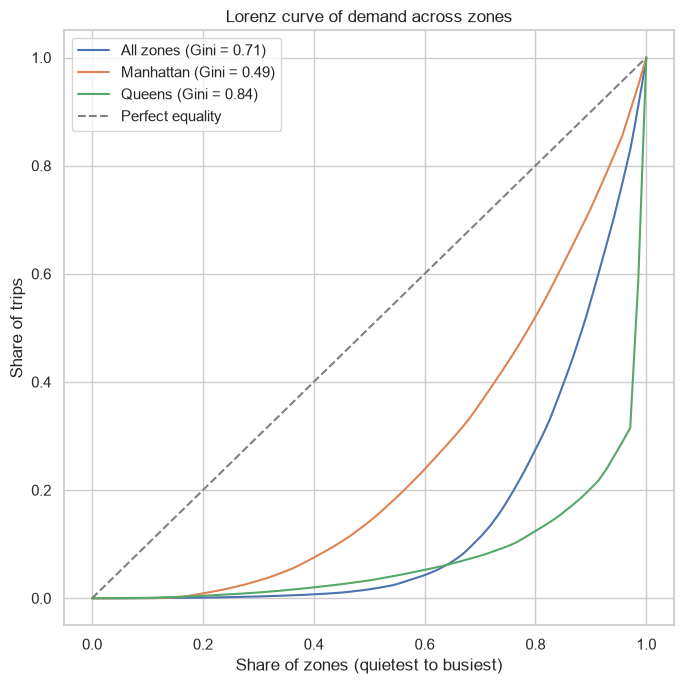

In [10]:
def gini(values):
    # Gini coefficient: 0 = perfectly equal, 1 = all demand in one zone
    values = np.sort(np.array(values, dtype=float))
    n = len(values)
    cum = np.cumsum(values)
    return (n + 1 - 2 * cum.sum() / cum[-1]) / n


def lorenz_points(values):
    values = np.sort(np.array(values, dtype=float))
    cum = np.cumsum(values) / values.sum()
    x = np.arange(0, len(values) + 1) / len(values)
    y = np.insert(cum, 0, 0)
    return x, y


plt.figure(figsize=(7, 7))
groups = {
    "All zones": zone_stats["total_trips"],
    "Manhattan": zone_stats[zone_stats["borough"] == "Manhattan"]["total_trips"],
    "Queens": zone_stats[zone_stats["borough"] == "Queens"]["total_trips"],
}
for name, values in groups.items():
    x, y = lorenz_points(values)
    g = gini(values)
    plt.plot(x, y, label=name + " (Gini = " + str(round(g, 2)) + ")")
    print(name, "Gini:", round(g, 3))

plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Perfect equality")
plt.xlabel("Share of zones (quietest to busiest)")
plt.ylabel("Share of trips")
plt.title("Lorenz curve of demand across zones")
plt.legend()
save_fig("C2_lorenz_curve")

**Finding:** 16 of 138 zones make up 50% of trips, 33 zones make up 80%. Gini: 0.71 overall, 0.49 Manhattan, 0.84 Queens.

## C6. Demand maps by time band

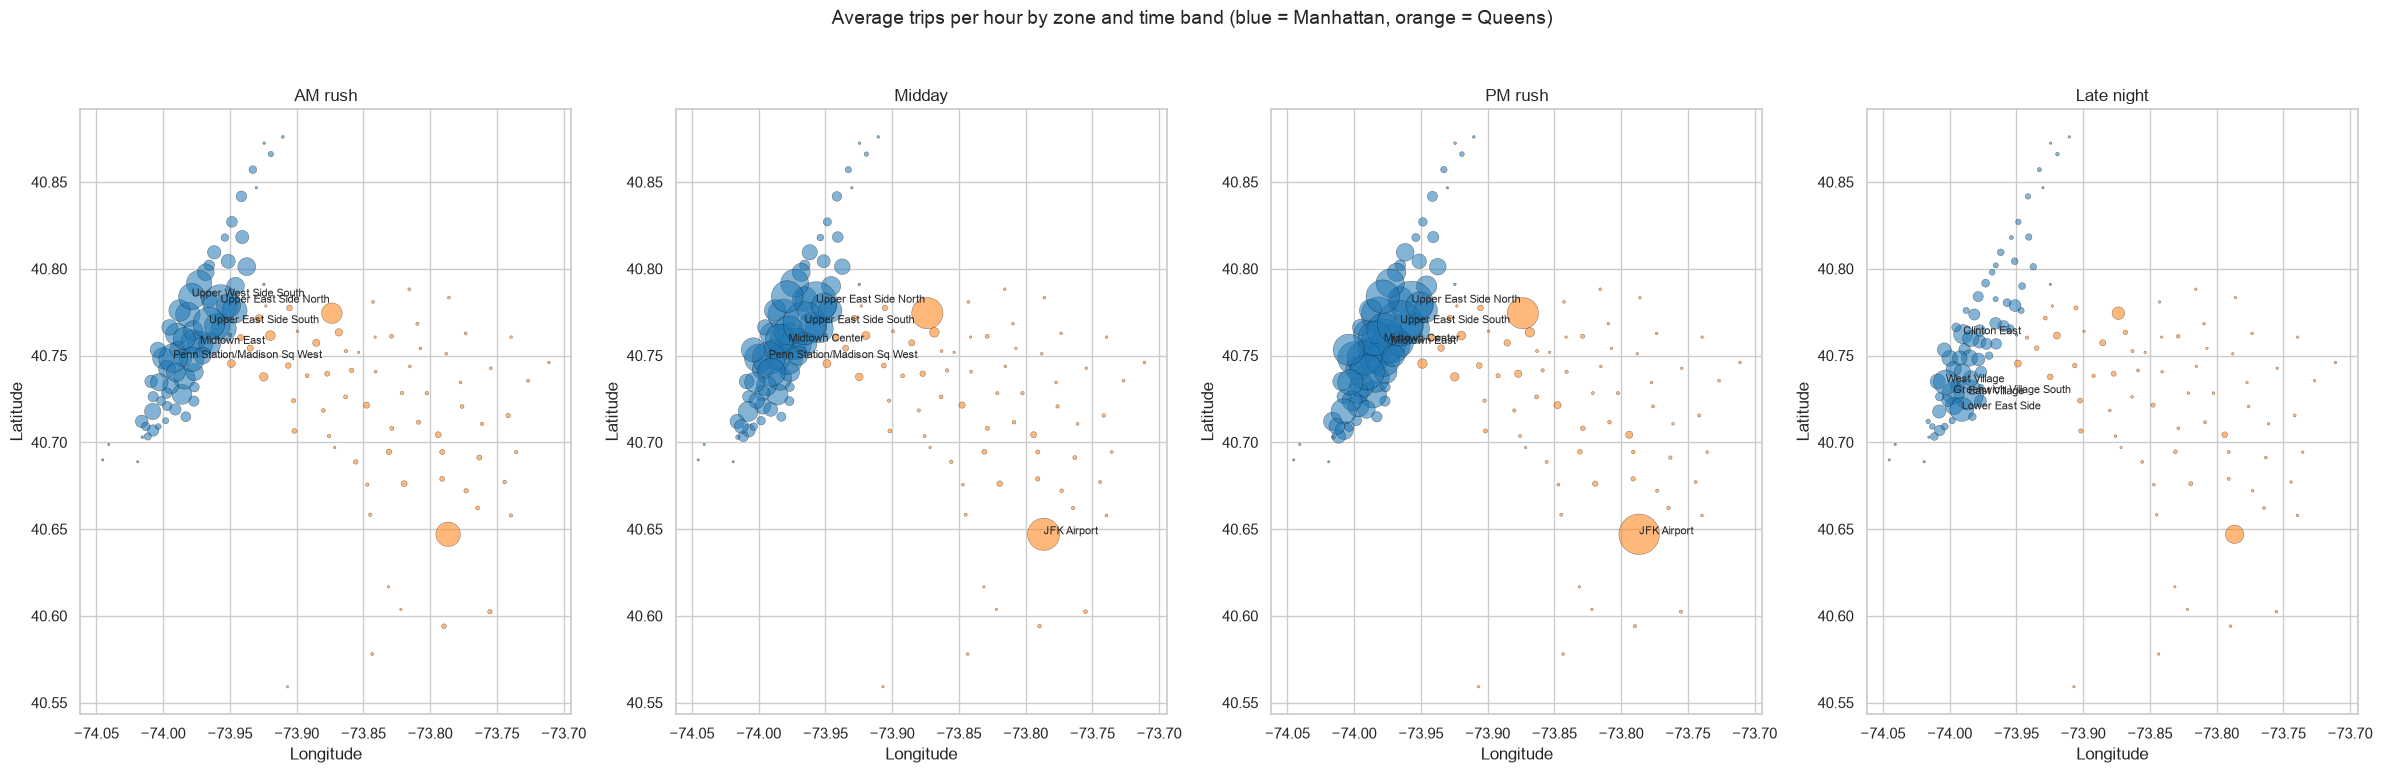

In [11]:
map_bands = ["AM rush", "Midday", "PM rush", "Late night"]

band_avg = df.groupby(["PULocationID", "time_band"])["trip_count"].mean().reset_index()
band_avg = band_avg.merge(zones, on="PULocationID")

fig, axes = plt.subplots(1, 4, figsize=(24, 8))
for i, band in enumerate(map_bands):
    ax = axes[i]
    data = band_avg[band_avg["time_band"] == band]
    ax.scatter(data["longitude"], data["latitude"],
               s=data["trip_count"] * 2.5 + 3,
               c=data["borough"].map(BOROUGH_COLORS),
               alpha=0.55, edgecolor="black", linewidth=0.3)

    top5 = data.sort_values("trip_count", ascending=False).head(5)
    for _, row in top5.iterrows():
        ax.annotate(row["zone_name"], (row["longitude"], row["latitude"]), fontsize=8)

    ax.set_title(band)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect(1.3)

plt.suptitle("Average trips per hour by zone and time band (blue = Manhattan, orange = Queens)", fontsize=14)
save_fig("C6_demand_maps_by_time_band")

In [12]:
# Top 5 zones in each time band
for band in TIME_BANDS:
    data = band_avg[band_avg["time_band"] == band].sort_values("trip_count", ascending=False).head(5)
    print(band + ":", ", ".join(data["zone_name"] + " (" + data["trip_count"].round(0).astype(int).astype(str) + ")"))

Late night: East Village (184), West Village (124), Lower East Side (117), Greenwich Village South (102), Clinton East (76)
Early morning: JFK Airport (98), Penn Station/Madison Sq West (71), Clinton East (56), Garment District (47), Upper East Side North (44)
AM rush: Upper East Side North (269), Upper East Side South (212), Penn Station/Madison Sq West (171), Upper West Side South (141), Midtown East (136)
Midday: Upper East Side South (381), Upper East Side North (365), Midtown Center (281), Penn Station/Madison Sq West (219), JFK Airport (214)
PM rush: Upper East Side South (425), Midtown Center (421), Upper East Side North (384), JFK Airport (339), Midtown East (310)
Evening: Midtown Center (341), JFK Airport (324), Times Sq/Theatre District (283), Lincoln Square East (263), Upper East Side South (257)


**Finding:** Hotspots move: Upper East/West Side in the AM rush, Midtown and JFK from midday, East Village / West Village / Lower East Side late at night.

## C7. Zone tiers (High ≥ 50, Medium 10-50, Low 1-10, Near-empty < 1 trips per hour)

In [13]:
def get_tier(avg):
    if avg < 1:
        return "Near-empty"
    elif avg < 10:
        return "Low"
    elif avg < 50:
        return "Medium"
    else:
        return "High"


zone_stats["tier"] = zone_stats["avg_per_hour"].apply(get_tier)
TIER_ORDER = ["High", "Medium", "Low", "Near-empty"]

tier_summary = zone_stats.groupby("tier").agg(
    zones=("PULocationID", "count"),
    manhattan_zones=("borough", lambda s: (s == "Manhattan").sum()),
    queens_zones=("borough", lambda s: (s == "Queens").sum()),
    total_trips=("total_trips", "sum"),
    avg_zero_share=("zero_share", "mean"),
).reindex(TIER_ORDER)
tier_summary["share_of_trips_%"] = (tier_summary["total_trips"] / tier_summary["total_trips"].sum() * 100).round(1)
tier_summary["avg_zero_share"] = tier_summary["avg_zero_share"].round(2)
tier_summary

,zones,manhattan_zones,queens_zones,total_trips,avg_zero_share,share_of_trips_%
tier,,,,,,
High,39,37,2,18842915,0.01,86.7
Medium,24,20,4,2356600,0.02,10.8
Low,35,4,31,463733,0.22,2.1
Near-empty,40,8,32,64869,0.74,0.3


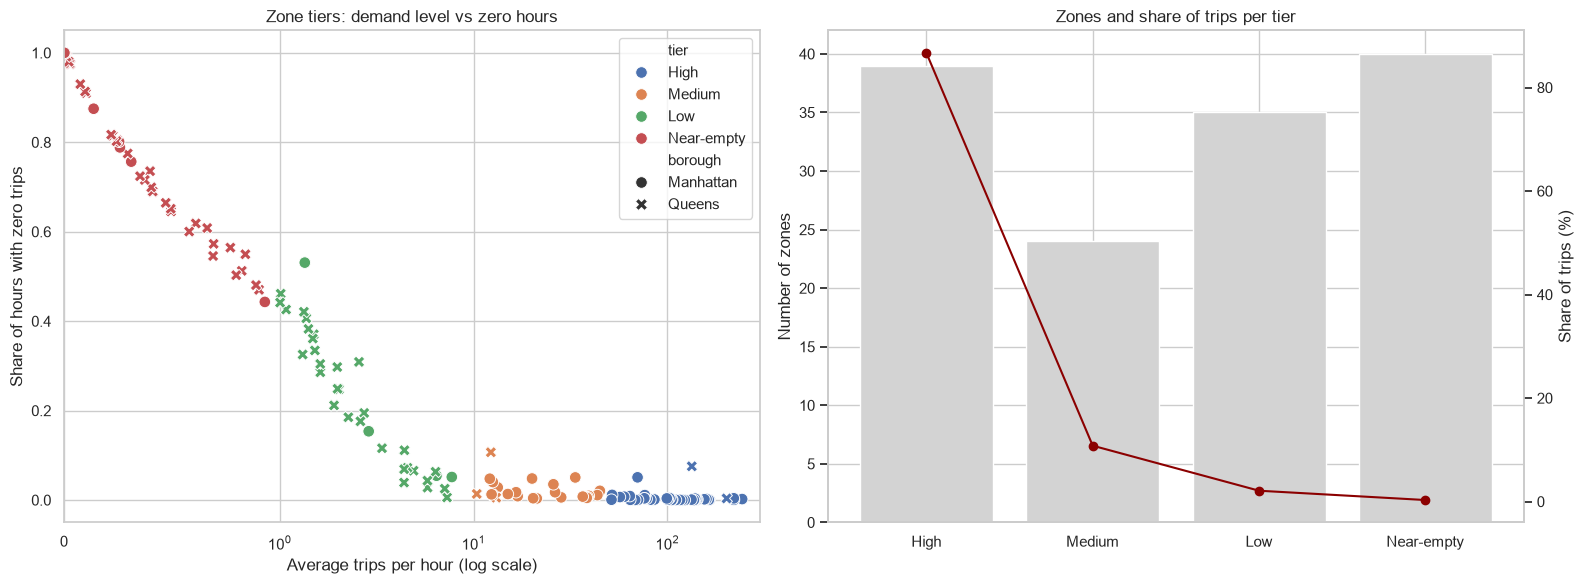

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=zone_stats, x="avg_per_hour", y="zero_share", hue="tier",
                hue_order=TIER_ORDER, style="borough", s=70, ax=axes[0])
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set_xlim(0, 300)
axes[0].set_xlabel("Average trips per hour (log scale)")
axes[0].set_ylabel("Share of hours with zero trips")
axes[0].set_title("Zone tiers: demand level vs zero hours")

axes[1].bar(tier_summary.index, tier_summary["zones"], color="lightgray", label="Number of zones")
axes[1].set_ylabel("Number of zones")
ax2 = axes[1].twinx()
ax2.plot(tier_summary.index, tier_summary["share_of_trips_%"], color="darkred", marker="o", label="Share of trips (%)")
ax2.set_ylabel("Share of trips (%)")
ax2.grid(False)
axes[1].set_title("Zones and share of trips per tier")

save_fig("C7_zone_tiers")

**Finding:** 39 High zones carry 86.7% of trips. 40 Near-empty zones (mostly Queens) carry 0.3% and have zero trips in 74% of hours.

## C8. Zone clusters by weekly demand shape (k-means, holidays and near-empty zones left out)

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

active_ids = zone_stats[zone_stats["tier"] != "Near-empty"]["PULocationID"]
normal_days = df[(df["is_holiday"] == False) & (df["PULocationID"].isin(active_ids))]

# Rows = zones, columns = (day_of_week, hour) -> 168 columns
weekly = normal_days.groupby(["PULocationID", "day_of_week", "hour"])["trip_count"].mean().unstack(["day_of_week", "hour"])

# Turn each row into shares so that only the shape matters
weekly_shape = weekly.div(weekly.sum(axis=1), axis=0)
print("Zones clustered:", weekly_shape.shape[0], "| profile length:", weekly_shape.shape[1])

Zones clustered: 98 | profile length: 168


k = 2 | silhouette = 0.276
k = 3 | silhouette = 0.301
k = 4 | silhouette = 0.266
k = 5 | silhouette = 0.232
k = 6 | silhouette = 0.236
k = 7 | silhouette = 0.22
k = 8 | silhouette = 0.219


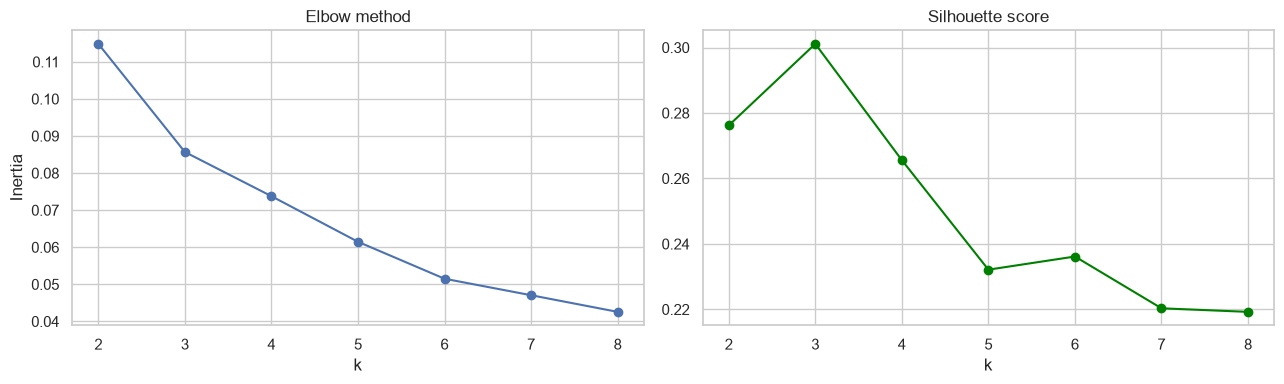

In [16]:
# Try k = 2 to 8 and compare inertia (elbow) and silhouette score
k_values = range(2, 9)
inertias = []
silhouettes = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(weekly_shape)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(weekly_shape, labels))
    print("k =", k, "| silhouette =", round(silhouettes[-1], 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o", color="green")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
save_fig("C8_choosing_k")

In [17]:
# k = 3 has the highest silhouette score. k = 4 only splits off a single zone (Maspeth),
# so 3 clusters is the clearest grouping.
K = 3

# Names chosen after looking at the weekly shapes and the zones in each cluster below
CLUSTER_NAMES = {
    0: "Residential (morning commute)",
    1: "Nightlife (late night and weekends)",
    2: "Core business and airports (daytime)",
}

kmeans = KMeans(n_clusters=K, n_init=20, random_state=42)
cluster_ids = kmeans.fit_predict(weekly_shape)
cluster_table = pd.DataFrame({"PULocationID": weekly_shape.index, "cluster": cluster_ids})
cluster_table = cluster_table.merge(zone_stats[["PULocationID", "zone_name", "zone_label", "borough",
                                                "service_zone", "total_trips", "tier"]], on="PULocationID")

# Show the busiest zones in each cluster to help name it
for c in range(K):
    members = cluster_table[cluster_table["cluster"] == c].sort_values("total_trips", ascending=False)
    print(CLUSTER_NAMES[c], "-", len(members), "zones:", ", ".join(members["zone_name"].head(8)))

Residential (morning commute) - 30 zones: Yorkville East, East Harlem North, Central Harlem North, Washington Heights South, Astoria, Hamilton Heights, Sunnyside, Jackson Heights
Nightlife (late night and weekends) - 10 zones: East Village, West Village, Greenwich Village South, Lower East Side, Little Italy/NoLiTa, Meatpacking/West Village West, Alphabet City, Seaport
Core business and airports (daytime) - 58 zones: Upper East Side South, Midtown Center, Upper East Side North, JFK Airport, Penn Station/Madison Sq West, Midtown East, Lincoln Square East, Times Sq/Theatre District


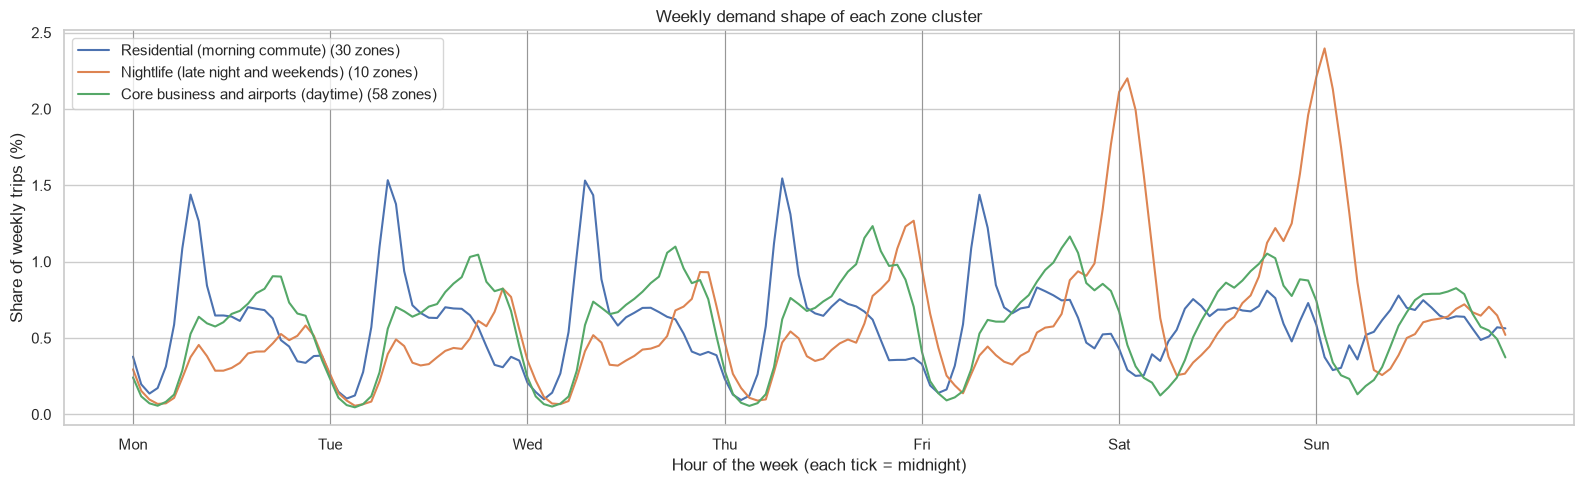

In [18]:
# Average weekly shape of each cluster
fig, ax = plt.subplots(figsize=(16, 5))
for c in range(K):
    member_ids = cluster_table[cluster_table["cluster"] == c]["PULocationID"]
    avg_shape = weekly_shape.loc[member_ids].mean() * 100
    ax.plot(range(168), avg_shape.values, label=CLUSTER_NAMES[c] + " (" + str(len(member_ids)) + " zones)")

ax.set_xticks(range(0, 168, 24))
ax.set_xticklabels(DAY_NAMES)
for x in range(0, 168, 24):
    ax.axvline(x, color="gray", linewidth=0.5)
ax.set_xlabel("Hour of the week (each tick = midnight)")
ax.set_ylabel("Share of weekly trips (%)")
ax.set_title("Weekly demand shape of each zone cluster")
ax.legend()
save_fig("C8_cluster_weekly_profiles")

In [19]:
cluster_table["cluster_name"] = cluster_table["cluster"].map(CLUSTER_NAMES)

cluster_summary = cluster_table.groupby("cluster_name").agg(
    zones=("PULocationID", "count"),
    manhattan=("borough", lambda s: (s == "Manhattan").sum()),
    queens=("borough", lambda s: (s == "Queens").sum()),
    total_trips=("total_trips", "sum"),
)
cluster_summary["share_of_trips_%"] = (cluster_summary["total_trips"] / zone_stats["total_trips"].sum() * 100).round(1)
cluster_summary

,zones,manhattan,queens,total_trips,share_of_trips_%
cluster_name,,,,,
Core business and airports (daytime),58,46,12,18314351,84.3
Nightlife (late night and weekends),10,8,2,2315770,10.7
Residential (morning commute),30,7,23,1033127,4.8


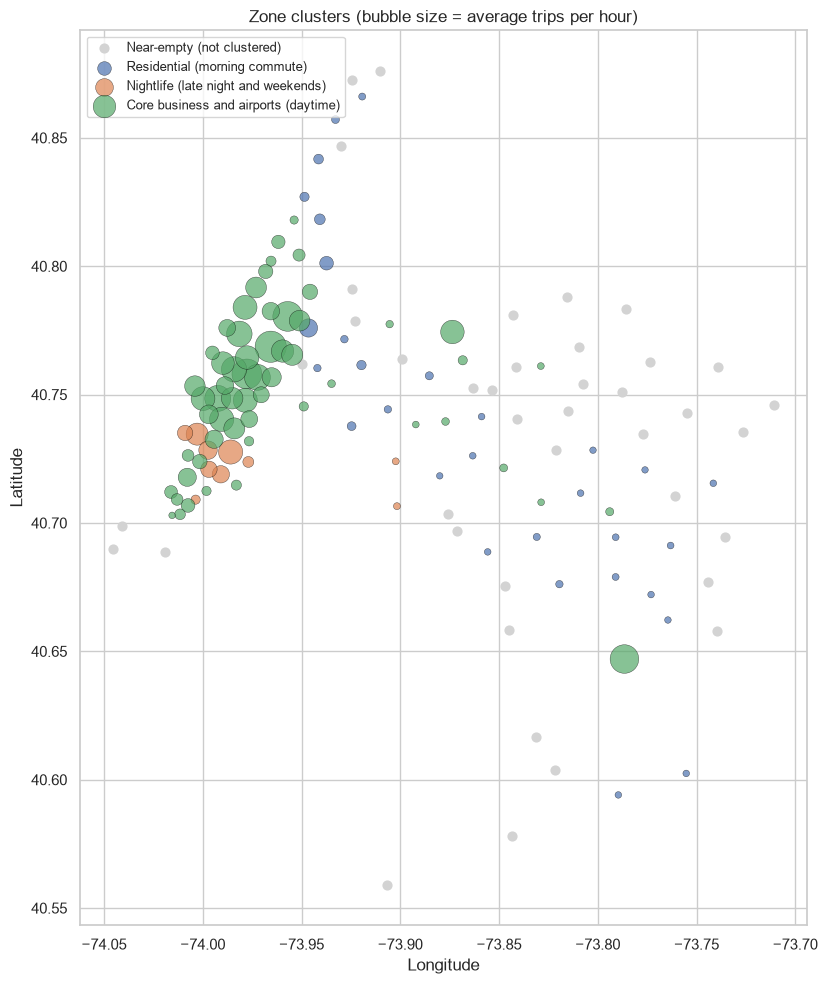

In [20]:
# Map of the clusters (near-empty zones in light gray)
map_data = zone_stats.merge(cluster_table[["PULocationID", "cluster_name"]], on="PULocationID", how="left")
map_data["cluster_name"] = map_data["cluster_name"].fillna("Near-empty (not clustered)")

plt.figure(figsize=(10, 10))
empty = map_data[map_data["cluster_name"] == "Near-empty (not clustered)"]
plt.scatter(empty["longitude"], empty["latitude"], color="lightgray", s=40, label="Near-empty (not clustered)")

for name in CLUSTER_NAMES.values():
    data = map_data[map_data["cluster_name"] == name]
    plt.scatter(data["longitude"], data["latitude"], s=data["avg_per_hour"] * 2 + 20,
                alpha=0.7, edgecolor="black", linewidth=0.3, label=name)

plt.gca().set_aspect(1.3)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Zone clusters (bubble size = average trips per hour)")
plt.legend(loc="upper left", fontsize=9)
save_fig("C8_cluster_map")

**Finding:** 3 zone types: Core business and airports (58 zones, 84% of trips, daytime), Nightlife (10 zones, 11%, Fri/Sat nights), Residential (30 zones, 5%, weekday 07-09 peak).

## C10. Demand correlation between the 30 busiest zones

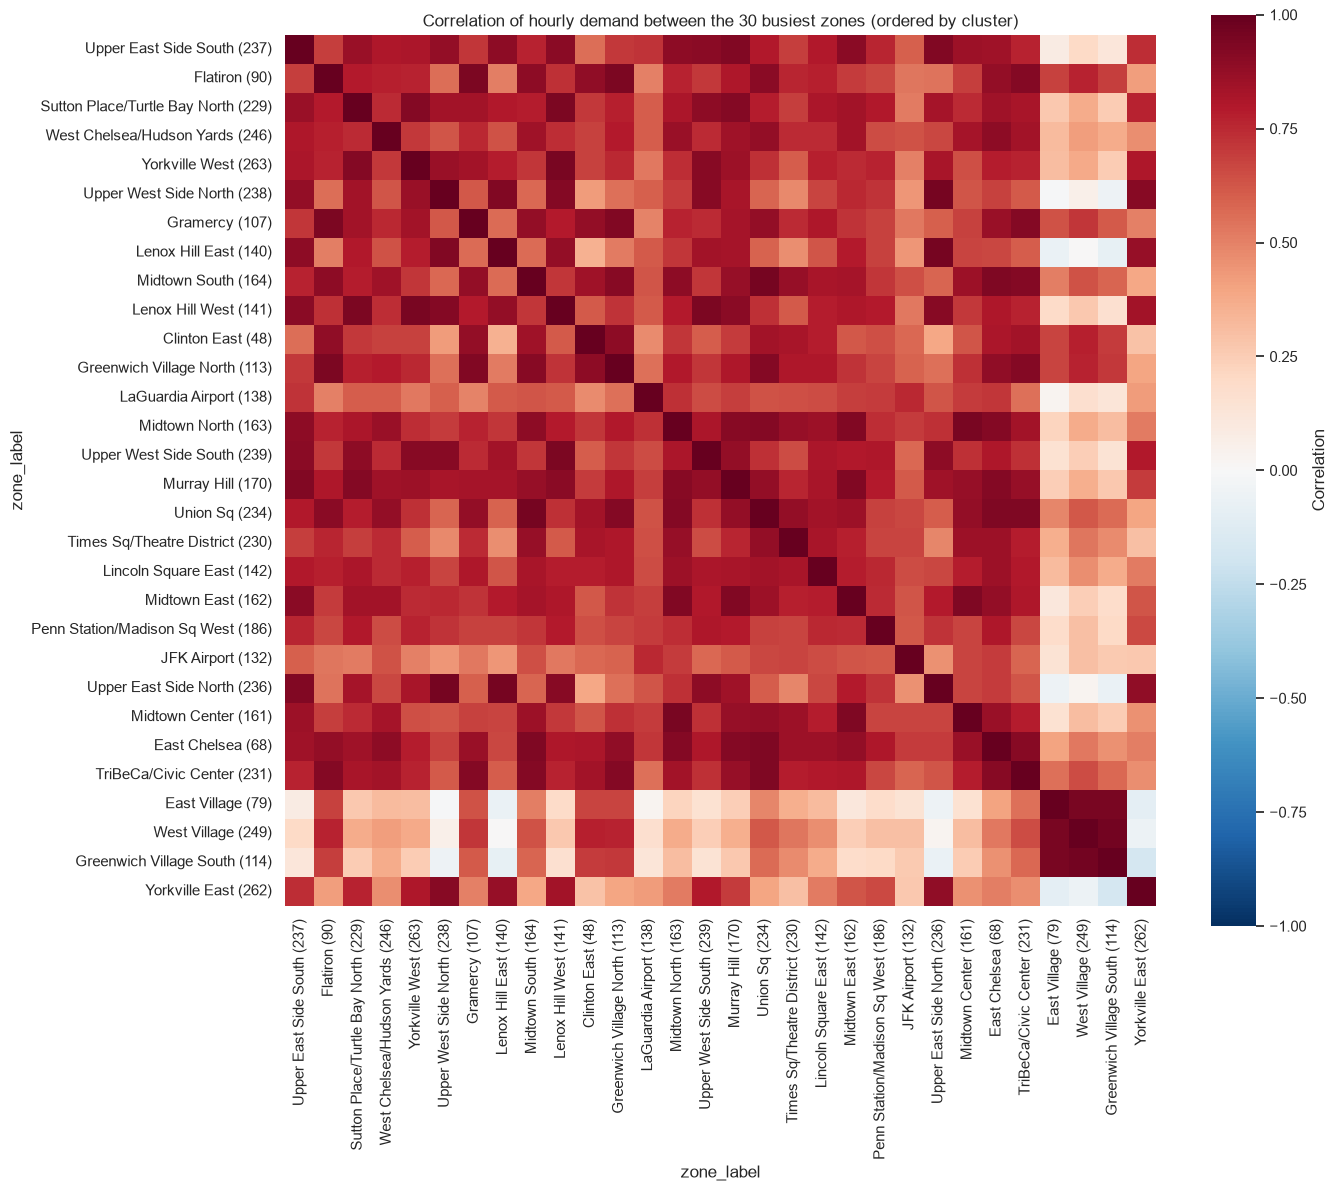

In [21]:
top30 = zone_stats.head(30)[["PULocationID", "zone_label"]].merge(cluster_table[["PULocationID", "cluster_name"]], on="PULocationID")
top30 = top30.sort_values("cluster_name")

hourly_top30 = df[df["PULocationID"].isin(top30["PULocationID"])].pivot_table(
    index="pickup_hour", columns="zone_label", values="trip_count")
hourly_top30 = hourly_top30[top30["zone_label"]]   # order the columns by cluster

zone_corr = hourly_top30.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(zone_corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Correlation"}, xticklabels=True, yticklabels=True)
plt.title("Correlation of hourly demand between the 30 busiest zones (ordered by cluster)")
save_fig("C10_zone_correlation_heatmap")

In [22]:
# Average correlation for pairs in the same cluster vs different clusters
same_cluster = []
diff_cluster = []
labels = list(top30["zone_label"])
clusters = list(top30["cluster_name"])
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        value = zone_corr.loc[labels[i], labels[j]]
        if clusters[i] == clusters[j]:
            same_cluster.append(value)
        else:
            diff_cluster.append(value)

print("Average correlation, same cluster:     ", round(np.mean(same_cluster), 2))
print("Average correlation, different cluster:", round(np.mean(diff_cluster), 2))

Average correlation, same cluster:      0.75
Average correlation, different cluster: 0.38


**Finding:** Average correlation is 0.75 within a cluster and 0.38 between clusters.

## H1. Variability per zone (CV = std / mean)

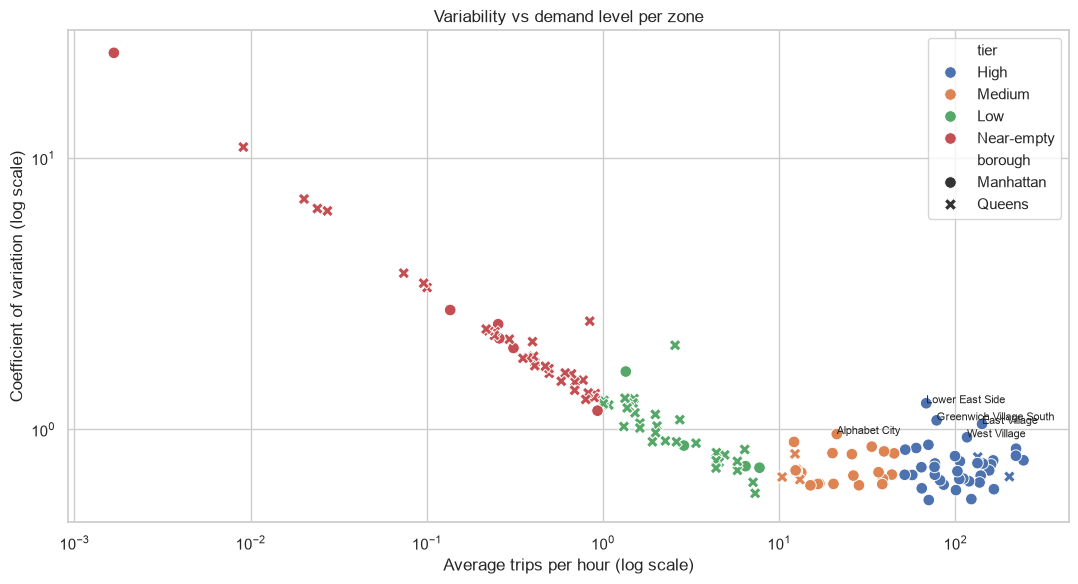

In [23]:
zone_std = df.groupby("PULocationID")["trip_count"].std().rename("std_per_hour").reset_index()
zone_stats = zone_stats.merge(zone_std, on="PULocationID")
zone_stats["cv"] = zone_stats["std_per_hour"] / zone_stats["avg_per_hour"]

plot_data = zone_stats[zone_stats["avg_per_hour"] > 0]

plt.figure(figsize=(11, 6))
sns.scatterplot(data=plot_data, x="avg_per_hour", y="cv", hue="tier", hue_order=TIER_ORDER, style="borough", s=70)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Average trips per hour (log scale)")
plt.ylabel("Coefficient of variation (log scale)")
plt.title("Variability vs demand level per zone")

# Label the 5 most variable zones among High and Medium tier
busy = plot_data[plot_data["tier"].isin(["High", "Medium"])].sort_values("cv", ascending=False).head(5)
for _, row in busy.iterrows():
    plt.annotate(row["zone_name"], (row["avg_per_hour"], row["cv"]), fontsize=8)
save_fig("H1_cv_vs_mean")

In [24]:
print("Median CV by tier:")
print(zone_stats.groupby("tier")["cv"].median().reindex(TIER_ORDER).round(2))
print()
print("Most variable High/Medium zones:")
print(busy[["zone_label", "avg_per_hour", "cv"]].round(2).to_string(index=False))

Median CV by tier:
tier
High          0.73
Medium        0.70
Low           0.97
Near-empty    1.93
Name: cv, dtype: float64

Most variable High/Medium zones:
                   zone_label  avg_per_hour   cv
        Lower East Side (148)         68.23 1.25
Greenwich Village South (114)         78.16 1.08
            East Village (79)        141.47 1.05
            Alphabet City (4)         21.21 0.96
           West Village (249)        116.28 0.94


**Finding:** Busy zones are more stable (median CV ≈ 0.7) than near-empty ones (1.93). Nightlife zones are the most variable busy zones.

## H2. Demand classes (Syntetos-Boylan: ADI cut-off 1.32, CV² cut-off 0.49)

In [25]:
ADI_CUT = 1.32
CV2_CUT = 0.49

rows = []
for zone_id, group in df.groupby("PULocationID"):
    counts = group["trip_count"]
    nonzero = counts[counts > 0]

    if len(nonzero) < 2:
        rows.append({"PULocationID": zone_id, "adi": np.nan, "cv2": np.nan, "demand_class": "No demand"})
        continue

    adi = len(counts) / len(nonzero)
    cv2 = (nonzero.std() / nonzero.mean()) ** 2

    if adi < ADI_CUT and cv2 < CV2_CUT:
        demand_class = "Smooth"
    elif adi < ADI_CUT:
        demand_class = "Erratic"
    elif cv2 < CV2_CUT:
        demand_class = "Intermittent"
    else:
        demand_class = "Lumpy"

    rows.append({"PULocationID": zone_id, "adi": adi, "cv2": cv2, "demand_class": demand_class})

sb_table = pd.DataFrame(rows)
zone_stats = zone_stats.merge(sb_table, on="PULocationID")

print(zone_stats["demand_class"].value_counts())
print()
print(pd.crosstab(zone_stats["tier"], zone_stats["demand_class"]).reindex(TIER_ORDER))

demand_class
Smooth          46
Intermittent    43
Erratic         35
Lumpy           12
No demand        2
Name: count, dtype: int64

demand_class  Erratic  Intermittent  Lumpy  No demand  Smooth
tier                                                         
High               21             0      0          0      18
Medium              7             0      0          0      17
Low                 7             7     10          0      11
Near-empty          0            36      2          2       0


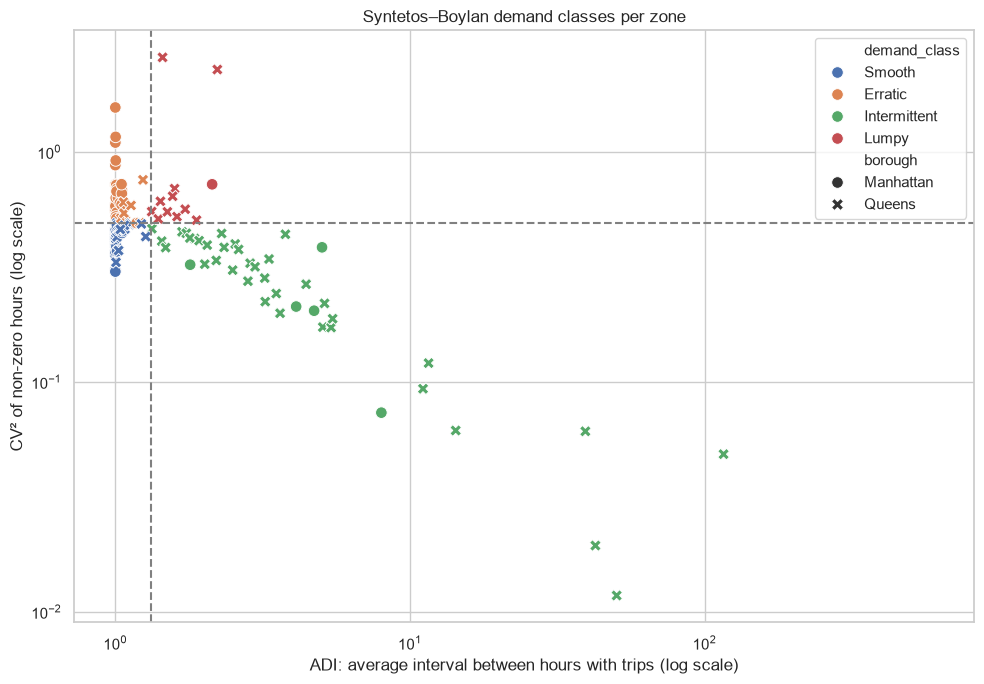

In [26]:
CLASS_ORDER = ["Smooth", "Erratic", "Intermittent", "Lumpy"]
plot_data = zone_stats[zone_stats["demand_class"] != "No demand"]

plt.figure(figsize=(10, 7))
sns.scatterplot(data=plot_data, x="adi", y="cv2", hue="demand_class", hue_order=CLASS_ORDER, style="borough", s=70)
plt.axvline(ADI_CUT, color="gray", linestyle="--")
plt.axhline(CV2_CUT, color="gray", linestyle="--")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("ADI: average interval between hours with trips (log scale)")
plt.ylabel("CV² of non-zero hours (log scale)")
plt.title("Syntetos–Boylan demand classes per zone")
save_fig("H2_demand_classes")

**Finding:** 46 Smooth, 35 Erratic, 43 Intermittent, 12 Lumpy. All High/Medium zones are Smooth or Erratic; 36 of 40 Near-empty zones are Intermittent.

## H6. Predictability by hour and weekday (CV of each slot across weeks)

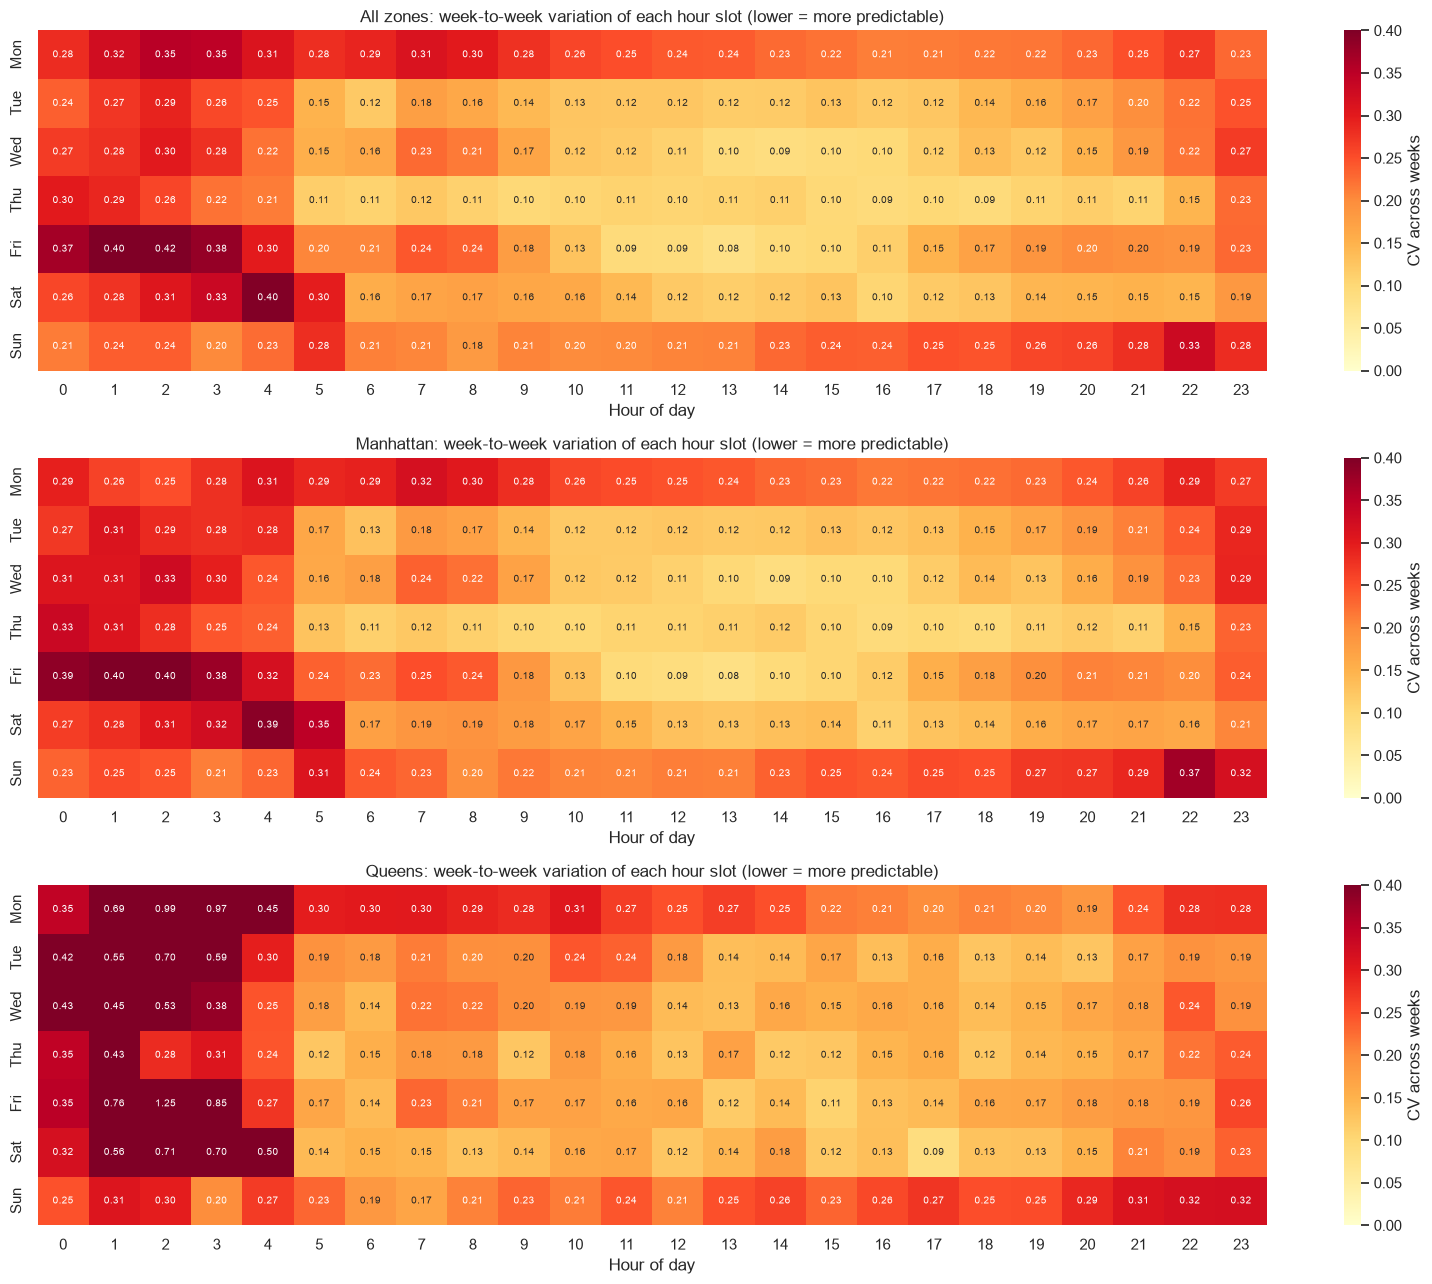

In [27]:
normal_hours = df[(df["is_holiday"] == False) & (df["is_dst_hour"] == False)]


def slot_cv_table(data):
    # Total trips per clock hour, then CV of each (weekday, hour) slot across weeks
    totals = data.groupby(["pickup_hour", "day_of_week", "hour"])["trip_count"].sum().reset_index()
    cv = totals.groupby(["day_of_week", "hour"])["trip_count"].agg(lambda s: s.std() / s.mean())
    table = cv.unstack("hour")
    table.index = DAY_NAMES
    return table


fig, axes = plt.subplots(3, 1, figsize=(16, 13))
groups = {
    "All zones": normal_hours,
    "Manhattan": normal_hours[normal_hours["borough"] == "Manhattan"],
    "Queens": normal_hours[normal_hours["borough"] == "Queens"],
}
slot_cv = {}
for i, (name, data) in enumerate(groups.items()):
    slot_cv[name] = slot_cv_table(data)
    sns.heatmap(slot_cv[name], cmap="YlOrRd", annot=True, fmt=".2f", annot_kws={"size": 7},
                vmin=0, vmax=0.4, ax=axes[i], cbar_kws={"label": "CV across weeks"})
    axes[i].set_title(name + ": week-to-week variation of each hour slot (lower = more predictable)")
    axes[i].set_xlabel("Hour of day")
    axes[i].set_ylabel("")
save_fig("H6_predictability_heatmap")

In [28]:
all_cv = slot_cv["All zones"].stack()
print("Most predictable slots:")
print(all_cv.sort_values().head(5).round(3))
print()
print("Least predictable slots:")
print(all_cv.sort_values(ascending=False).head(5).round(3))
print()
print("Average slot CV  -  Manhattan:", round(slot_cv["Manhattan"].values.mean(), 3),
      "| Queens:", round(slot_cv["Queens"].values.mean(), 3))

Most predictable slots:
     hour
Fri  13      0.083
Wed  14      0.091
Fri  12      0.094
Thu  18      0.094
     16      0.095
dtype: float64

Least predictable slots:
     hour
Fri  2       0.425
     1       0.402
Sat  4       0.398
Fri  3       0.382
     0       0.370
dtype: float64

Average slot CV  -  Manhattan: 0.206 | Queens: 0.253


**Finding:** Weekday daytime is most predictable (CV ≈ 0.1). Late nights, Mondays, Sundays and Queens are the least predictable.

## Save zone tables

In [29]:
tier_columns = ["PULocationID", "zone_name", "borough", "service_zone", "total_trips",
                "avg_per_hour", "zero_share", "tier", "cv", "adi", "cv2", "demand_class"]
zone_stats[tier_columns].round(4).to_csv(TABLE_DIR + "/zone_tiers.csv", index=False)

clusters_out = zone_stats[["PULocationID", "zone_name", "borough", "service_zone", "tier"]].merge(
    cluster_table[["PULocationID", "cluster", "cluster_name"]], on="PULocationID", how="left")
clusters_out["cluster"] = clusters_out["cluster"].astype("Int64")   # whole numbers; blank for near-empty zones
clusters_out["cluster_name"] = clusters_out["cluster_name"].fillna("Near-empty (not clustered)")
clusters_out.to_csv(TABLE_DIR + "/zone_clusters.csv", index=False)

print("Saved zone_tiers.csv and zone_clusters.csv")

Saved zone_tiers.csv and zone_clusters.csv


---
# 2. Demand over time and anomalies (#60)

In [30]:
# Federal holidays in the data (Labor Day, 1 Sep, is in the dropped first week)
HOLIDAYS = {
    "2025-10-13": "Columbus Day",
    "2025-11-11": "Veterans Day",
    "2025-11-27": "Thanksgiving",
    "2025-12-25": "Christmas",
    "2026-01-01": "New Year's Day",
    "2026-01-19": "MLK Day",
    "2026-02-16": "Presidents' Day",
}
DST_HOUR = pd.Timestamp("2025-11-02 01:00:00")

# Total trips per clock hour: all zones and each borough
hourly = df.groupby("pickup_hour")["trip_count"].sum()
hourly_manhattan = df[df["borough"] == "Manhattan"].groupby("pickup_hour")["trip_count"].sum()
hourly_queens = df[df["borough"] == "Queens"].groupby("pickup_hour")["trip_count"].sum()

# Total trips per day
daily = df.groupby("date")["trip_count"].sum()
print("Hours:", len(hourly), "| Days:", len(daily))

Hours: 4176 | Days: 174


## D1. Hourly demand (red dot = DST hour)

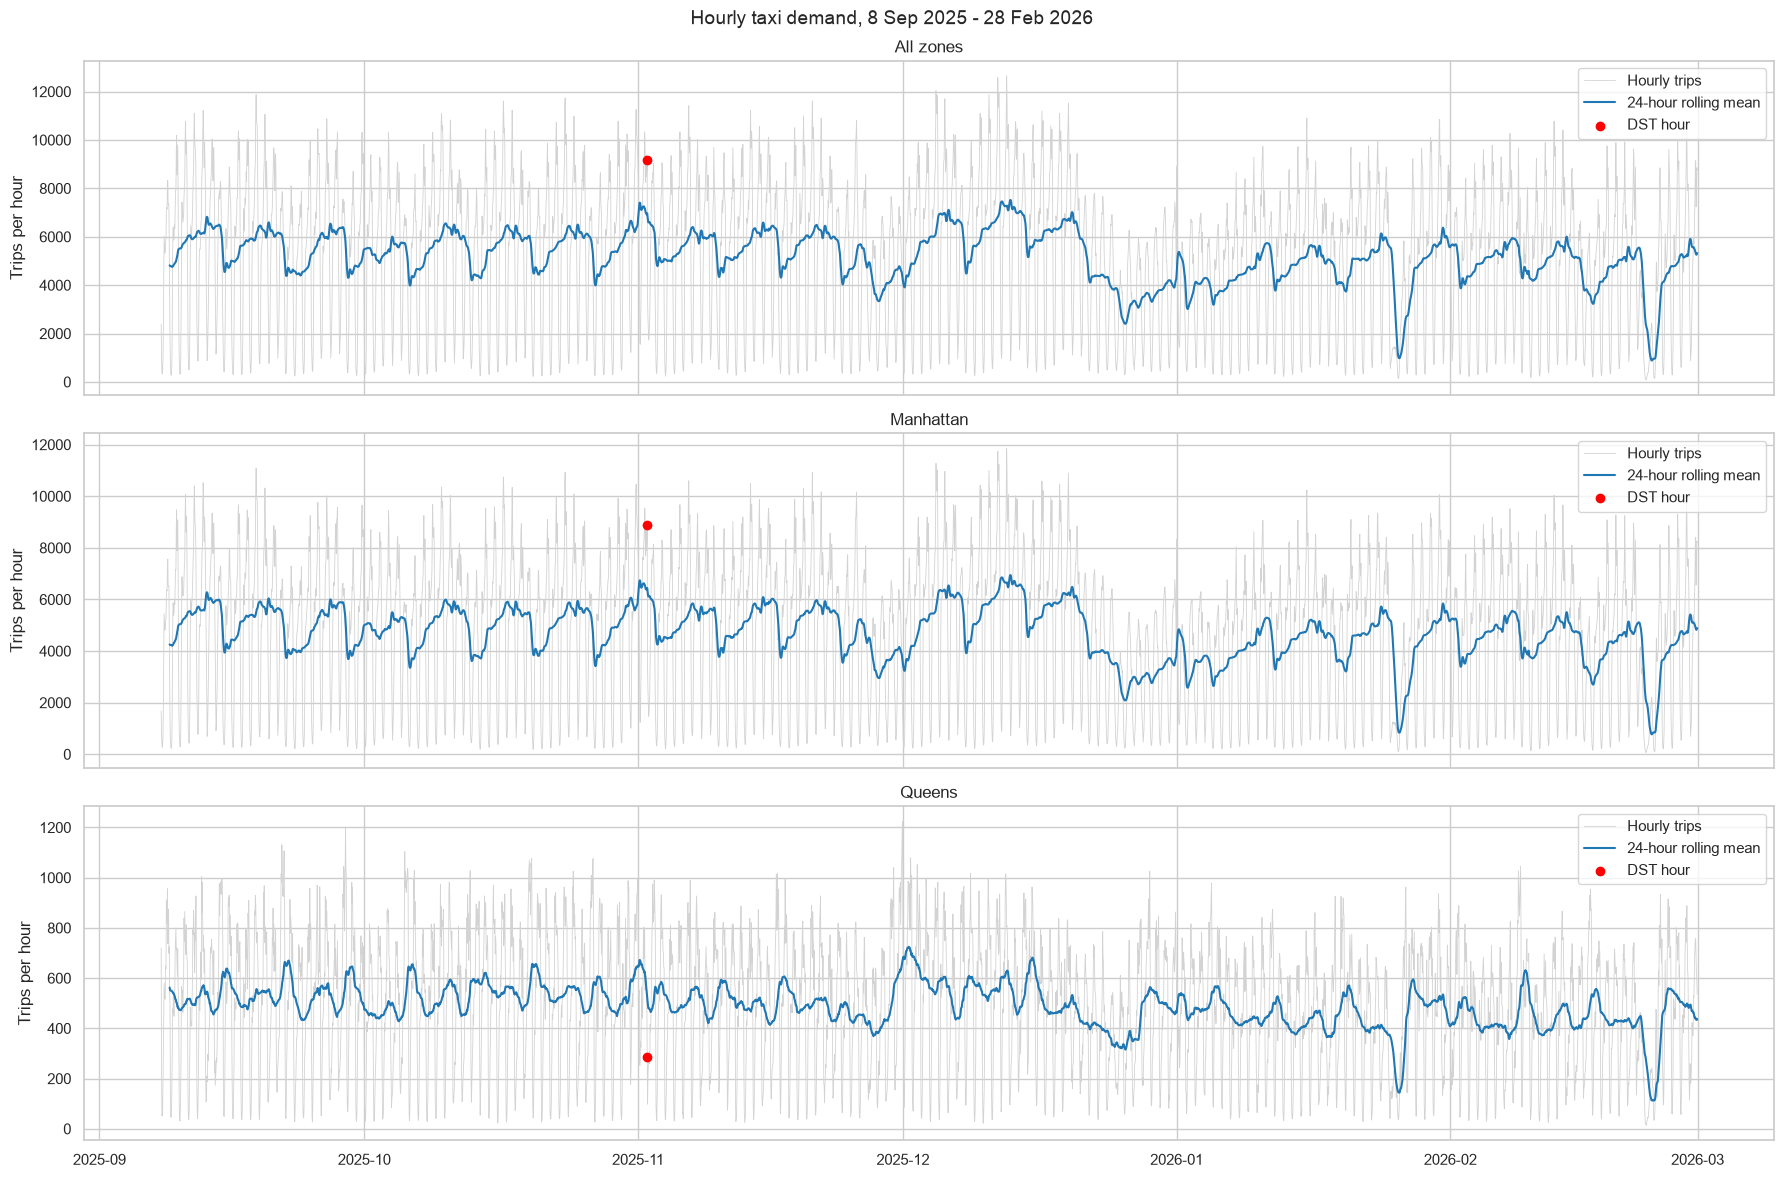

In [31]:
fig, axes = plt.subplots(3, 1, figsize=(18, 12), sharex=True)
series_list = [("All zones", hourly), ("Manhattan", hourly_manhattan), ("Queens", hourly_queens)]

for i, (name, series) in enumerate(series_list):
    axes[i].plot(series.index, series.values, color="lightgray", linewidth=0.6, label="Hourly trips")
    axes[i].plot(series.index, series.rolling(24).mean().values, color="tab:blue", linewidth=1.5, label="24-hour rolling mean")
    axes[i].scatter([DST_HOUR], [series[DST_HOUR]], color="red", zorder=5, label="DST hour")
    axes[i].set_title(name)
    axes[i].set_ylabel("Trips per hour")
    axes[i].legend(loc="upper right")

plt.suptitle("Hourly taxi demand, 8 Sep 2025 - 28 Feb 2026", fontsize=14)
save_fig("D1_hourly_demand")

In [32]:
print("Average trips per hour:", round(hourly.mean()))
print("Busiest hour:", hourly.idxmax(), "-", hourly.max(), "trips")
print("Quietest hour:", hourly.idxmin(), "-", hourly.min(), "trips")

Average trips per hour: 5203
Busiest hour: 2025-12-12 18:00:00 - 12648 trips
Quietest hour: 2026-02-23 04:00:00 - 87 trips


**Finding:** 5,203 trips per hour on average. Busiest hour: Fri 12 Dec 18:00 (12,648). Quietest: 23 Feb 04:00 (87, snowstorm).

## D2. Daily demand, trend and calendar heatmap

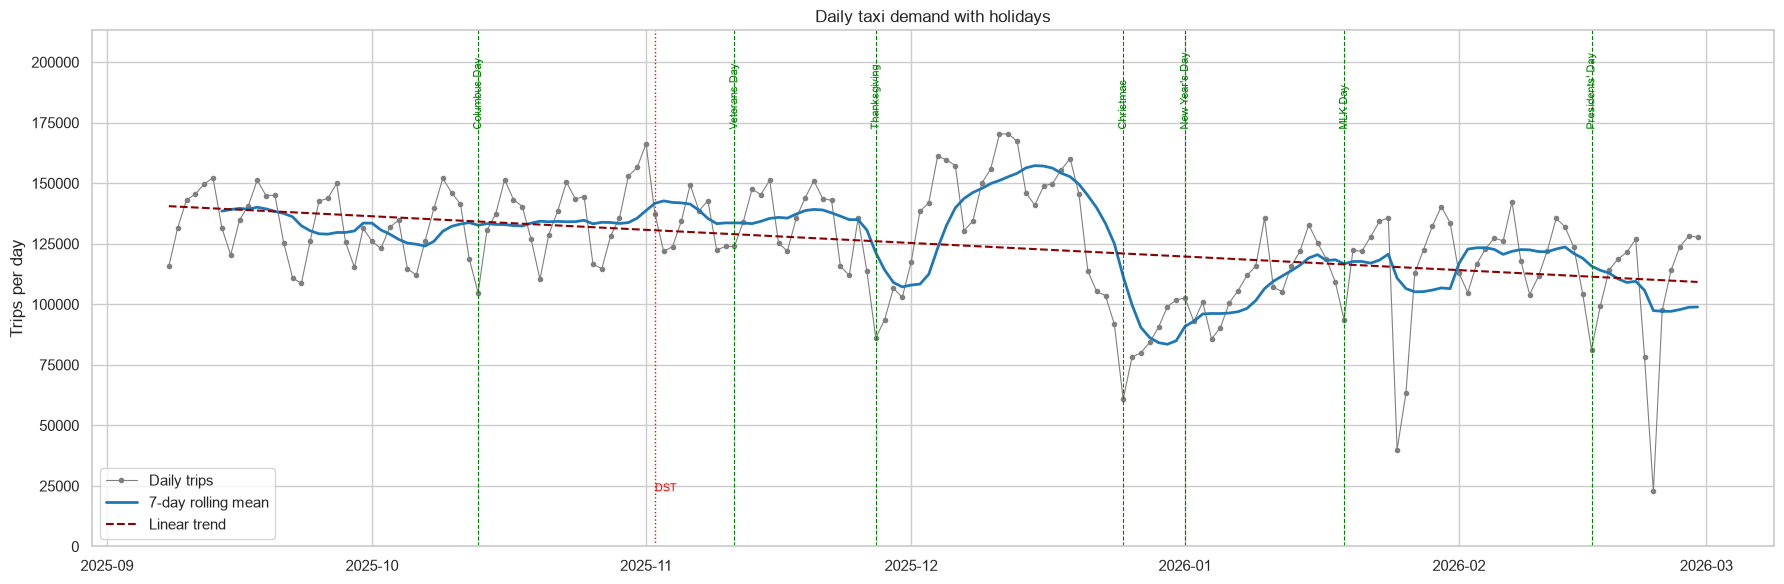

Trend: about -1266 trips per day lost each week
Average trips per day, first 4 weeks: 132729
Average trips per day, last 4 weeks:  112806
Change: -15.0 %


In [33]:
fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(daily.index, daily.values, color="gray", marker=".", linewidth=0.8, label="Daily trips")
ax.plot(daily.index, daily.rolling(7).mean().values, color="tab:blue", linewidth=2, label="7-day rolling mean")

for day, name in HOLIDAYS.items():
    day = pd.Timestamp(day)
    ax.axvline(day, color="green", linestyle="--", linewidth=0.8)
    ax.text(day, daily.max() * 1.01, name, rotation=90, fontsize=8, va="bottom", ha="center", color="green")
ax.axvline(DST_HOUR.normalize(), color="red", linestyle=":", linewidth=1)
ax.text(DST_HOUR.normalize(), daily.min(), "DST", color="red", fontsize=8)

# Straight-line trend over the whole period
day_number = np.arange(len(daily))
slope, intercept = np.polyfit(day_number, daily.values, 1)
ax.plot(daily.index, intercept + slope * day_number, color="darkred", linestyle="--", label="Linear trend")

ax.set_ylabel("Trips per day")
ax.set_ylim(0, daily.max() * 1.25)
ax.set_title("Daily taxi demand with holidays")
ax.legend(loc="lower left")
save_fig("D2_daily_demand_trend")

print("Trend: about", round(slope * 7), "trips per day lost each week")
first_4_weeks = daily.iloc[:28].mean()
last_4_weeks = daily.iloc[-28:].mean()
print("Average trips per day, first 4 weeks:", round(first_4_weeks))
print("Average trips per day, last 4 weeks: ", round(last_4_weeks))
print("Change:", round((last_4_weeks / first_4_weeks - 1) * 100, 1), "%")

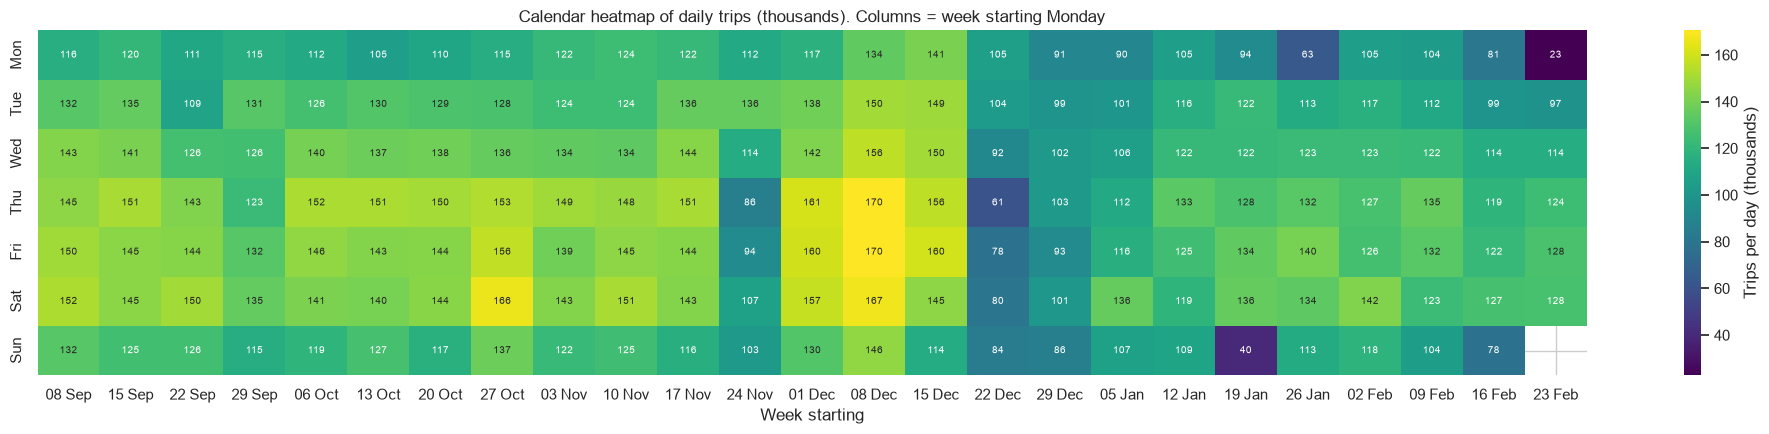

In [34]:
# Calendar heatmap: one cell per day
calendar = daily.reset_index()
calendar.columns = ["date", "trips"]
calendar["weekday"] = calendar["date"].dt.dayofweek
calendar["week_start"] = calendar["date"] - pd.to_timedelta(calendar["weekday"], unit="D")

calendar_grid = calendar.pivot(index="weekday", columns="week_start", values="trips")
calendar_grid.index = DAY_NAMES
calendar_grid.columns = [d.strftime("%d %b") for d in calendar_grid.columns]

plt.figure(figsize=(20, 4.5))
sns.heatmap(calendar_grid / 1000, cmap="viridis", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "Trips per day (thousands)"})
plt.title("Calendar heatmap of daily trips (thousands). Columns = week starting Monday")
plt.xlabel("Week starting")
plt.ylabel("")
save_fig("D2_calendar_heatmap")

**Finding:** The last 4 weeks are 15% below the first 4. Mid-December is the peak; Thanksgiving, Christmas - New Year and the snowstorms are the dips.

## D7. Hour x weekday heatmap (holidays and DST hour left out)

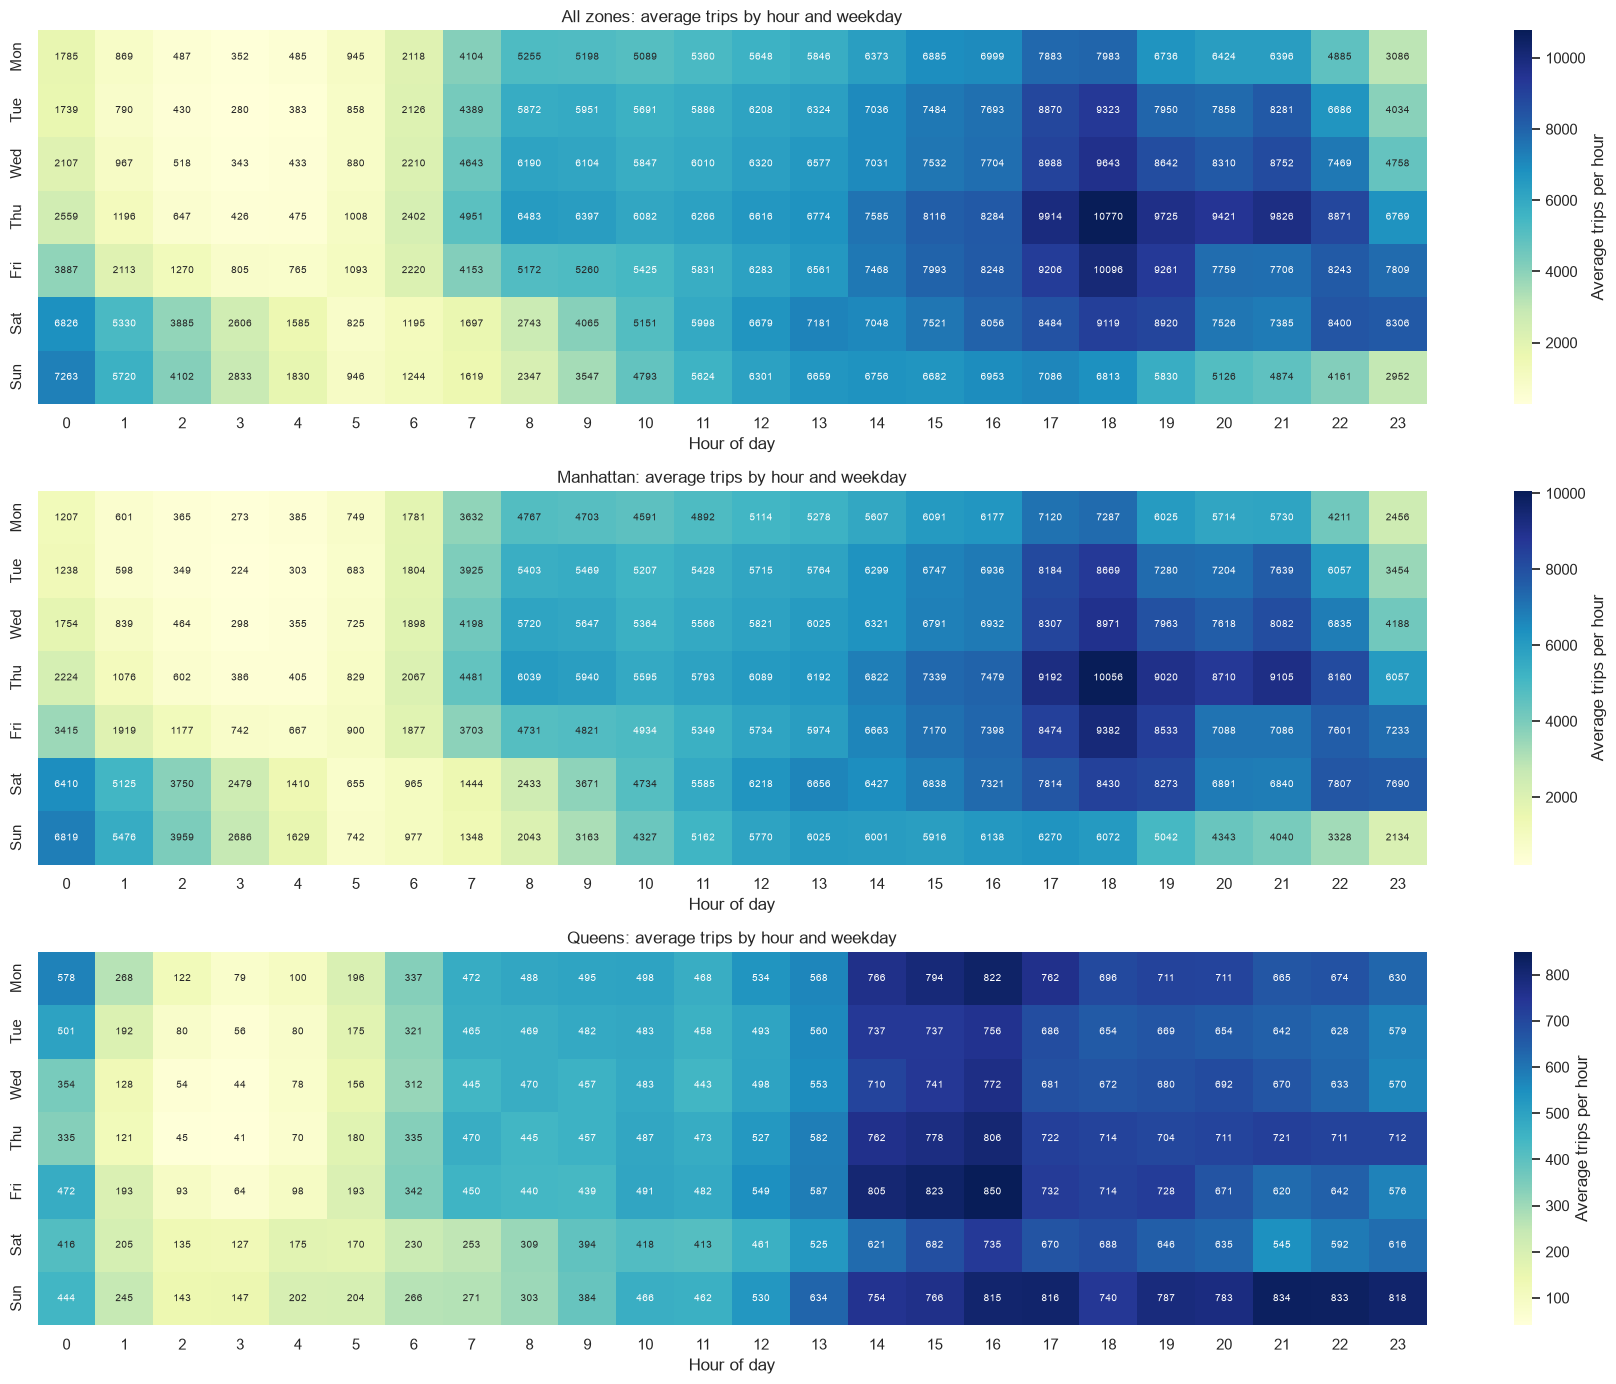

In [35]:
normal_hours = df[(df["is_holiday"] == False) & (df["is_dst_hour"] == False)]


def hour_weekday_table(data):
    # Average total trips for each (weekday, hour) slot
    totals = data.groupby(["pickup_hour", "day_of_week", "hour"])["trip_count"].sum().reset_index()
    table = totals.groupby(["day_of_week", "hour"])["trip_count"].mean().unstack("hour")
    table.index = DAY_NAMES
    return table


week_tables = {
    "All zones": hour_weekday_table(normal_hours),
    "Manhattan": hour_weekday_table(normal_hours[normal_hours["borough"] == "Manhattan"]),
    "Queens": hour_weekday_table(normal_hours[normal_hours["borough"] == "Queens"]),
}

fig, axes = plt.subplots(3, 1, figsize=(18, 14))
for i, (name, table) in enumerate(week_tables.items()):
    sns.heatmap(table, cmap="YlGnBu", annot=True, fmt=".0f", annot_kws={"size": 7},
                ax=axes[i], cbar_kws={"label": "Average trips per hour"})
    axes[i].set_title(name + ": average trips by hour and weekday")
    axes[i].set_xlabel("Hour of day")
    axes[i].set_ylabel("")
save_fig("D7_hour_weekday_heatmap")

In [36]:
table = week_tables["All zones"].stack()
print("Busiest slots:")
print(table.sort_values(ascending=False).head(5).round(0))
print()
print("Quietest slots:")
print(table.sort_values().head(5).round(0))
print()
weekday_night = week_tables["All zones"].loc[["Mon", "Tue", "Wed", "Thu"], [0, 1, 2]].values.mean()
weekend_night = week_tables["All zones"].loc[["Sat", "Sun"], [0, 1, 2]].values.mean()
print("00:00-02:59 average, Mon-Thu:", round(weekday_night), "| Sat-Sun:", round(weekend_night))
print("Queens busiest slot:", week_tables["Queens"].stack().idxmax(), round(week_tables["Queens"].stack().max()))

Busiest slots:
     hour
Thu  18      10770.0
Fri  18      10096.0
Thu  17       9914.0
     21       9826.0
     19       9725.0
dtype: float64

Quietest slots:
     hour
Tue  3       280.0
Wed  3       343.0
Mon  3       352.0
Tue  4       383.0
Thu  3       426.0
dtype: float64

00:00-02:59 average, Mon-Thu: 1175 | Sat-Sun: 5521
Queens busiest slot: ('Fri', np.int64(16)) 850


**Finding:** Busiest slot is Thu 18:00 (10,770/hour). Weekend nights (00-03) are 4.7x busier than weekday nights.

## E5. Anomaly days (vs median of the same weekday within ±4 weeks; robust z > 3)

In [37]:
day_table = daily.reset_index()
day_table.columns = ["date", "trips"]
day_table["weekday"] = day_table["date"].dt.dayofweek
day_table["is_holiday"] = day_table["date"].dt.strftime("%Y-%m-%d").isin(HOLIDAYS.keys())

# Daily weather: citywide average per hour, then summed (rain, snow) or averaged (temperature)
city_weather = df.groupby(["date", "pickup_hour"])[["rain", "snowfall", "apparent_temperature"]].mean().reset_index()
daily_weather = city_weather.groupby("date").agg(
    rain_mm=("rain", "sum"),
    snow_cm=("snowfall", "sum"),
    avg_feels_like_c=("apparent_temperature", "mean"),
).reset_index()
day_table = day_table.merge(daily_weather, on="date")
day_table["is_snow_day"] = day_table["snow_cm"] >= 3

# Normal level = median of the same weekday within 28 days,
# not counting holidays, snowstorm days or the day itself
normal_level = []
for _, row in day_table.iterrows():
    same_weekday = day_table[(day_table["weekday"] == row["weekday"])
                             & (day_table["date"] != row["date"])
                             & (day_table["is_holiday"] == False)
                             & (day_table["is_snow_day"] == False)
                             & ((day_table["date"] - row["date"]).abs() <= pd.Timedelta(days=28))]
    normal_level.append(same_weekday["trips"].median())

day_table["normal"] = normal_level
day_table["deviation"] = day_table["trips"] / day_table["normal"] - 1

# Robust z-score of the deviation
median_dev = day_table["deviation"].median()
mad = (day_table["deviation"] - median_dev).abs().median() * 1.4826
day_table["robust_z"] = (day_table["deviation"] - median_dev) / mad
day_table["is_anomaly"] = day_table["robust_z"].abs() > 3

print("Anomaly days found:", day_table["is_anomaly"].sum(), "of", len(day_table))

Anomaly days found: 18 of 174


In [38]:
# Snow per date, used to spot the day after a snowstorm
snow_by_date = dict(zip(day_table["date"], day_table["snow_cm"]))


# Simple reason for each anomaly day: calendar periods first, then snow
def anomaly_reason(row):
    day = row["date"]
    day_text = day.strftime("%Y-%m-%d")
    snow_today = row["snow_cm"] >= 3
    snow_yesterday = snow_by_date.get(day - pd.Timedelta(days=1), 0) >= 3

    if day_text in HOLIDAYS:
        reason = "Holiday: " + HOLIDAYS[day_text]
    elif pd.Timestamp("2025-12-24") <= day <= pd.Timestamp("2026-01-03"):
        reason = "Christmas - New Year period"
    elif pd.Timestamp("2025-11-28") <= day <= pd.Timestamp("2025-11-30"):
        reason = "Thanksgiving weekend"
    elif pd.Timestamp("2025-12-08") <= day <= pd.Timestamp("2025-12-20") and row["deviation"] > 0:
        reason = "Pre-Christmas busy period"
    elif snow_today:
        return "Snowstorm"
    elif snow_yesterday:
        return "Day after a snowstorm"
    else:
        return "Not explained by holiday or weather"

    if snow_today:
        reason = reason + " (with snow)"
    return reason


anomalies = day_table[day_table["is_anomaly"]].copy()
anomalies["weekday"] = anomalies["date"].dt.day_name().str[:3]
anomalies["reason"] = anomalies.apply(anomaly_reason, axis=1)
anomalies = anomalies.sort_values("deviation")

show_cols = ["date", "weekday", "trips", "normal", "deviation", "rain_mm", "snow_cm", "avg_feels_like_c", "reason"]
anomalies[show_cols].round(2)

,date,weekday,trips,normal,deviation,rain_mm,snow_cm,avg_feels_like_c,reason
168,2026-02-23,Mon,22783,104012.0,-0.78,8.41,14.12,-7.58,Snowstorm
139,2026-01-25,Sun,39961,105663.0,-0.62,13.01,19.13,-15.17,Snowstorm
108,2025-12-25,Thu,60817,144204.5,-0.58,0.00,0.00,-2.21,Holiday: Christmas
80,2025-11-27,Thu,86029,152890.0,-0.44,0.00,0.00,0.06,Holiday: Thanksgiving
110,2025-12-27,Sat,79994,135661.5,-0.41,2.65,4.33,-7.26,Christmas - New Year period (with snow)
81,2025-11-28,Fri,93649,156495.0,-0.40,0.00,0.00,-3.53,Thanksgiving weekend
109,2025-12-26,Fri,78219,129808.5,-0.40,3.21,5.40,-9.27,Christmas - New Year period (with snow)
140,2026-01-26,Mon,63387,104012.0,-0.39,0.00,0.00,-11.43,Day after a snowstorm
116,2026-01-02,Fri,92901,140375.0,-0.34,0.00,0.00,-9.23,Christmas - New Year period
167,2026-02-22,Sun,78195,112866.0,-0.31,6.77,9.02,-3.40,Snowstorm


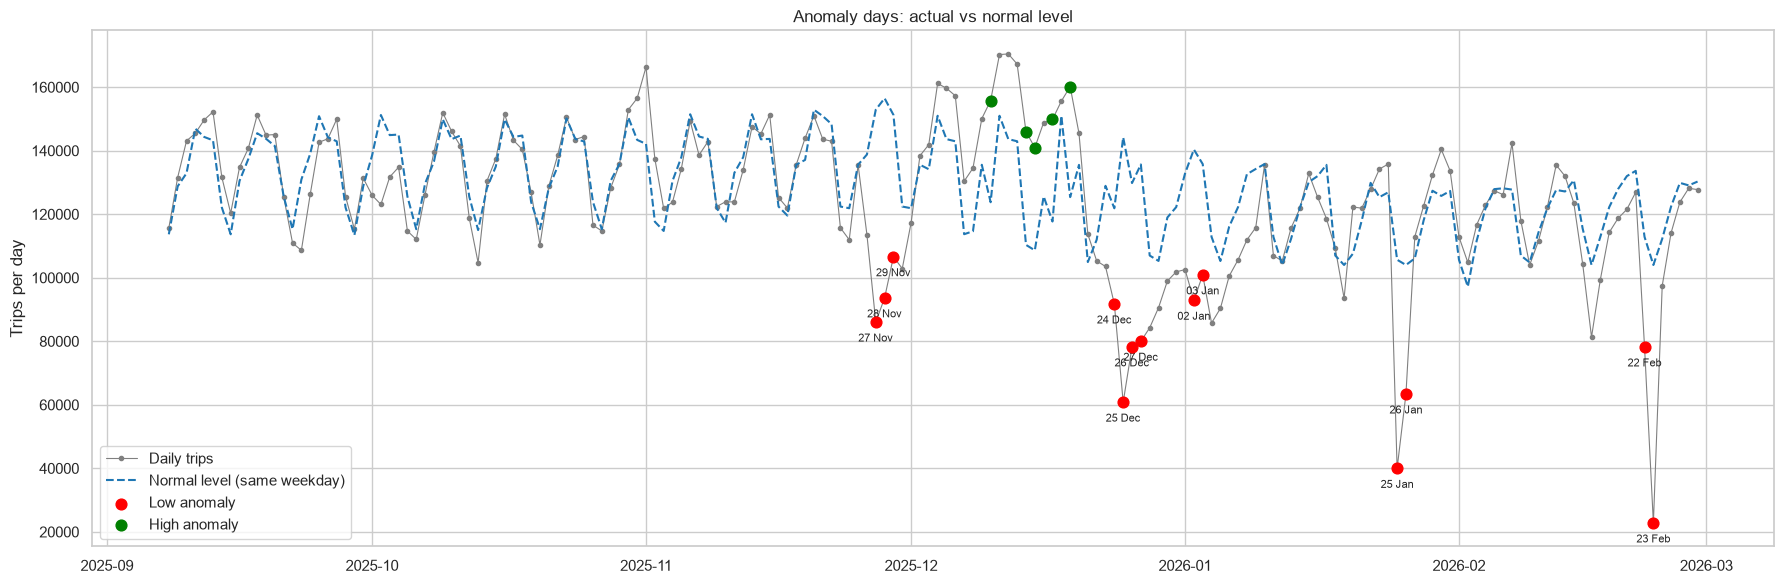

In [39]:
fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(day_table["date"], day_table["trips"], color="gray", marker=".", linewidth=0.8, label="Daily trips")
ax.plot(day_table["date"], day_table["normal"], color="tab:blue", linestyle="--", label="Normal level (same weekday)")

low = anomalies[anomalies["deviation"] < 0]
high = anomalies[anomalies["deviation"] > 0]
ax.scatter(low["date"], low["trips"], color="red", s=60, zorder=5, label="Low anomaly")
ax.scatter(high["date"], high["trips"], color="green", s=60, zorder=5, label="High anomaly")

for _, row in low.iterrows():
    ax.annotate(row["date"].strftime("%d %b"), (row["date"], row["trips"]), fontsize=8,
                xytext=(0, -14), textcoords="offset points", ha="center")

ax.set_ylabel("Trips per day")
ax.set_title("Anomaly days: actual vs normal level")
ax.legend(loc="lower left")
save_fig("E5_anomaly_days")

In [40]:
print(anomalies.groupby("reason")["date"].count().sort_values(ascending=False))

reason
Pre-Christmas busy period                  4
Christmas - New Year period                3
Snowstorm                                  3
Christmas - New Year period (with snow)    2
Thanksgiving weekend                       2
Day after a snowstorm                      1
Holiday: Christmas                         1
Holiday: Thanksgiving                      1
Pre-Christmas busy period (with snow)      1
Name: date, dtype: int64


**Finding:** 18 anomaly days, all explained: holiday periods and snowstorms (low, worst 23 Feb -78%) and the pre-Christmas rush, 10-19 Dec (high, +26-32%).

## E6. Zone spikes (≥ 3x the zone's normal and ≥ 30 extra trips)

In [41]:
zone_normal = df.groupby(["PULocationID", "day_of_week", "hour"])["trip_count"].median().rename("normal").reset_index()
spike_data = df.merge(zone_normal, on=["PULocationID", "day_of_week", "hour"])
spike_data["extra_trips"] = spike_data["trip_count"] - spike_data["normal"]

is_spike = (spike_data["trip_count"] >= 3 * spike_data["normal"].clip(lower=1)) & (spike_data["extra_trips"] >= 30)
spikes = spike_data[is_spike].copy()
print("Spikes found:", len(spikes), "zone-hours in", spikes["PULocationID"].nunique(), "zones")
print()
print("Biggest spikes:")
print(spikes.sort_values("extra_trips", ascending=False)[
    ["pickup_hour", "zone_label", "trip_count", "normal", "extra_trips", "day_type"]].head(15).to_string(index=False))

Spikes found: 738 zone-hours in 73 zones

Biggest spikes:
        pickup_hour                         zone_label  trip_count  normal  extra_trips day_type
2026-01-01 03:00:00                  East Village (79)         558    23.0        535.0  Holiday
2026-01-01 02:00:00                  East Village (79)         547    35.0        512.0  Holiday
2026-01-01 01:00:00                  East Village (79)         450    60.0        390.0  Holiday
2025-11-11 01:00:00            LaGuardia Airport (138)         388    31.0        357.0  Holiday
2025-10-31 02:00:00                  JFK Airport (132)         365    11.0        354.0  Weekday
2025-10-10 00:00:00 Penn Station/Madison Sq West (186)         450   104.0        346.0  Weekday
2025-11-17 22:00:00          Lincoln Square East (142)         483   148.0        335.0  Weekday
2026-01-01 00:00:00                  East Village (79)         428   104.0        324.0  Holiday
2025-12-02 00:00:00            LaGuardia Airport (138)         460   

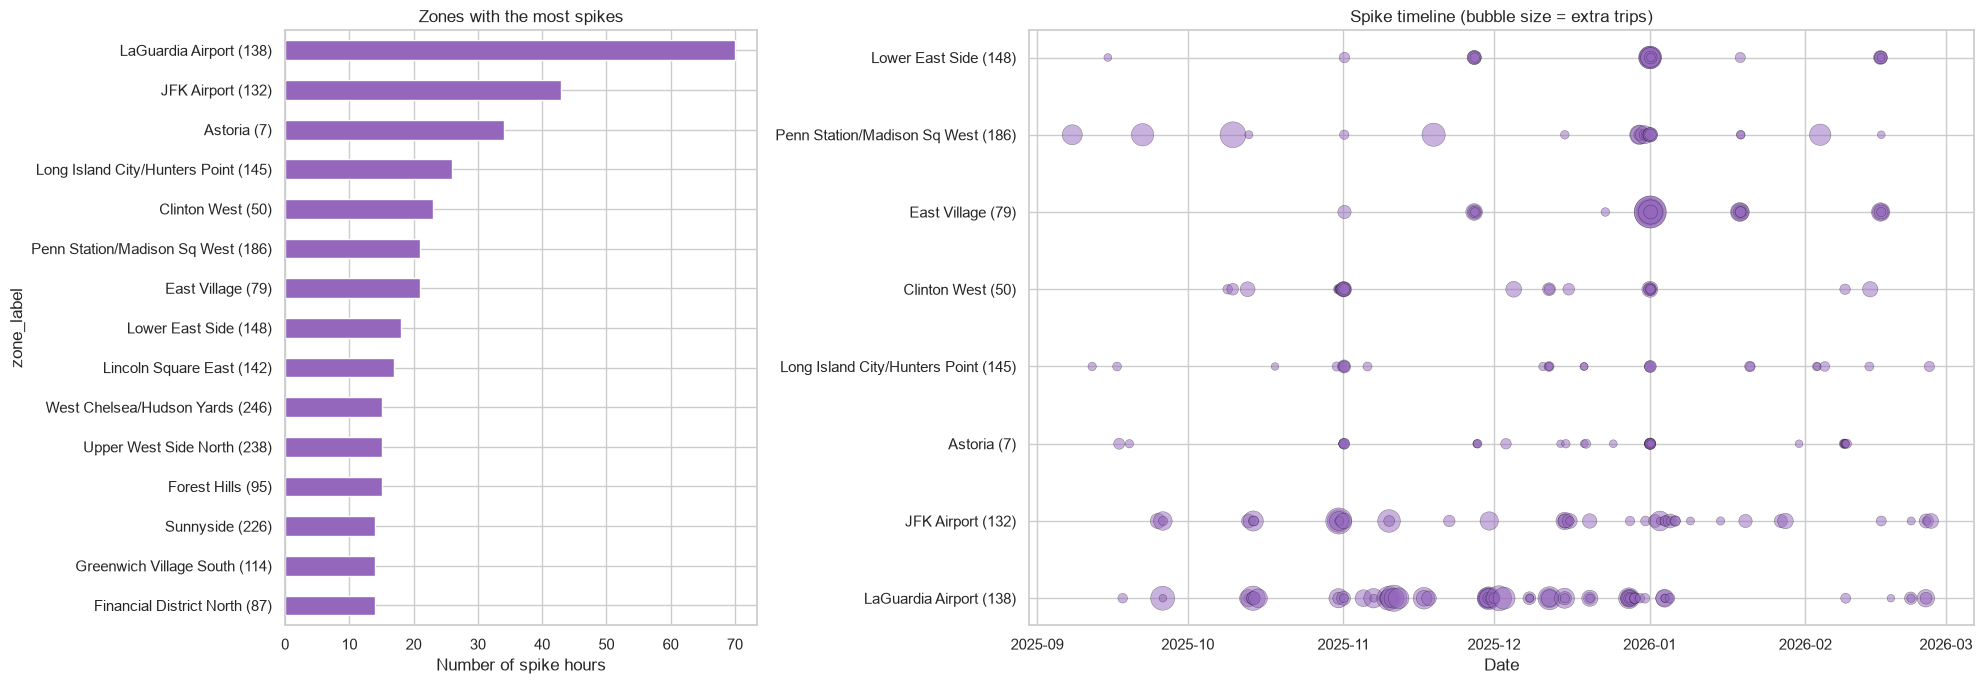

In [42]:
spike_counts = spikes["zone_label"].value_counts().head(15)
top_spike_zones = spike_counts.head(8).index

fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={"width_ratios": [1, 2]})

spike_counts.sort_values().plot(kind="barh", ax=axes[0], color="tab:purple")
axes[0].set_title("Zones with the most spikes")
axes[0].set_xlabel("Number of spike hours")

# Spike timeline for the 8 zones with the most spikes (bubble size = extra trips)
timeline = spikes[spikes["zone_label"].isin(top_spike_zones)]
y_position = {zone: i for i, zone in enumerate(top_spike_zones)}
axes[1].scatter(timeline["pickup_hour"], timeline["zone_label"].map(y_position),
                s=timeline["extra_trips"], alpha=0.5, color="tab:purple", edgecolor="black", linewidth=0.3)
axes[1].set_yticks(range(len(top_spike_zones)))
axes[1].set_yticklabels(top_spike_zones)
axes[1].set_title("Spike timeline (bubble size = extra trips)")
axes[1].set_xlabel("Date")
save_fig("E6_zone_spikes")

In [43]:
# When do spikes happen?
print("Spikes by hour of day (top 6):")
print(spikes["hour"].value_counts().head(6))
print()
print("Share of spikes at the two airports:",
      round(spikes["PULocationID"].isin([132, 138]).mean() * 100, 1), "%")
print()
print("Dates with the most spike hours:")
print(spikes["date"].value_counts().head(6))

Spikes by hour of day (top 6):
hour
1     148
2     137
3     100
0      95
22     67
4      58
Name: count, dtype: int64

Share of spikes at the two airports: 15.3 %

Dates with the most spike hours:
date
2026-01-01    219
2025-11-01     89
2025-11-27     41
2026-02-08     34
2025-12-31     24
2025-10-31     21
Name: count, dtype: int64


**Finding:** 738 spike hours, mostly 00-03. Biggest clusters: New Year's night (219) and Halloween night (89). Airports have 15%; event venues spike repeatedly.

## E7. Daylight saving (DST) hour, 2 Nov 01:00

DST hour trips: 9166
Median of other Sundays at 01:00: 6084
DST hour is 51 % above a normal Sunday 01:00


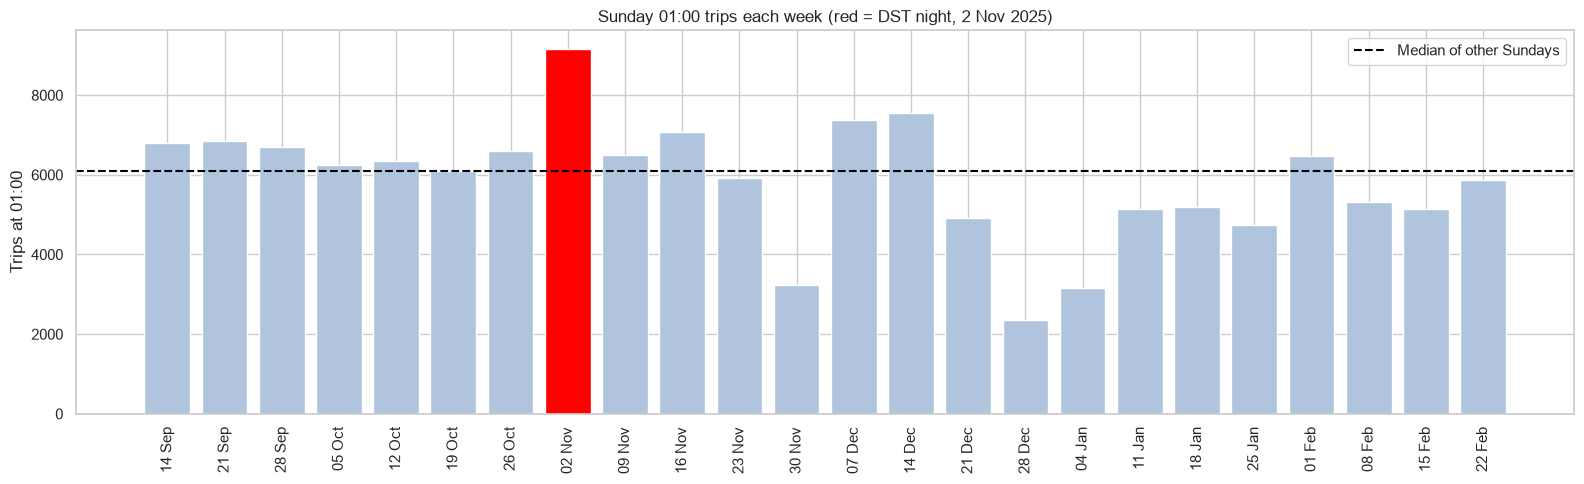

In [44]:
sunday_1am = df[(df["day_of_week"] == 6) & (df["hour"] == 1) & (df["is_holiday"] == False)]
sunday_totals = sunday_1am.groupby("date")["trip_count"].sum()

dst_value = sunday_totals[DST_HOUR.normalize()]
other_sundays = sunday_totals.drop(DST_HOUR.normalize())
print("DST hour trips:", dst_value)
print("Median of other Sundays at 01:00:", round(other_sundays.median()))
print("DST hour is", round((dst_value / other_sundays.median() - 1) * 100), "% above a normal Sunday 01:00")

plt.figure(figsize=(16, 5))
colors = ["red" if d == DST_HOUR.normalize() else "lightsteelblue" for d in sunday_totals.index]
plt.bar([d.strftime("%d %b") for d in sunday_totals.index], sunday_totals.values, color=colors)
plt.axhline(other_sundays.median(), color="black", linestyle="--", label="Median of other Sundays")
plt.xticks(rotation=90)
plt.ylabel("Trips at 01:00")
plt.title("Sunday 01:00 trips each week (red = DST night, 2 Nov 2025)")
plt.legend()
save_fig("E7_dst_hour")

In [45]:
# How much each zone is inflated at the DST hour
zone_dst = df[df["pickup_hour"] == DST_HOUR][["PULocationID", "zone_label", "trip_count"]]
zone_sunday_median = sunday_1am[sunday_1am["date"] != DST_HOUR.normalize()].groupby("PULocationID")["trip_count"].median().rename("normal")
zone_dst = zone_dst.merge(zone_sunday_median, on="PULocationID")
zone_dst = zone_dst[zone_dst["normal"] >= 10]          # only zones with real night demand
zone_dst["ratio"] = zone_dst["trip_count"] / zone_dst["normal"]
print("Zones checked:", len(zone_dst))
print("Median ratio (DST hour / normal):", round(zone_dst["ratio"].median(), 2))
print(zone_dst.sort_values("trip_count", ascending=False).head(5)[["zone_label", "trip_count", "normal", "ratio"]].round(2).to_string(index=False))

Zones checked: 55
Median ratio (DST hour / normal): 1.71
                   zone_label  trip_count  normal  ratio
            East Village (79)        1122   814.0   1.38
        Lower East Side (148)         673   442.0   1.52
           West Village (249)         607   493.0   1.23
Greenwich Village South (114)         576   427.0   1.35
               Gramercy (107)         334   151.0   2.21


In [46]:
# Lag features that copy the DST value into later rows
lag_rows = pd.DataFrame({
    "row": ["2025-11-03 01:00 (lag 24h)", "2025-11-09 01:00 (lag 168h)"],
    "lag_value_citywide": [
        df[df["pickup_hour"] == pd.Timestamp("2025-11-03 01:00")]["trip_count_lag_24h"].sum(),
        df[df["pickup_hour"] == pd.Timestamp("2025-11-09 01:00")]["trip_count_lag_168h"].sum(),
    ],
})
lag_rows["dst_hour_value"] = dst_value
lag_rows["normal_sunday_1am"] = round(other_sundays.median())
lag_rows

,row,lag_value_citywide,dst_hour_value,normal_sunday_1am
0,2025-11-03 01:00 (lag 24h),9166,9166,6084
1,2025-11-09 01:00 (lag 168h),9166,9166,6084


**Finding:** The DST hour is 51% above a normal Sunday 01:00, and the value is copied into lag_24h (3 Nov) and lag_168h (9 Nov). Flag or fix these rows before modelling.

## B6. The 50 busiest zone-hours

In [47]:
top50 = df.sort_values("trip_count", ascending=False).head(50).copy()
top50["weekday"] = top50["pickup_hour"].dt.day_name().str[:3]
print(top50[["pickup_hour", "weekday", "zone_label", "trip_count", "day_type", "apparent_temperature", "rain"]].head(15).to_string(index=False))

        pickup_hour weekday        zone_label  trip_count day_type  apparent_temperature  rain
2025-11-02 01:00:00     Sun East Village (79)        1122  Weekend                   3.6   0.0
2025-09-14 01:00:00     Sun East Village (79)         984  Weekend                  20.7   0.0
2025-12-07 01:00:00     Sun East Village (79)         950  Weekend                  -4.5   0.0
2025-09-21 01:00:00     Sun East Village (79)         910  Weekend                  14.6   0.0
2025-10-12 01:00:00     Sun East Village (79)         909  Weekend                  12.4   0.0
2026-02-01 01:00:00     Sun East Village (79)         905  Weekend                 -17.0   0.0
2025-09-28 00:00:00     Sun East Village (79)         894  Weekend                  22.5   0.7
2025-10-26 01:00:00     Sun East Village (79)         894  Weekend                   7.9   0.0
2025-11-15 00:00:00     Sat East Village (79)         874  Weekend                   2.5   0.0
2025-11-16 01:00:00     Sun East Village (79)     

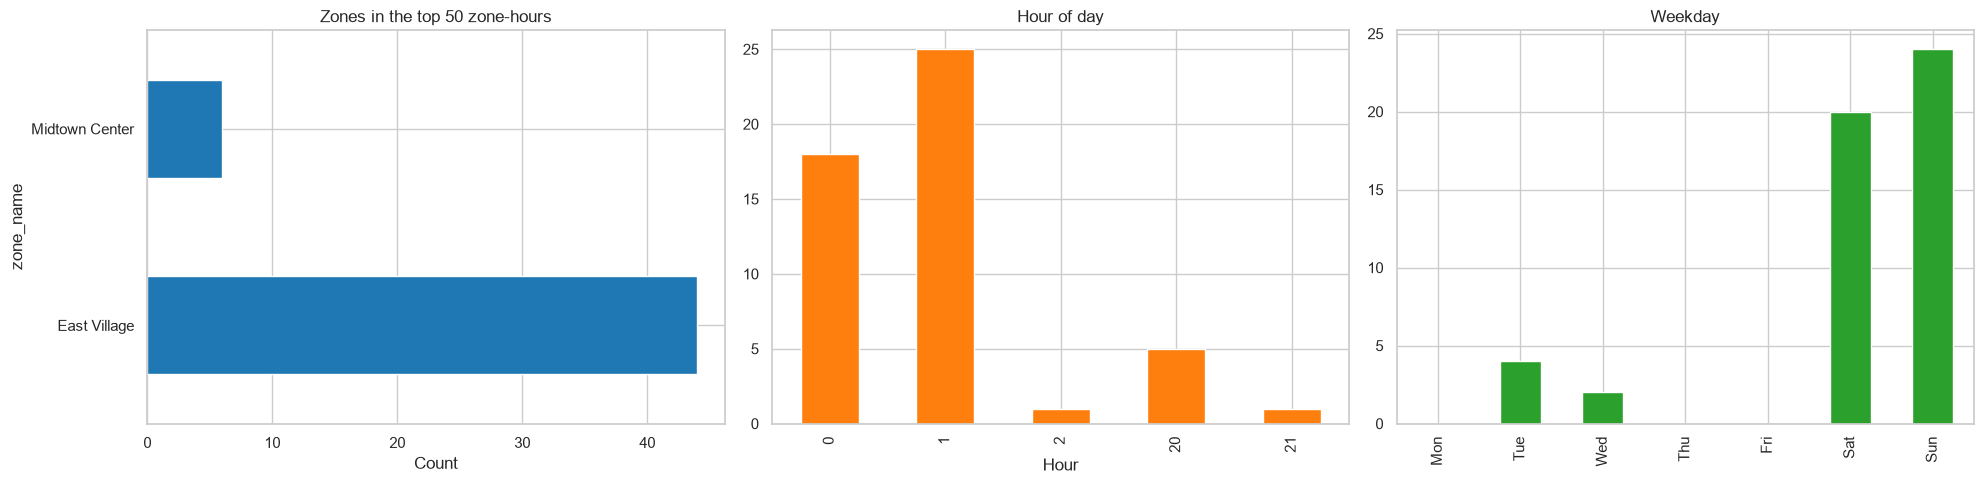

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

top50["zone_name"].value_counts().plot(kind="barh", ax=axes[0], color="tab:blue")
axes[0].set_title("Zones in the top 50 zone-hours")
axes[0].set_xlabel("Count")

top50["hour"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="tab:orange")
axes[1].set_title("Hour of day")
axes[1].set_xlabel("Hour")

top50["weekday"].value_counts().reindex(DAY_NAMES).fillna(0).plot(kind="bar", ax=axes[2], color="tab:green")
axes[2].set_title("Weekday")
axes[2].set_xlabel("")
save_fig("B6_top50_zone_hours")

**Finding:** Real demand, not errors: 44 are East Village weekend nights at 00-01, 6 are Midtown Center weekday evenings.

---
# 3. Weather impact on demand (#61)

**Demand ratio** = actual trips / expected trips, where expected = average of **dry** hours for the same zone, hour, weekday/weekend and month. 1.10 means 10% more trips than a normal dry hour. Holidays, the DST hour and near-empty zones are left out.

In [49]:
near_empty_ids = zone_stats[zone_stats["tier"] == "Near-empty"]["PULocationID"]
wx = df[(df["is_holiday"] == False) & (df["is_dst_hour"] == False)
        & (~df["PULocationID"].isin(near_empty_ids))].copy()

# Weather condition of each zone-hour (snow hours also have some rain, so snow comes last and wins)
wx["condition"] = "Dry"
wx.loc[wx["rain"] > 0, "condition"] = "Rain"
wx.loc[wx["snowfall"] > 0, "condition"] = "Snow"

wx["week_part"] = "Weekday"
wx.loc[wx["is_weekend"] == True, "week_part"] = "Weekend"

# Expected trips = average of dry hours for the same zone, hour, weekday/weekend and month
keys = ["PULocationID", "hour", "week_part", "month"]
expected = wx[wx["condition"] == "Dry"].groupby(keys)["trip_count"].mean().rename("expected").reset_index()
wx = wx.merge(expected, on=keys)
wx = wx[wx["expected"] > 0]


def demand_ratio(data):
    # Total actual trips / total expected trips
    return data["trip_count"].sum() / data["expected"].sum()


def ratio_table(data, column):
    rows = []
    for value, group in data.groupby(column):
        rows.append({column: value, "ratio": demand_ratio(group), "zone_hours": len(group)})
    return pd.DataFrame(rows)


print("Zone-hours used:", len(wx))
print(wx["condition"].value_counts())

Zone-hours used: 391751
condition
Dry     371511
Rain     10726
Snow      9514
Name: count, dtype: int64


## F1. Weather overview

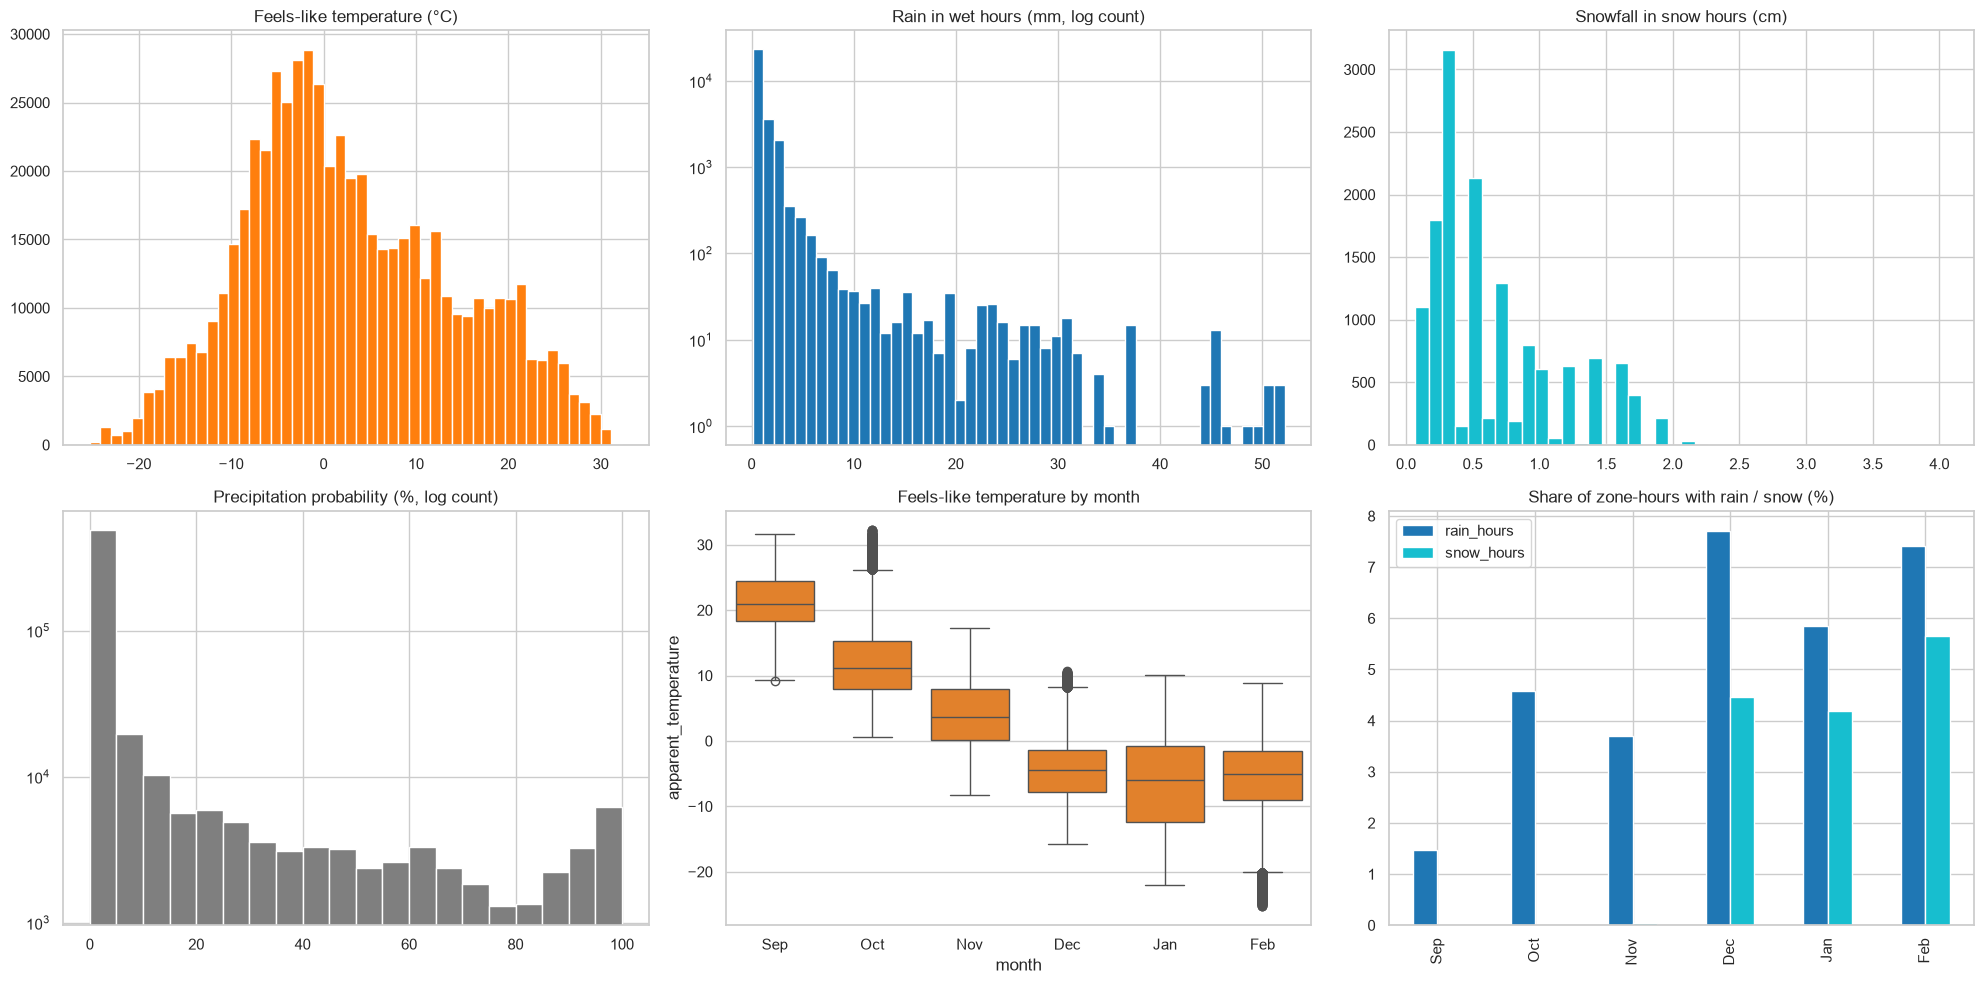

Share of zone-hours with rain: 5.3 %
Share of zone-hours with snow: 2.5 %
Feels-like temperature range: -25.3 to 32.3 °C


In [50]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))

axes[0, 0].hist(df["apparent_temperature"], bins=50, color="tab:orange")
axes[0, 0].set_title("Feels-like temperature (°C)")

axes[0, 1].hist(df[df["rain"] > 0]["rain"], bins=50, color="tab:blue", log=True)
axes[0, 1].set_title("Rain in wet hours (mm, log count)")

axes[0, 2].hist(df[df["snowfall"] > 0]["snowfall"], bins=40, color="tab:cyan")
axes[0, 2].set_title("Snowfall in snow hours (cm)")

axes[1, 0].hist(df["precipitation_probability"], bins=20, color="tab:gray", log=True)
axes[1, 0].set_title("Precipitation probability (%, log count)")

month_order = [9, 10, 11, 12, 1, 2]
month_names = ["Sep", "Oct", "Nov", "Dec", "Jan", "Feb"]
sns.boxplot(data=df, x="month", y="apparent_temperature", order=month_order, color="tab:orange", ax=axes[1, 1])
axes[1, 1].set_xticklabels(month_names)
axes[1, 1].set_title("Feels-like temperature by month")

wet_share = df.groupby("month").agg(rain_hours=("rain", lambda s: (s > 0).mean() * 100),
                                    snow_hours=("snowfall", lambda s: (s > 0).mean() * 100)).reindex(month_order)
wet_share.index = month_names
wet_share.plot(kind="bar", ax=axes[1, 2], color=["tab:blue", "tab:cyan"])
axes[1, 2].set_title("Share of zone-hours with rain / snow (%)")
save_fig("F1_weather_overview")

print("Share of zone-hours with rain:", round((df["rain"] > 0).mean() * 100, 1), "%")
print("Share of zone-hours with snow:", round((df["snowfall"] > 0).mean() * 100, 1), "%")
print("Feels-like temperature range:", df["apparent_temperature"].min(), "to", df["apparent_temperature"].max(), "°C")

**Finding:** Rain in 5.3% and snow in 2.5% of zone-hours. Feels-like temperature ranges from -25 to 32 °C. Snow only falls from December to February.

## F2. Rain and snow events (citywide average weather, wet hour = rain ≥ 0.1 mm or snow ≥ 0.1 cm)

In [51]:
city = df.groupby("pickup_hour")[["rain", "snowfall", "apparent_temperature"]].mean().reset_index()
city["is_wet"] = (city["rain"] >= 0.1) | (city["snowfall"] >= 0.1)

# Number each run of consecutive wet hours as one event
city["event_id"] = (city["is_wet"] != city["is_wet"].shift()).cumsum()
events = city[city["is_wet"]].groupby("event_id").agg(
    start=("pickup_hour", "min"),
    hours=("pickup_hour", "count"),
    total_rain_mm=("rain", "sum"),
    total_snow_cm=("snowfall", "sum"),
).reset_index(drop=True)
events["type"] = "Rain"
events.loc[events["total_snow_cm"] >= 1, "type"] = "Snow"

print("Wet events:", len(events), "| rain:", (events["type"] == "Rain").sum(), "| snow:", (events["type"] == "Snow").sum())
events.sort_values("total_rain_mm", ascending=False).head(8).round(1)

Wet events: 68 | rain: 59 | snow: 9


,start,hours,total_rain_mm,total_snow_cm,type
43,2025-12-19 04:00:00,10,32.0,0.0,Rain
19,2025-10-30 13:00:00,4,26.0,0.0,Rain
11,2025-10-12 12:00:00,17,22.4,0.0,Rain
3,2025-09-25 02:00:00,4,21.0,0.0,Rain
38,2025-12-02 10:00:00,8,18.0,0.0,Rain
52,2026-01-10 13:00:00,12,16.2,0.0,Rain
66,2026-02-22 11:00:00,28,14.2,22.9,Snow
59,2026-01-25 06:00:00,18,13.0,19.1,Snow


In [52]:
print("Biggest snow events:")
events.sort_values("total_snow_cm", ascending=False).head(5).round(1)

Biggest snow events:


,start,hours,total_rain_mm,total_snow_cm,type
66,2026-02-22 11:00:00,28,14.2,22.9,Snow
59,2026-01-25 06:00:00,18,13.0,19.1,Snow
46,2025-12-26 17:00:00,13,5.9,9.7,Snow
41,2025-12-14 00:00:00,12,3.7,5.9,Snow
60,2026-02-15 22:00:00,7,1.3,2.4,Snow


**Finding:** 68 wet events (59 rain, 9 snow). The biggest snowstorms were 22-23 Feb (23 cm) and 25 Jan (19 cm); the heaviest rain was 19 Dec (32 mm).

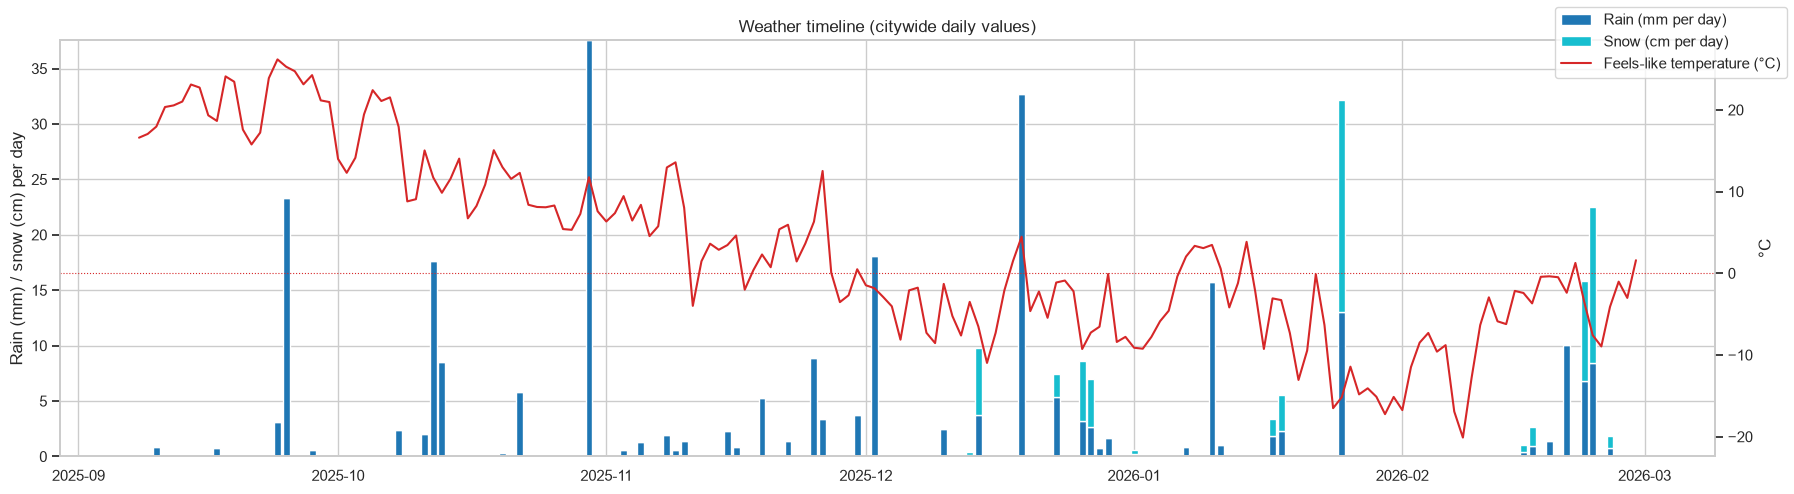

In [53]:
city_daily = city.groupby(city["pickup_hour"].dt.normalize()).agg(
    rain_mm=("rain", "sum"), snow_cm=("snowfall", "sum"), temp=("apparent_temperature", "mean"))

fig, ax1 = plt.subplots(figsize=(18, 5))
ax1.bar(city_daily.index, city_daily["rain_mm"], color="tab:blue", label="Rain (mm per day)")
ax1.bar(city_daily.index, city_daily["snow_cm"], bottom=city_daily["rain_mm"], color="tab:cyan", label="Snow (cm per day)")
ax1.set_ylabel("Rain (mm) / snow (cm) per day")
ax2 = ax1.twinx()
ax2.plot(city_daily.index, city_daily["temp"], color="tab:red", label="Feels-like temperature (°C)")
ax2.axhline(0, color="tab:red", linestyle=":", linewidth=0.8)
ax2.set_ylabel("°C")
ax2.grid(False)
fig.legend(loc="upper right")
plt.title("Weather timeline (citywide daily values)")
save_fig("F2_weather_timeline")

## F3. Weather correlation and forecast reliability

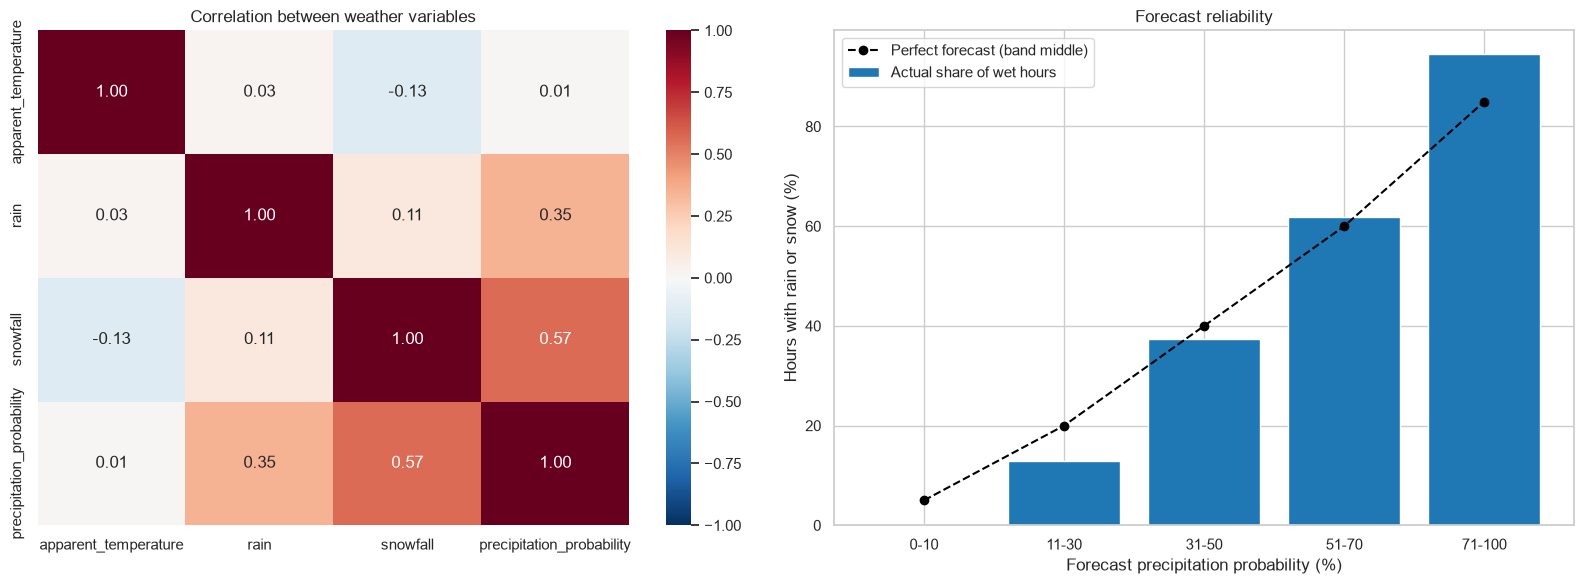

prob_band
0-10       0.2
11-30     12.9
31-50     37.3
51-70     61.8
71-100    94.5
Name: wet_now, dtype: float64


In [54]:
weather_cols = ["apparent_temperature", "rain", "snowfall", "precipitation_probability"]

# Reliability: when the forecast says X%, how often does rain or snow actually happen?
df["prob_band"] = pd.cut(df["precipitation_probability"], bins=[-1, 10, 30, 50, 70, 100],
                         labels=["0-10", "11-30", "31-50", "51-70", "71-100"])
df["wet_now"] = (df["rain"] > 0) | (df["snowfall"] > 0)
reliability = df.groupby("prob_band")["wet_now"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(df[weather_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation between weather variables")

axes[1].bar(reliability.index.astype(str), reliability.values, color="tab:blue", label="Actual share of wet hours")
axes[1].plot(["0-10", "11-30", "31-50", "51-70", "71-100"], [5, 20, 40, 60, 85], color="black",
             linestyle="--", marker="o", label="Perfect forecast (band middle)")
axes[1].set_xlabel("Forecast precipitation probability (%)")
axes[1].set_ylabel("Hours with rain or snow (%)")
axes[1].set_title("Forecast reliability")
axes[1].legend()
save_fig("F3_weather_correlation_reliability")

print(reliability.round(1))

**Finding:** The forecast is well calibrated: at 71-100% it rains or snows in 95% of hours, at 0-10% in 0.2%. Snowfall and forecast probability are linked (r = 0.57).

## F4. Weather spread across zones in the same hour

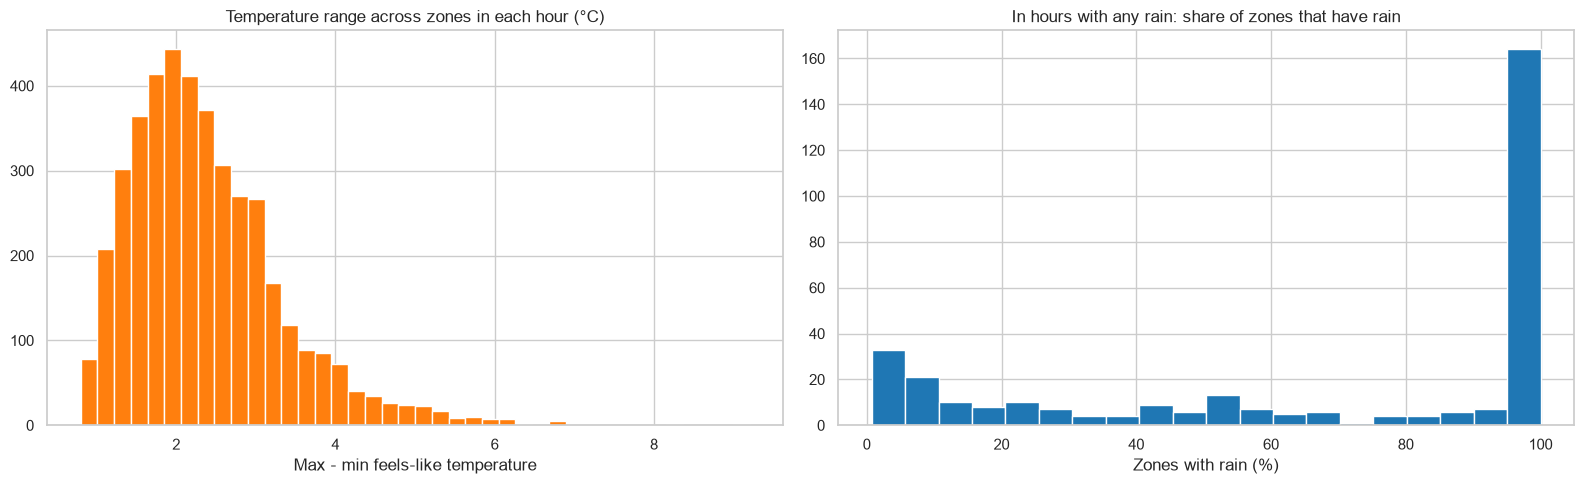

Median temperature range across zones: 2.2 °C
Rainy hours where some zones stay dry: 57.4 %


In [55]:
spread = df.groupby("pickup_hour").agg(
    temp_range=("apparent_temperature", lambda s: s.max() - s.min()),
    zones_with_rain=("rain", lambda s: (s > 0).mean() * 100),
)
rainy_hours = spread[spread["zones_with_rain"] > 0]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(spread["temp_range"], bins=40, color="tab:orange")
axes[0].set_title("Temperature range across zones in each hour (°C)")
axes[0].set_xlabel("Max - min feels-like temperature")

axes[1].hist(rainy_hours["zones_with_rain"], bins=20, color="tab:blue")
axes[1].set_title("In hours with any rain: share of zones that have rain")
axes[1].set_xlabel("Zones with rain (%)")
save_fig("F4_weather_spread")

print("Median temperature range across zones:", round(spread["temp_range"].median(), 1), "°C")
print("Rainy hours where some zones stay dry:", round((rainy_hours["zones_with_rain"] < 100).mean() * 100, 1), "%")

**Finding:** In 57% of rainy hours some zones stay dry, and temperatures differ by about 2 °C across zones, so per-zone weather adds information.

## F5. Rain effect by intensity

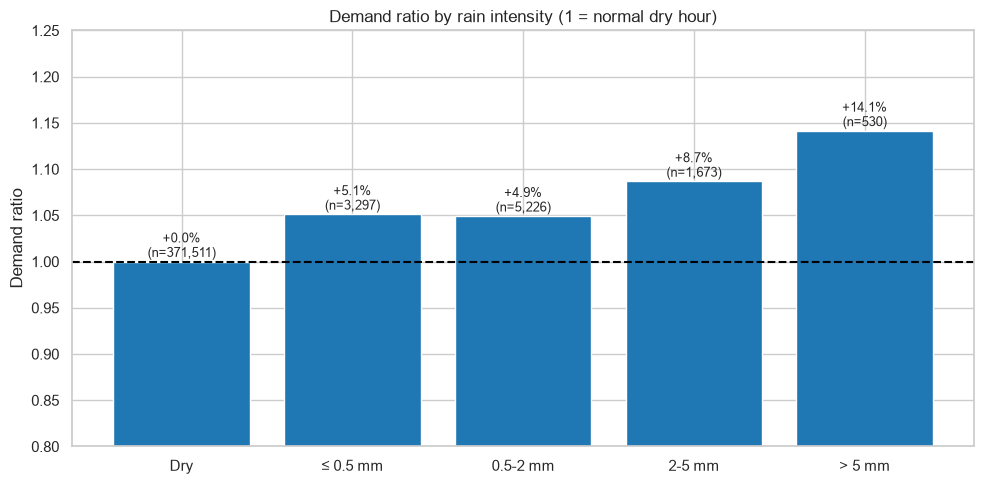

,rain_band,ratio,zone_hours,change_%
0,Dry,1.000000,371511,0.0
1,≤ 0.5 mm,1.051163,3297,5.1
2,0.5-2 mm,1.049144,5226,4.9
3,2-5 mm,1.086749,1673,8.7
4,> 5 mm,1.141483,530,14.1


In [56]:
from scipy.stats import mannwhitneyu

no_snow = wx[wx["condition"] != "Snow"].copy()
no_snow["rain_band"] = pd.cut(no_snow["rain"], bins=[-1, 0, 0.5, 2, 5, 100],
                              labels=["Dry", "≤ 0.5 mm", "0.5-2 mm", "2-5 mm", "> 5 mm"])
rain_effect = ratio_table(no_snow, "rain_band")
rain_effect["change_%"] = ((rain_effect["ratio"] - 1) * 100).round(1)

plt.figure(figsize=(10, 5))
bars = plt.bar(rain_effect["rain_band"].astype(str), rain_effect["ratio"], color="tab:blue")
plt.axhline(1, color="black", linestyle="--")
for bar, change, n in zip(bars, rain_effect["change_%"], rain_effect["zone_hours"]):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
             f"{change:+.1f}%\n(n={n:,})", ha="center", fontsize=9)
plt.ylim(0.8, 1.25)
plt.ylabel("Demand ratio")
plt.title("Demand ratio by rain intensity (1 = normal dry hour)")
save_fig("F5_rain_effect")
rain_effect

In [57]:
# Test: are hourly citywide ratios higher in rain hours than in dry hours?
hour_ratio = no_snow.groupby(["pickup_hour", "condition"]).apply(demand_ratio).rename("ratio").reset_index()
dry_r = hour_ratio[hour_ratio["condition"] == "Dry"]["ratio"]
rain_r = hour_ratio[hour_ratio["condition"] == "Rain"]["ratio"]
stat, p_value = mannwhitneyu(rain_r, dry_r)
effect_size = 2 * stat / (len(rain_r) * len(dry_r)) - 1   # rank-biserial: 0 = no difference
print("Median hourly ratio - rain:", round(rain_r.median(), 3), "| dry:", round(dry_r.median(), 3))
print("Mann-Whitney p-value:", p_value, "| effect size (rank-biserial):", round(effect_size, 3))

Median hourly ratio - rain: 1.059 | dry: 1.003
Mann-Whitney p-value: 0.0008725823100705322 | effect size (rank-biserial): 0.141


**Finding:** Rain raises demand by about 5% (light) to 14% (> 5 mm per hour). The difference from dry hours is significant (p < 0.001) but the effect size is small (0.14).

## F6. Snow effect by intensity, and recovery after snowstorms

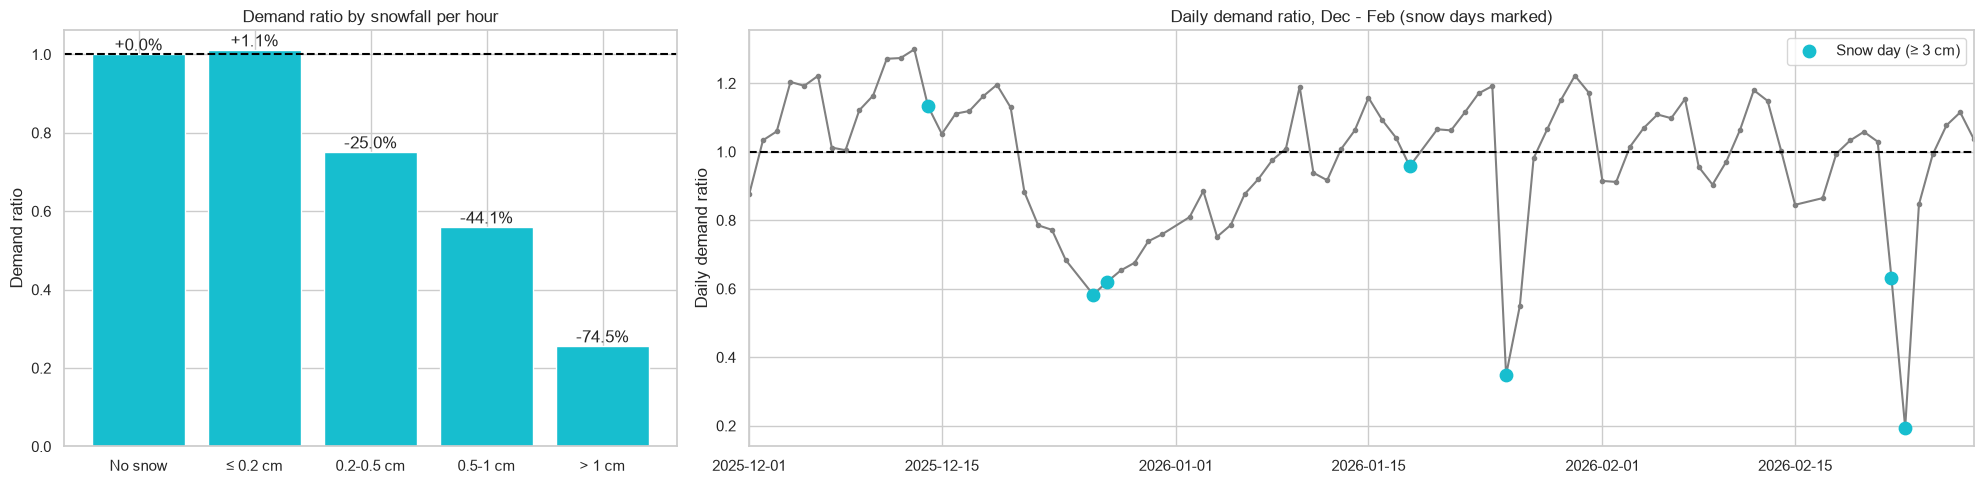

,snow_band,ratio,zone_hours,change_%
0,No snow,1.000000,371511,0.0
1,≤ 0.2 cm,1.010539,701,1.1
2,0.2-0.5 cm,0.750338,3651,-25.0
3,0.5-1 cm,0.558947,2821,-44.1
4,> 1 cm,0.255485,2341,-74.5


In [58]:
snow_data = wx[wx["condition"] != "Rain"].copy()
snow_data["snow_band"] = pd.cut(snow_data["snowfall"], bins=[-1, 0, 0.2, 0.5, 1, 100],
                                labels=["No snow", "≤ 0.2 cm", "0.2-0.5 cm", "0.5-1 cm", "> 1 cm"])
snow_effect = ratio_table(snow_data, "snow_band")
snow_effect["change_%"] = ((snow_effect["ratio"] - 1) * 100).round(1)

# Daily demand ratio, to see how fast demand comes back after a storm
daily_ratio = wx.groupby("date").apply(demand_ratio)

fig, axes = plt.subplots(1, 2, figsize=(20, 5), gridspec_kw={"width_ratios": [1, 2]})
bars = axes[0].bar(snow_effect["snow_band"].astype(str), snow_effect["ratio"], color="tab:cyan")
axes[0].axhline(1, color="black", linestyle="--")
for bar, change in zip(bars, snow_effect["change_%"]):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"{change:+.1f}%", ha="center")
axes[0].set_ylabel("Demand ratio")
axes[0].set_title("Demand ratio by snowfall per hour")

axes[1].plot(daily_ratio.index, daily_ratio.values, color="gray", marker=".")
axes[1].axhline(1, color="black", linestyle="--")
snow_days = city_daily[city_daily["snow_cm"] >= 3].index
axes[1].scatter(snow_days, daily_ratio.reindex(snow_days), color="tab:cyan", s=80, zorder=5, label="Snow day (≥ 3 cm)")
axes[1].set_xlim(pd.Timestamp("2025-12-01"), pd.Timestamp("2026-02-28"))
axes[1].set_ylabel("Daily demand ratio")
axes[1].set_title("Daily demand ratio, Dec - Feb (snow days marked)")
axes[1].legend()
save_fig("F6_snow_effect")
snow_effect

In [59]:
# Demand ratio on each snow day and the 2 days after it
for day in snow_days:
    values = [daily_ratio.get(day + pd.Timedelta(days=k)) for k in range(3)]
    text = ", ".join("n/a" if v is None else str(round(v, 2)) for v in values)
    print(day.strftime("%d %b"), "->", text, "(day of snow, +1 day, +2 days)")

14 Dec -> 1.13, 1.05, 1.11 (day of snow, +1 day, +2 days)
26 Dec -> 0.58, 0.62, 0.65 (day of snow, +1 day, +2 days)
27 Dec -> 0.62, 0.65, 0.68 (day of snow, +1 day, +2 days)
18 Jan -> 0.96, n/a, 1.07 (day of snow, +1 day, +2 days)
25 Jan -> 0.35, 0.55, 0.98 (day of snow, +1 day, +2 days)
22 Feb -> 0.63, 0.19, 0.85 (day of snow, +1 day, +2 days)
23 Feb -> 0.19, 0.85, 0.99 (day of snow, +1 day, +2 days)


**Finding:** Light snow (≤ 0.2 cm per hour) has no effect, but heavier snow cuts pickups by 25-75%. After the big storms, demand is back to normal 1-2 days later. Pickups also reflect fewer taxis on the road, so part of this drop is lost supply.

## F7. Temperature effect (dry hours only)

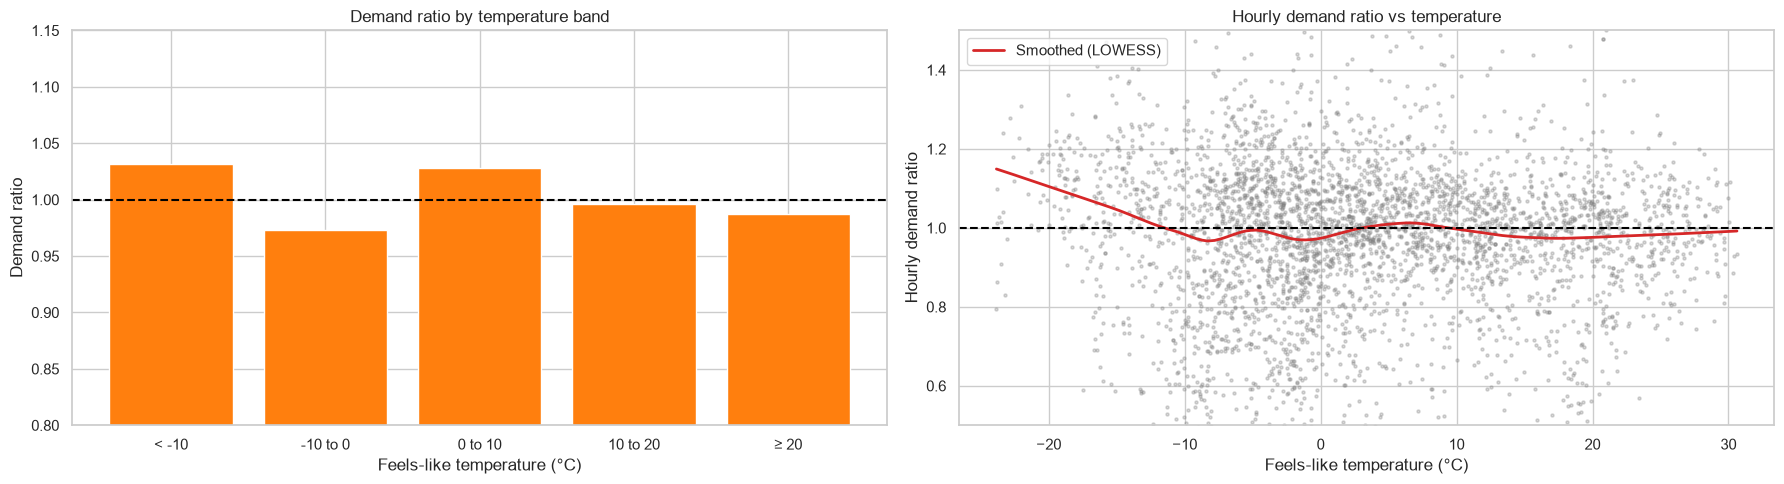

,temp_band,ratio,zone_hours
0,< -10,1.032,42203
1,-10 to 0,0.974,126556
2,0 to 10,1.028,99772
3,10 to 20,0.996,64801
4,≥ 20,0.988,38179


In [60]:
from statsmodels.nonparametric.smoothers_lowess import lowess

dry = wx[wx["condition"] == "Dry"].copy()
dry["temp_band"] = pd.cut(dry["apparent_temperature"], bins=[-40, -10, 0, 10, 20, 40],
                          labels=["< -10", "-10 to 0", "0 to 10", "10 to 20", "≥ 20"])
temp_effect = ratio_table(dry, "temp_band")

# Citywide ratio for each dry clock hour vs its average temperature
dry_hourly = dry.groupby("pickup_hour").agg(trips=("trip_count", "sum"), expected=("expected", "sum"),
                                            temp=("apparent_temperature", "mean"))
dry_hourly["ratio"] = dry_hourly["trips"] / dry_hourly["expected"]
smooth = lowess(dry_hourly["ratio"], dry_hourly["temp"], frac=0.3)

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
axes[0].bar(temp_effect["temp_band"].astype(str), temp_effect["ratio"], color="tab:orange")
axes[0].axhline(1, color="black", linestyle="--")
axes[0].set_ylim(0.8, 1.15)
axes[0].set_xlabel("Feels-like temperature (°C)")
axes[0].set_ylabel("Demand ratio")
axes[0].set_title("Demand ratio by temperature band")

axes[1].scatter(dry_hourly["temp"], dry_hourly["ratio"], s=5, alpha=0.3, color="gray")
axes[1].plot(smooth[:, 0], smooth[:, 1], color="tab:red", linewidth=2, label="Smoothed (LOWESS)")
axes[1].axhline(1, color="black", linestyle="--")
axes[1].set_ylim(0.5, 1.5)
axes[1].set_xlabel("Feels-like temperature (°C)")
axes[1].set_ylabel("Hourly demand ratio")
axes[1].set_title("Hourly demand ratio vs temperature")
axes[1].legend()
save_fig("F7_temperature_effect")
temp_effect.round(3)

**Finding:** Temperature has almost no effect once hour, weekday and month are taken into account (all bands within ±3%).

## F8. Does the forecast change demand? (precipitation probability, dry vs wet hours)

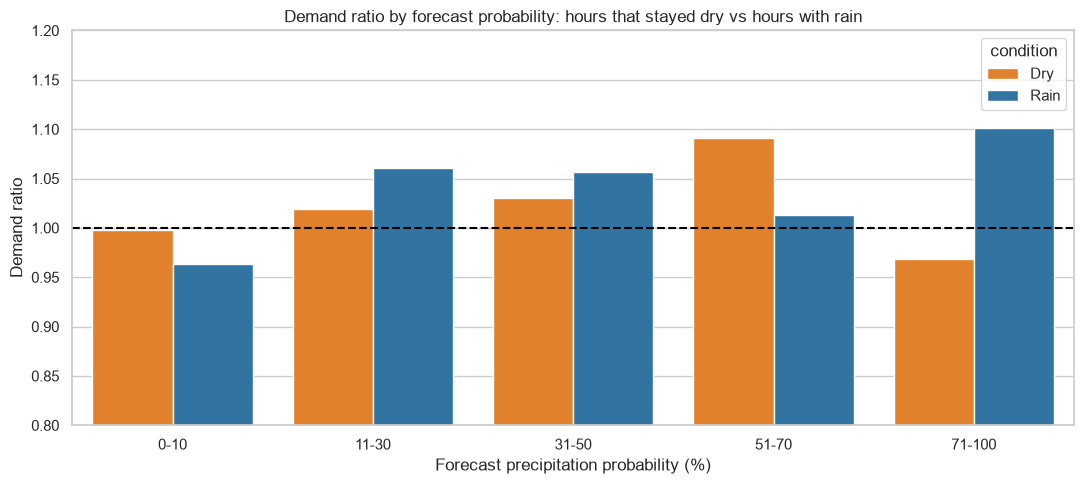

,prob_band,condition,ratio,zone_hours
0,0-10,Dry,0.998,349028
1,0-10,Rain,0.964,626
2,11-30,Dry,1.019,14362
3,11-30,Rain,1.061,1530
4,31-50,Dry,1.030,5400
5,31-50,Rain,1.056,1541
6,51-70,Dry,1.091,2381
7,51-70,Rain,1.013,2779
8,71-100,Dry,0.968,340
9,71-100,Rain,1.101,4250


In [61]:
wx["prob_band"] = pd.cut(wx["precipitation_probability"], bins=[-1, 10, 30, 50, 70, 100],
                         labels=["0-10", "11-30", "31-50", "51-70", "71-100"])
forecast_rows = []
for band, group in wx[wx["condition"] != "Snow"].groupby("prob_band"):
    for cond in ["Dry", "Rain"]:
        part = group[group["condition"] == cond]
        if len(part) > 0:
            forecast_rows.append({"prob_band": band, "condition": cond,
                                  "ratio": demand_ratio(part), "zone_hours": len(part)})
forecast_effect = pd.DataFrame(forecast_rows)

plt.figure(figsize=(11, 5))
sns.barplot(data=forecast_effect, x="prob_band", y="ratio", hue="condition",
            palette={"Dry": "tab:orange", "Rain": "tab:blue"})
plt.axhline(1, color="black", linestyle="--")
plt.ylim(0.8, 1.2)
plt.xlabel("Forecast precipitation probability (%)")
plt.ylabel("Demand ratio")
plt.title("Demand ratio by forecast probability: hours that stayed dry vs hours with rain")
save_fig("F8_forecast_effect")
forecast_effect.round(3)

**Finding:** The forecast alone has only a weak, mixed effect. Dry hours with a 51-70% forecast are 9% busier, but other bands show no clear pattern.

## F9. Weather effect by time of day and day type

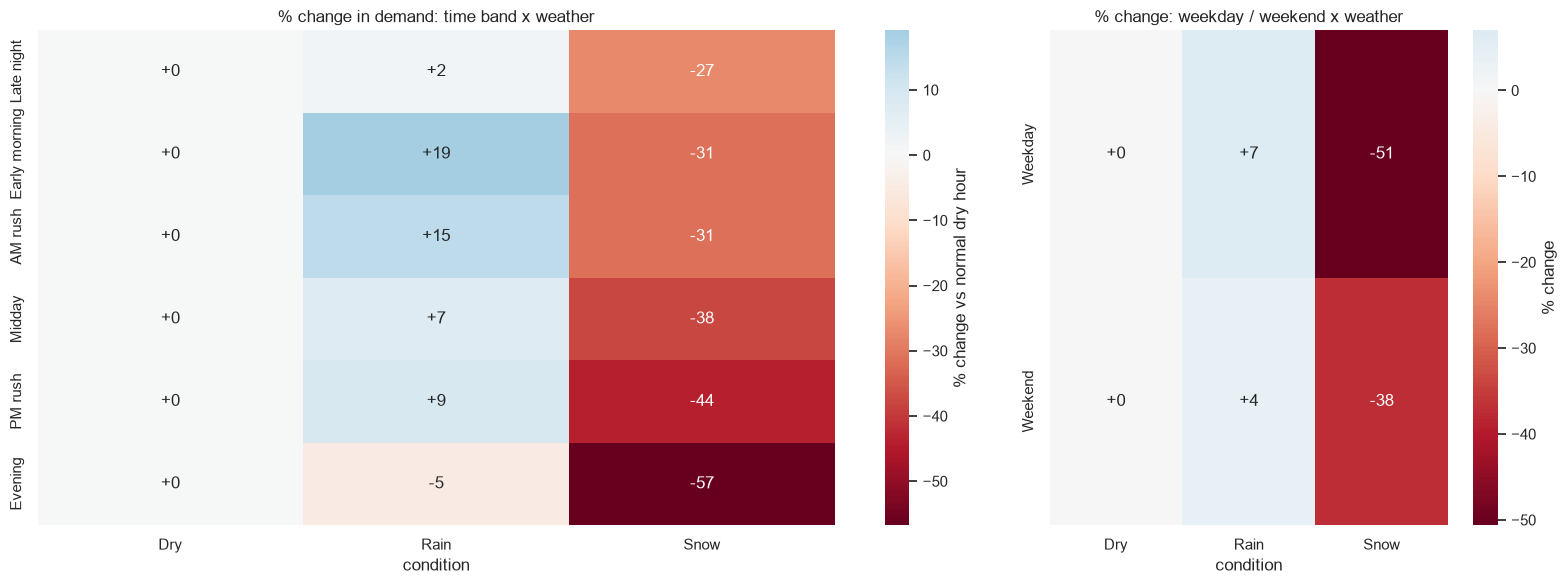

condition,Dry,Rain,Snow
time_band,,,
Late night,1.0,1.017,0.728
Early morning,1.0,1.191,0.688
AM rush,1.0,1.146,0.688
Midday,1.0,1.071,0.621
PM rush,1.0,1.094,0.559
Evening,1.0,0.953,0.432


In [62]:
band_cond = wx.groupby(["time_band", "condition"]).apply(demand_ratio).unstack("condition").reindex(TIME_BANDS)
week_cond = wx.groupby(["week_part", "condition"]).apply(demand_ratio).unstack("condition")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [2, 1]})
sns.heatmap((band_cond - 1) * 100, annot=True, fmt="+.0f", cmap="RdBu", center=0, ax=axes[0],
            cbar_kws={"label": "% change vs normal dry hour"})
axes[0].set_title("% change in demand: time band x weather")
axes[0].set_ylabel("")
sns.heatmap((week_cond - 1) * 100, annot=True, fmt="+.0f", cmap="RdBu", center=0, ax=axes[1],
            cbar_kws={"label": "% change"})
axes[1].set_title("% change: weekday / weekend x weather")
axes[1].set_ylabel("")
save_fig("F9_weather_by_time")
band_cond.round(3)

**Finding:** Rain matters most in the morning (early morning +19%, AM rush +15%) and slightly lowers evening demand (-5%). Snow hits evenings hardest (-57%).

## F10. Weather effect by place (borough, service zone, cluster, zone)

In [63]:
place_rows = []
for column in ["borough", "service_zone"]:
    for value, group in wx.groupby(column):
        place_rows.append({"group": column, "value": value,
                           "rain_%": (demand_ratio(group[group["condition"] == "Rain"]) - 1) * 100,
                           "snow_%": (demand_ratio(group[group["condition"] == "Snow"]) - 1) * 100})

wx_clusters = wx.merge(cluster_table[["PULocationID", "cluster_name"]], on="PULocationID")
for value, group in wx_clusters.groupby("cluster_name"):
    place_rows.append({"group": "cluster", "value": value,
                       "rain_%": (demand_ratio(group[group["condition"] == "Rain"]) - 1) * 100,
                       "snow_%": (demand_ratio(group[group["condition"] == "Snow"]) - 1) * 100})
place_effect = pd.DataFrame(place_rows).round(1)
place_effect

,group,value,rain_%,snow_%
0,borough,Manhattan,6.0,-41.5
1,borough,Queens,5.0,-41.1
2,service_zone,Airports,1.0,-59.6
3,service_zone,Boro Zone,10.2,-20.9
4,service_zone,Yellow Zone,6.0,-42.1
5,cluster,Core business and airports (daytime),6.4,-42.5
6,cluster,Nightlife (late night and weekends),1.3,-42.2
7,cluster,Residential (morning commute),7.7,-23.7


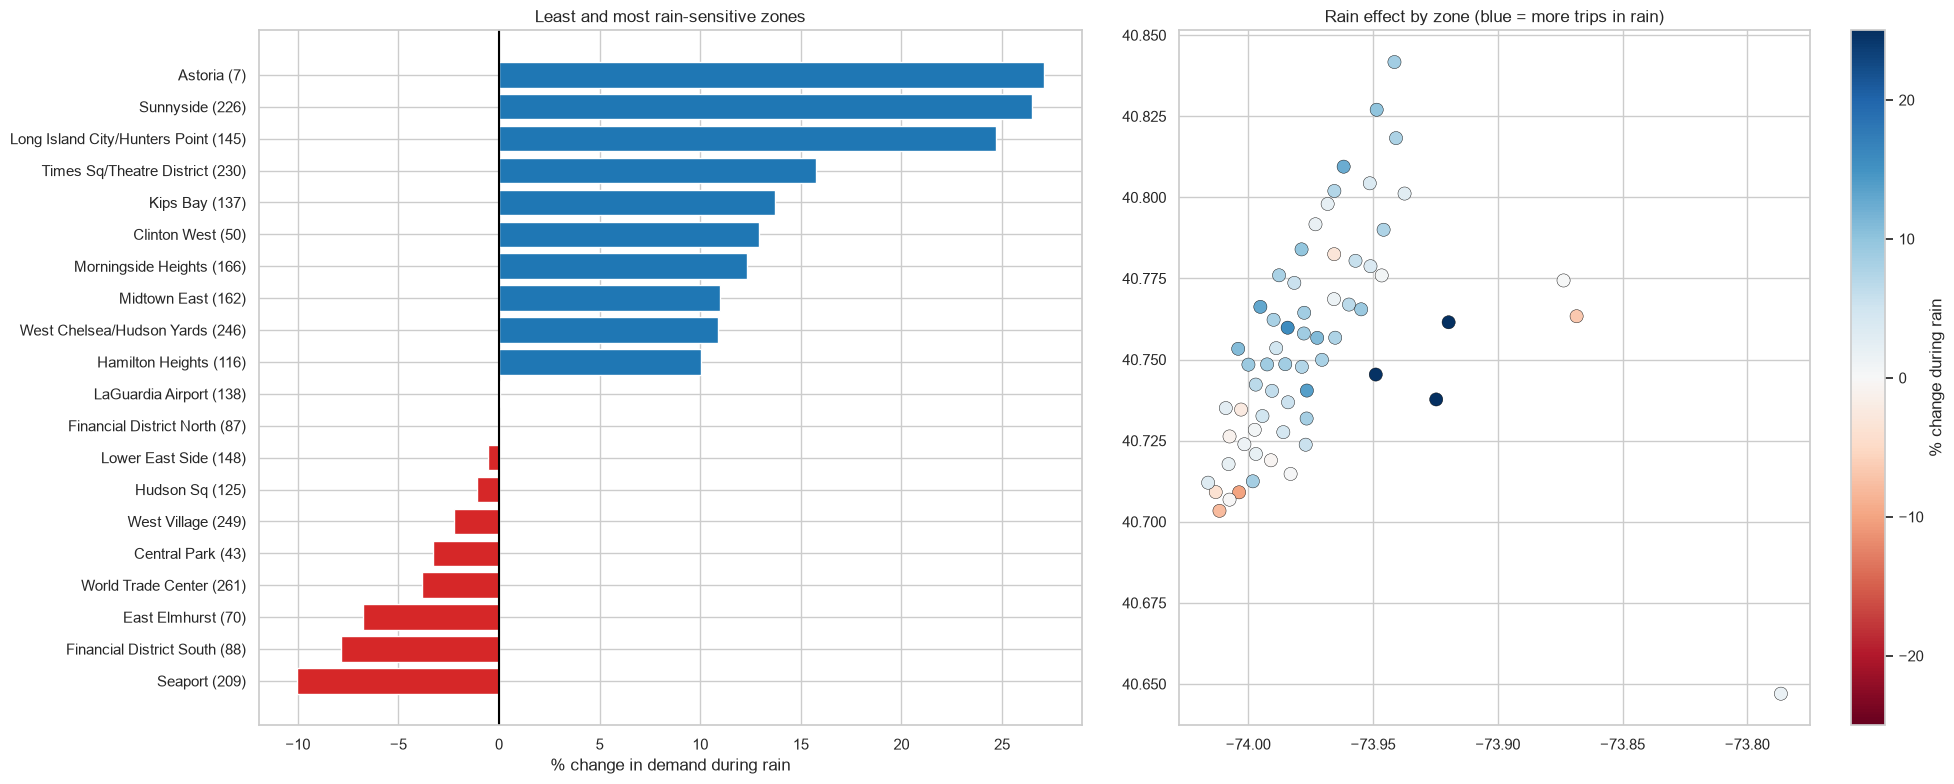

Zones checked: 63


In [64]:
# Rain effect per zone (zones with at least 10 expected trips per hour)
zone_rows = []
for zone_id, group in wx[wx["condition"] != "Snow"].groupby("PULocationID"):
    if group["expected"].mean() >= 10:
        zone_rows.append({"PULocationID": zone_id,
                          "rain_change_%": (demand_ratio(group[group["condition"] == "Rain"]) - 1) * 100})
zone_rain = pd.DataFrame(zone_rows).merge(zones, on="PULocationID").sort_values("rain_change_%")
ranked = pd.concat([zone_rain.head(10), zone_rain.tail(10)])

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
colors = ["tab:red" if v < 0 else "tab:blue" for v in ranked["rain_change_%"]]
axes[0].barh(ranked["zone_label"], ranked["rain_change_%"], color=colors)
axes[0].axvline(0, color="black")
axes[0].set_xlabel("% change in demand during rain")
axes[0].set_title("Least and most rain-sensitive zones")

points = axes[1].scatter(zone_rain["longitude"], zone_rain["latitude"], c=zone_rain["rain_change_%"],
                         cmap="RdBu", vmin=-25, vmax=25, s=90, edgecolor="black", linewidth=0.3)
plt.colorbar(points, ax=axes[1], label="% change during rain")
axes[1].set_aspect(1.3)
axes[1].set_title("Rain effect by zone (blue = more trips in rain)")
save_fig("F10_rain_sensitivity_by_zone")
print("Zones checked:", len(zone_rain))

**Finding:** In rain, residential Queens zones (Astoria, Sunnyside, Long Island City, about +25%) and Times Square rise most; the airports barely change (+1%), and Seaport and the Financial District fall. In snow, the airports drop most (-60%).

## F11. Demand before, during and after rain (zone-level rain timing)

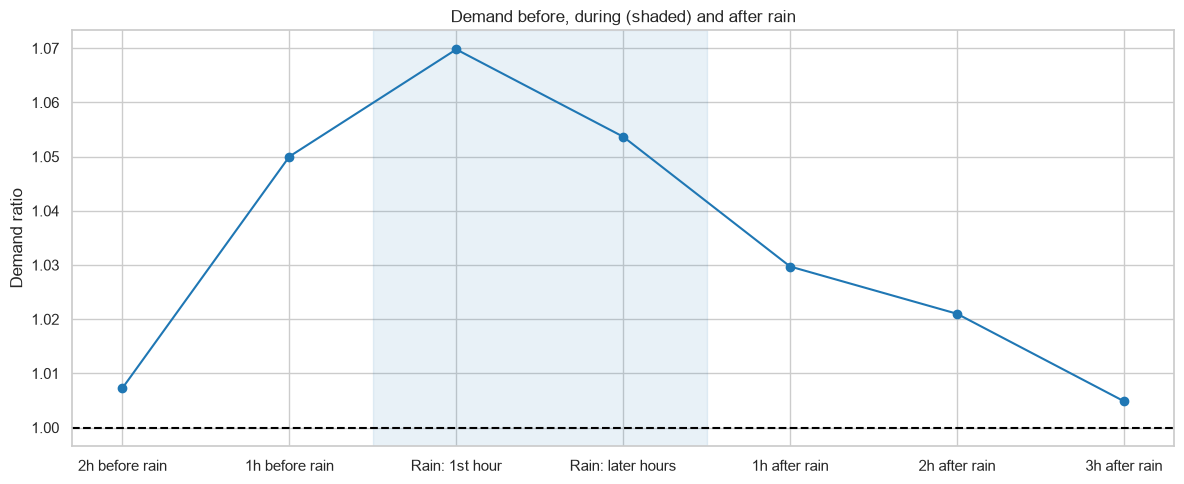

,phase,ratio,zone_hours
0,2h before rain,1.007,3788
1,1h before rain,1.050,4187
2,Rain: 1st hour,1.070,4272
3,Rain: later hours,1.054,6454
4,1h after rain,1.030,4073
5,2h after rain,1.021,3787
6,3h after rain,1.005,3510


In [65]:
# Rain flag for every zone-hour (snow hours excluded), then look 1-3 hours back and ahead in the same zone
timing = df[["PULocationID", "pickup_hour", "rain", "snowfall"]].sort_values(["PULocationID", "pickup_hour"]).copy()
timing["wet"] = (timing["rain"] > 0) & (timing["snowfall"] == 0)
for k in [1, 2, 3]:
    timing["wet_" + str(k) + "h_ago"] = timing.groupby("PULocationID")["wet"].shift(k)
    timing["wet_in_" + str(k) + "h"] = timing.groupby("PULocationID")["wet"].shift(-k)

t = wx.merge(timing.drop(columns=["rain", "snowfall", "wet"]), on=["PULocationID", "pickup_hour"])
dry_t = t[t["condition"] == "Dry"]
rain_t = t[t["condition"] == "Rain"]

phases = {
    "2h before rain": dry_t[(dry_t["wet_in_2h"] == True) & (dry_t["wet_in_1h"] == False)],
    "1h before rain": dry_t[dry_t["wet_in_1h"] == True],
    "Rain: 1st hour": rain_t[rain_t["wet_1h_ago"] == False],
    "Rain: later hours": rain_t[rain_t["wet_1h_ago"] == True],
    "1h after rain": dry_t[dry_t["wet_1h_ago"] == True],
    "2h after rain": dry_t[(dry_t["wet_2h_ago"] == True) & (dry_t["wet_1h_ago"] == False)],
    "3h after rain": dry_t[(dry_t["wet_3h_ago"] == True) & (dry_t["wet_2h_ago"] == False) & (dry_t["wet_1h_ago"] == False)],
}
phase_effect = pd.DataFrame({"phase": list(phases.keys()),
                             "ratio": [demand_ratio(p) for p in phases.values()],
                             "zone_hours": [len(p) for p in phases.values()]})

plt.figure(figsize=(12, 5))
plt.plot(phase_effect["phase"], phase_effect["ratio"], marker="o", color="tab:blue")
plt.axhline(1, color="black", linestyle="--")
plt.axvspan(1.5, 3.5, color="tab:blue", alpha=0.1)
plt.ylabel("Demand ratio")
plt.title("Demand before, during (shaded) and after rain")
save_fig("F11_rain_timing")
phase_effect.round(3)

**Finding:** Demand rises 1 hour before rain (+5%), peaks in the first rain hour (+7%) and returns to normal about 3 hours after the rain stops.

## F12. Extreme weather days vs a normal day (same weekday, ±4 weeks, no holidays or snow days)

Heaviest rain 30 Oct - Manhattan: 2.4 % vs normal
Heaviest rain 30 Oct - Queens: -2.6 % vs normal
Most snow 25 Jan - Manhattan: -61.9 % vs normal
Most snow 25 Jan - Queens: -68.1 % vs normal
Coldest 08 Feb - Manhattan: 10.4 % vs normal
Coldest 08 Feb - Queens: 9.5 % vs normal


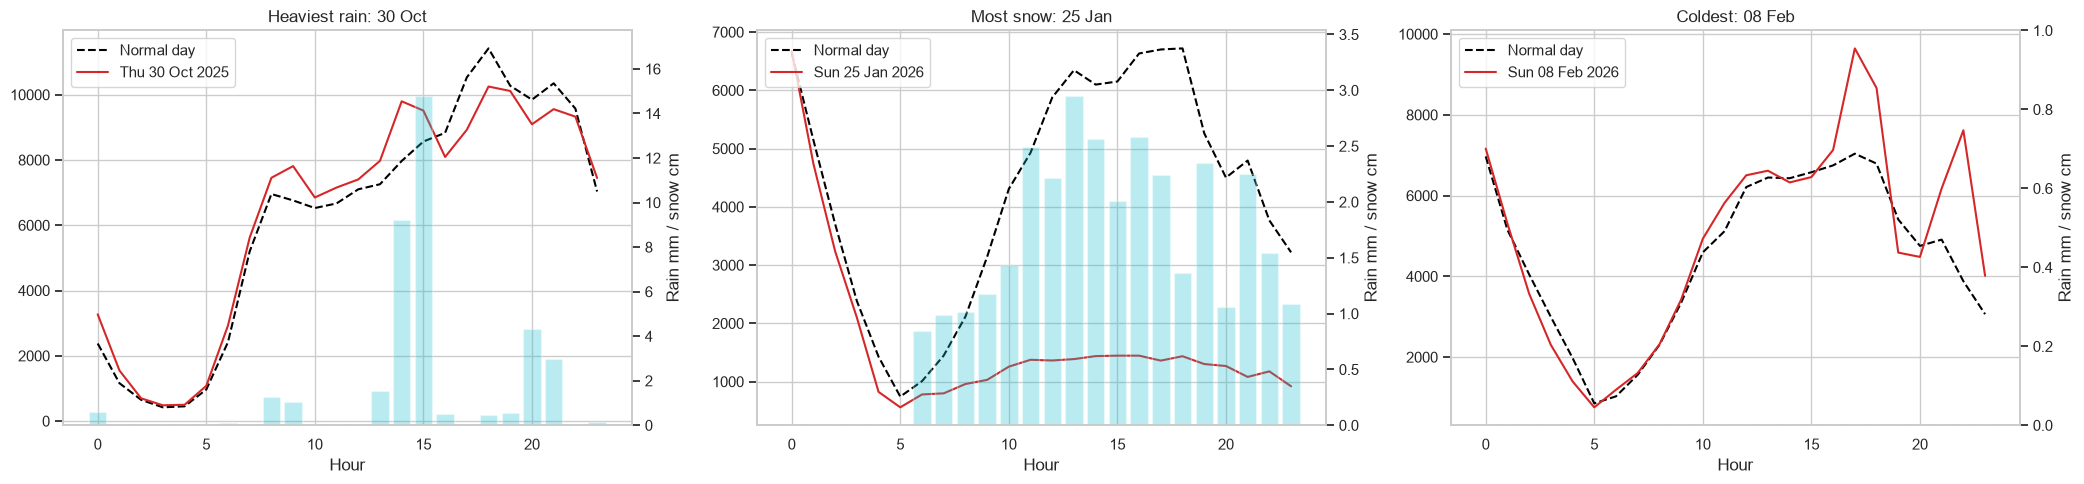

In [66]:
case_days = {
    "Heaviest rain": day_table.sort_values("rain_mm").iloc[-1]["date"],
    "Most snow": day_table.sort_values("snow_cm").iloc[-1]["date"],
    "Coldest": day_table.sort_values("avg_feels_like_c").iloc[0]["date"],
}
normal_days_list = day_table[(day_table["is_holiday"] == False) & (day_table["is_snow_day"] == False)]["date"]
hour_borough = df.groupby(["date", "hour", "borough"])["trip_count"].sum().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for i, (title, day) in enumerate(case_days.items()):
    same_days = normal_days_list[(normal_days_list.dt.dayofweek == day.dayofweek)
                                 & ((normal_days_list - day).abs() <= pd.Timedelta(days=28))
                                 & (normal_days_list != day)]
    actual = hourly[hourly.index.normalize() == day].values
    normal = df[df["date"].isin(same_days)].groupby(["date", "hour"])["trip_count"].sum().groupby("hour").median()

    axes[i].plot(range(24), normal.values, color="black", linestyle="--", label="Normal day")
    axes[i].plot(range(24), actual, color="tab:red", label=day.strftime("%a %d %b %Y"))
    weather_today = city[city["pickup_hour"].dt.normalize() == day]
    ax2 = axes[i].twinx()
    wet_amount = weather_today["rain"] + weather_today["snowfall"]
    ax2.bar(range(24), wet_amount, color="tab:cyan", alpha=0.3)
    ax2.set_ylim(0, max(1, wet_amount.max() * 1.2))
    ax2.set_ylabel("Rain mm / snow cm")
    ax2.grid(False)
    axes[i].set_title(title + ": " + day.strftime("%d %b"))
    axes[i].set_xlabel("Hour")
    axes[i].legend(loc="upper left")

    for borough in ["Manhattan", "Queens"]:
        day_total = hour_borough[(hour_borough["date"] == day) & (hour_borough["borough"] == borough)]["trip_count"].sum()
        normal_total = hour_borough[hour_borough["date"].isin(same_days) & (hour_borough["borough"] == borough)].groupby("date")["trip_count"].sum().median()
        print(title, day.strftime("%d %b"), "-", borough + ":", round((day_total / normal_total - 1) * 100, 1), "% vs normal")
save_fig("F12_extreme_weather_days")

**Finding:** The heaviest rain day (30 Oct) was close to normal. The biggest snow day (25 Jan) was 62-68% below normal all day. The coldest day (8 Feb) was 10% above normal, with evening peaks that likely match Super Bowl Sunday.

## I7. Weather effect summary (% change vs normal dry hour)

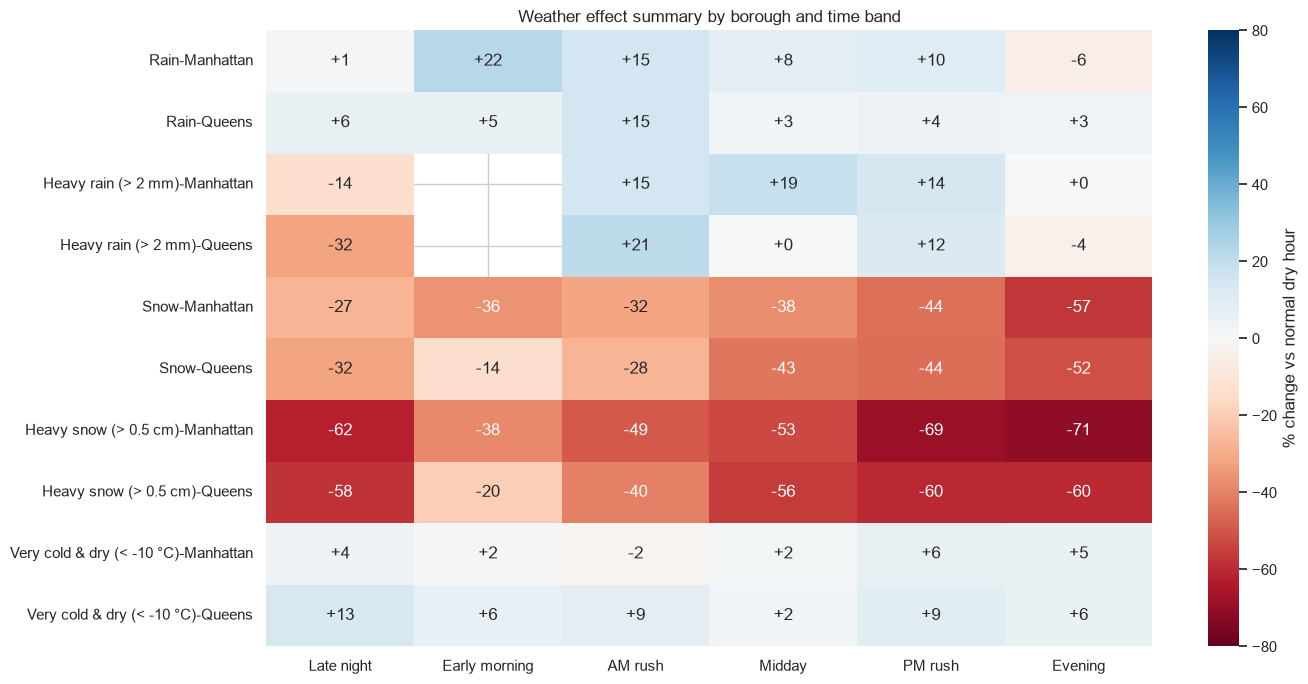

Saved weather_effects.csv


In [67]:
summary_conditions = {
    "Rain": wx["condition"] == "Rain",
    "Heavy rain (> 2 mm)": (wx["condition"] == "Rain") & (wx["rain"] > 2),
    "Snow": wx["condition"] == "Snow",
    "Heavy snow (> 0.5 cm)": wx["snowfall"] > 0.5,
    "Very cold & dry (< -10 °C)": (wx["condition"] == "Dry") & (wx["apparent_temperature"] < -10),
}
summary_rows = []
for name, mask in summary_conditions.items():
    for borough in ["Manhattan", "Queens"]:
        for band in TIME_BANDS:
            part = wx[mask & (wx["borough"] == borough) & (wx["time_band"] == band)]
            if len(part) >= 50:
                summary_rows.append({"condition": name, "borough": borough, "time_band": band,
                                     "change_%": round((demand_ratio(part) - 1) * 100, 1), "zone_hours": len(part)})
weather_summary = pd.DataFrame(summary_rows)
weather_summary.to_csv(TABLE_DIR + "/weather_effects.csv", index=False)

grid = weather_summary.pivot_table(index=["condition", "borough"], columns="time_band", values="change_%")[TIME_BANDS]
grid = grid.reindex(list(summary_conditions.keys()), level=0)

plt.figure(figsize=(14, 7))
sns.heatmap(grid, annot=True, fmt="+.0f", cmap="RdBu", center=0, vmin=-80, vmax=80,
            cbar_kws={"label": "% change vs normal dry hour"})
plt.title("Weather effect summary by borough and time band")
plt.xlabel("")
plt.ylabel("")
save_fig("I7_weather_effect_summary")
print("Saved weather_effects.csv")

**Finding:** Snow, especially heavy snow, is by far the strongest weather effect (-30 to -70%). Rain adds +5 to +20% in the morning and rush hours. Very cold dry hours are close to normal.

---
# 4. Feature relationships and correlations (#62)

In [68]:
LAG_COLS = ["trip_count_lag_1h", "trip_count_lag_24h", "trip_count_lag_168h",
            "trip_count_roll_3h", "trip_count_roll_24h"]
WEATHER_COLS = ["apparent_temperature", "rain", "snowfall", "precipitation_probability"]
CALENDAR_COLS = ["hour", "day_of_week", "month", "is_weekend", "is_holiday"]
FEATURE_COLS = WEATHER_COLS + CALENDAR_COLS + LAG_COLS

# True/False columns as 0/1 so they can be used in correlations
feat = df[["PULocationID", "pickup_hour", "borough", "trip_count"] + FEATURE_COLS].copy()
feat["is_weekend"] = feat["is_weekend"].astype(int)
feat["is_holiday"] = feat["is_holiday"].astype(int)
feat = feat.sort_values(["PULocationID", "pickup_hour"]).reset_index(drop=True)

## A4. Validate the lag and rolling features (recomputed from `trip_count` in each zone)

In [69]:
check = feat[["PULocationID", "trip_count"] + LAG_COLS].copy()
by_zone = check.groupby("PULocationID")["trip_count"]

check["my_lag_1h"] = by_zone.shift(1)
check["my_lag_24h"] = by_zone.shift(24)
check["my_lag_168h"] = by_zone.shift(168)
# Rolling means use only the hours BEFORE the current row (shift first, then roll)
check["my_roll_3h"] = by_zone.transform(lambda s: s.shift(1).rolling(3).mean())
check["my_roll_24h"] = by_zone.transform(lambda s: s.shift(1).rolling(24).mean())
# Wrong version that includes the current hour, to show the file does NOT do this
check["leaky_roll_3h"] = by_zone.transform(lambda s: s.rolling(3).mean())

pairs = [("trip_count_lag_1h", "my_lag_1h"), ("trip_count_lag_24h", "my_lag_24h"),
         ("trip_count_lag_168h", "my_lag_168h"), ("trip_count_roll_3h", "my_roll_3h"),
         ("trip_count_roll_24h", "my_roll_24h"), ("trip_count_roll_3h", "leaky_roll_3h")]

# The first rows of each zone depend on the dropped warm-up week, so they are skipped (NaN)
results = []
for file_col, my_col in pairs:
    rows = check[check[my_col].notna()]
    mismatches = ((rows[file_col] - rows[my_col]).abs() > 0.001).sum()
    results.append({"file column": file_col, "recomputed as": my_col,
                    "rows checked": len(rows), "mismatches": mismatches})
pd.DataFrame(results)

,file column,recomputed as,rows checked,mismatches
0,trip_count_lag_1h,my_lag_1h,576150,0
1,trip_count_lag_24h,my_lag_24h,572976,0
2,trip_count_lag_168h,my_lag_168h,553104,0
3,trip_count_roll_3h,my_roll_3h,575874,0
4,trip_count_roll_24h,my_roll_24h,572976,0
5,trip_count_roll_3h,leaky_roll_3h,576012,435992


**Finding:** All 5 lag and rolling features match the recomputed values exactly (0 mismatches). A rolling mean that wrongly includes the current hour would differ in 436 k rows, so the features have no data leakage.

## G1. Correlation of each feature with `trip_count` (Pearson and Spearman)

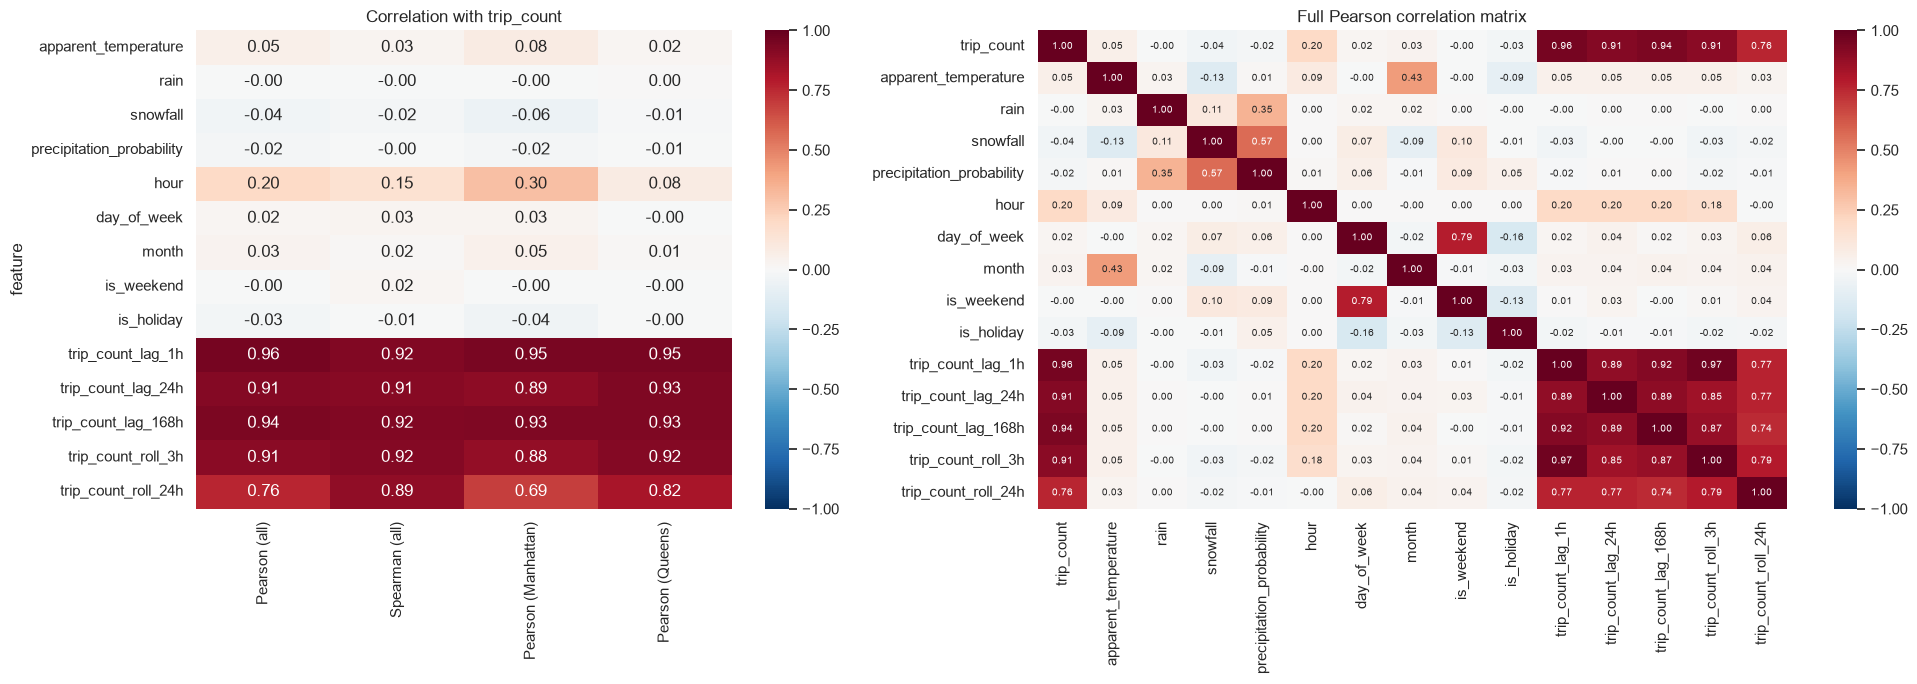

,Pearson (all),Spearman (all),Pearson (Manhattan),Pearson (Queens)
feature,,,,
apparent_temperature,0.055,0.026,0.085,0.022
rain,-0.000,-0.001,-0.001,0.001
snowfall,-0.036,-0.017,-0.056,-0.014
precipitation_probability,-0.016,-0.004,-0.022,-0.006
hour,0.201,0.150,0.302,0.078
day_of_week,0.016,0.030,0.027,-0.001
month,0.034,0.015,0.052,0.013
is_weekend,-0.001,0.018,-0.001,-0.001
is_holiday,-0.026,-0.008,-0.042,-0.000


In [70]:
corr_rows = []
for col in FEATURE_COLS:
    corr_rows.append({
        "feature": col,
        "Pearson (all)": feat[col].corr(feat["trip_count"]),
        "Spearman (all)": feat[col].corr(feat["trip_count"], method="spearman"),
        "Pearson (Manhattan)": feat[feat["borough"] == "Manhattan"][col].corr(feat[feat["borough"] == "Manhattan"]["trip_count"]),
        "Pearson (Queens)": feat[feat["borough"] == "Queens"][col].corr(feat[feat["borough"] == "Queens"]["trip_count"]),
    })
target_corr = pd.DataFrame(corr_rows).set_index("feature")

fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={"width_ratios": [1, 1.4]})
sns.heatmap(target_corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation with trip_count")

sns.heatmap(feat[["trip_count"] + FEATURE_COLS].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Full Pearson correlation matrix")
save_fig("G1_feature_correlations")
target_corr.round(3)

**Finding:** The lag features have the strongest link with demand (r = 0.91-0.96). Hour has r = 0.20 (0.30 in Manhattan). Weather and the other calendar features are close to 0 as straight-line correlations: their effects are relative changes, which are hidden by the big size differences between zones (see #61).

## G2. `trip_count` vs lag and rolling features (log scale, darker = more zone-hours)

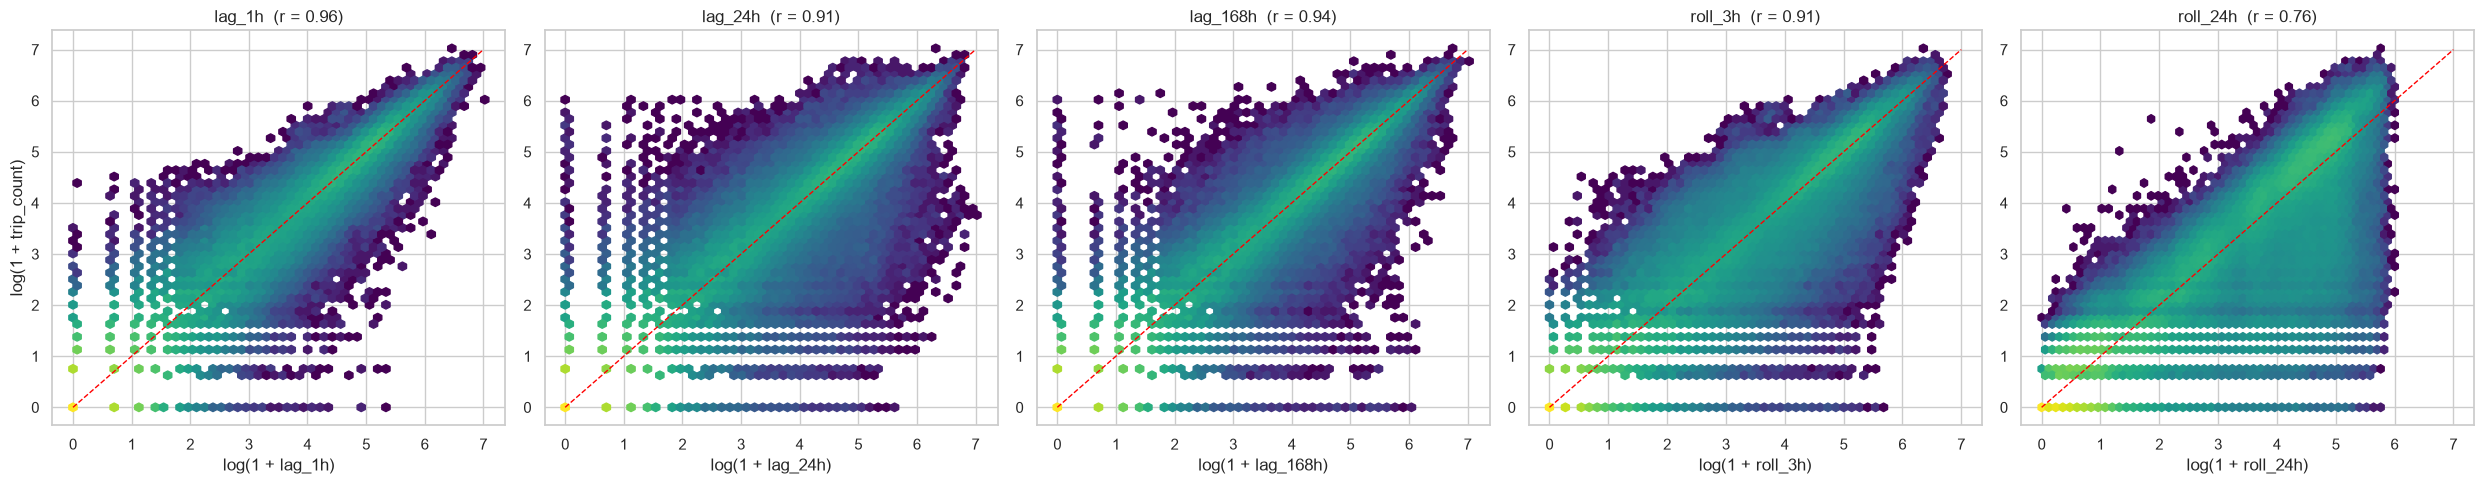

In [71]:
fig, axes = plt.subplots(1, 5, figsize=(25, 5))
for i, col in enumerate(LAG_COLS):
    axes[i].hexbin(np.log1p(feat[col]), np.log1p(feat["trip_count"]), gridsize=50, bins="log", cmap="viridis")
    axes[i].plot([0, 7], [0, 7], color="red", linestyle="--", linewidth=1)
    axes[i].set_xlabel("log(1 + " + col.replace("trip_count_", "") + ")")
    axes[i].set_title(col.replace("trip_count_", "") + "  (r = " + str(round(feat[col].corr(feat["trip_count"]), 2)) + ")")
axes[0].set_ylabel("log(1 + trip_count)")
save_fig("G2_lag_hexbin")

**Finding:** On a log scale the points follow the diagonal, so the relationship is roughly linear for busy zone-hours and noisy for small counts. `lag_1h` is the tightest; `roll_24h` is the loosest.

## G3. Lag correlation inside each zone, by zone tier

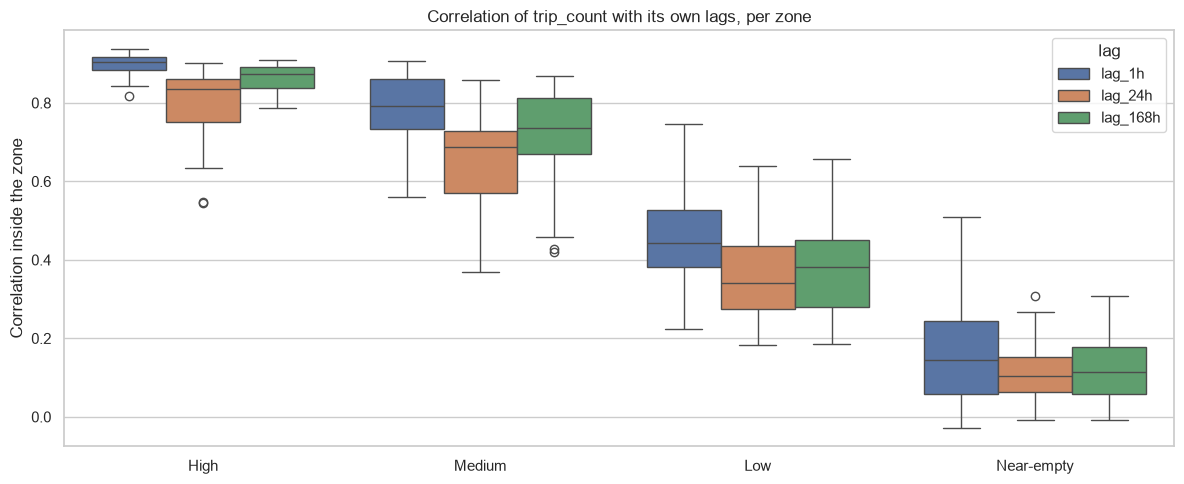

,lag_1h,lag_24h,lag_168h
tier,,,
High,0.90,0.84,0.87
Medium,0.79,0.69,0.74
Low,0.44,0.34,0.38
Near-empty,0.15,0.10,0.12


In [72]:
zone_corr_rows = []
for zone_id, group in feat.groupby("PULocationID"):
    if group["trip_count"].std() > 0:
        zone_corr_rows.append({
            "PULocationID": zone_id,
            "lag_1h": group["trip_count"].corr(group["trip_count_lag_1h"]),
            "lag_24h": group["trip_count"].corr(group["trip_count_lag_24h"]),
            "lag_168h": group["trip_count"].corr(group["trip_count_lag_168h"]),
        })
zone_corr = pd.DataFrame(zone_corr_rows).merge(zone_stats[["PULocationID", "tier"]], on="PULocationID")
zone_corr_long = zone_corr.melt(id_vars=["PULocationID", "tier"], var_name="lag", value_name="correlation")

plt.figure(figsize=(12, 5))
sns.boxplot(data=zone_corr_long, x="tier", y="correlation", hue="lag", order=TIER_ORDER)
plt.title("Correlation of trip_count with its own lags, per zone")
plt.ylabel("Correlation inside the zone")
plt.xlabel("")
save_fig("G3_zone_lag_correlation")

zone_corr.groupby("tier")[["lag_1h", "lag_24h", "lag_168h"]].median().reindex(TIER_ORDER).round(2)

**Finding:** Lags are very informative for High zones (median r = 0.90 for lag_1h) but weak for Near-empty zones (0.15).

## G4. Multicollinearity of lag and rolling features (VIF > 10 = strong overlap)

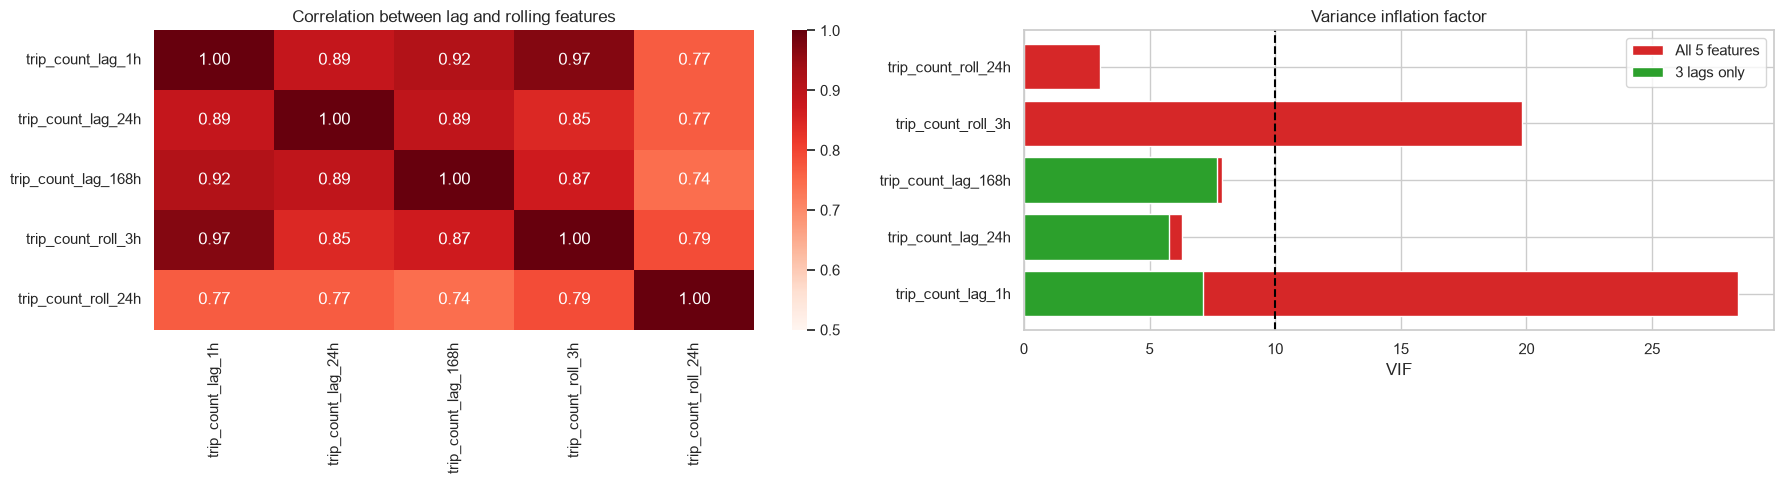

            feature  VIF
  trip_count_lag_1h 28.4
 trip_count_lag_24h  6.3
trip_count_lag_168h  7.9
 trip_count_roll_3h 19.8
trip_count_roll_24h  3.0

            feature  VIF
  trip_count_lag_1h  7.1
 trip_count_lag_24h  5.8
trip_count_lag_168h  7.7


In [73]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


def vif_table(columns):
    X = add_constant(feat[columns].astype(float))
    values = [variance_inflation_factor(X.values, i + 1) for i in range(len(columns))]
    return pd.DataFrame({"feature": columns, "VIF": values})


vif_all = vif_table(LAG_COLS)
vif_reduced = vif_table(["trip_count_lag_1h", "trip_count_lag_24h", "trip_count_lag_168h"])

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sns.heatmap(feat[LAG_COLS].corr(), annot=True, fmt=".2f", cmap="Reds", vmin=0.5, vmax=1, ax=axes[0])
axes[0].set_title("Correlation between lag and rolling features")
axes[1].barh(vif_all["feature"], vif_all["VIF"], color="tab:red", label="All 5 features")
axes[1].barh(vif_reduced["feature"], vif_reduced["VIF"], color="tab:green", label="3 lags only")
axes[1].axvline(10, color="black", linestyle="--")
axes[1].set_xlabel("VIF")
axes[1].set_title("Variance inflation factor")
axes[1].legend()
save_fig("G4_multicollinearity")
print(vif_all.round(1).to_string(index=False))
print()
print(vif_reduced.round(1).to_string(index=False))

**Finding:** `lag_1h` (VIF 28) and `roll_3h` (VIF 20) overlap strongly (r = 0.97). With only the 3 lags, every VIF is below 8. Linear models should drop `roll_3h`; tree models can keep all features.

## G5. How much variation each categorical feature explains on its own (eta-squared)

Zone x hour together: 0.842


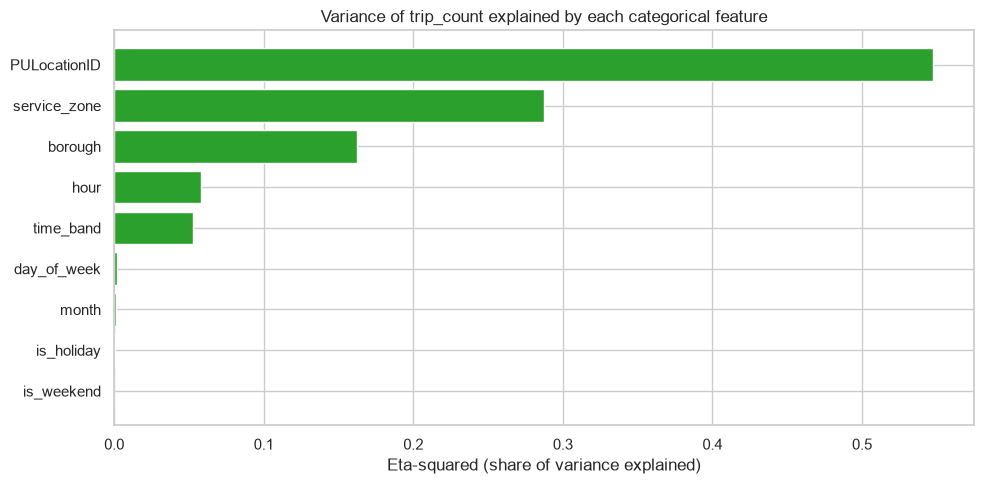

,feature,eta_squared
0,PULocationID,0.547
1,service_zone,0.287
2,borough,0.162
3,hour,0.058
4,time_band,0.053
5,day_of_week,0.002
8,month,0.001
7,is_holiday,0.001
6,is_weekend,0.000


In [74]:
def eta_squared(data, group_col, target="trip_count"):
    # Share of the total variance of the target explained by the group means
    overall_mean = data[target].mean()
    groups = data.groupby(group_col)[target]
    between = (groups.count() * (groups.mean() - overall_mean) ** 2).sum()
    total = ((data[target] - overall_mean) ** 2).sum()
    return between / total


cat_features = ["PULocationID", "service_zone", "borough", "hour", "time_band",
                "day_of_week", "is_weekend", "is_holiday", "month"]
eta = pd.DataFrame({"feature": cat_features,
                    "eta_squared": [eta_squared(df, col) for col in cat_features]}).sort_values("eta_squared")

# Zone and hour together (each zone-hour combination as one group)
df["zone_hour"] = df["PULocationID"].astype(str) + "_" + df["hour"].astype(str)
print("Zone x hour together:", round(eta_squared(df, "zone_hour"), 3))

plt.figure(figsize=(10, 5))
plt.barh(eta["feature"], eta["eta_squared"], color="tab:green")
plt.xlabel("Eta-squared (share of variance explained)")
plt.title("Variance of trip_count explained by each categorical feature")
save_fig("G5_eta_squared")
eta.sort_values("eta_squared", ascending=False).round(3)

**Finding:** The zone alone explains 55% of the variance, and zone x hour explains 84%. Hour alone explains 6%. Weekday, month, weekend and holiday each explain under 1% on their own.

## G6. Mutual information with `trip_count` (captures non-linear links; 100,000-row sample)

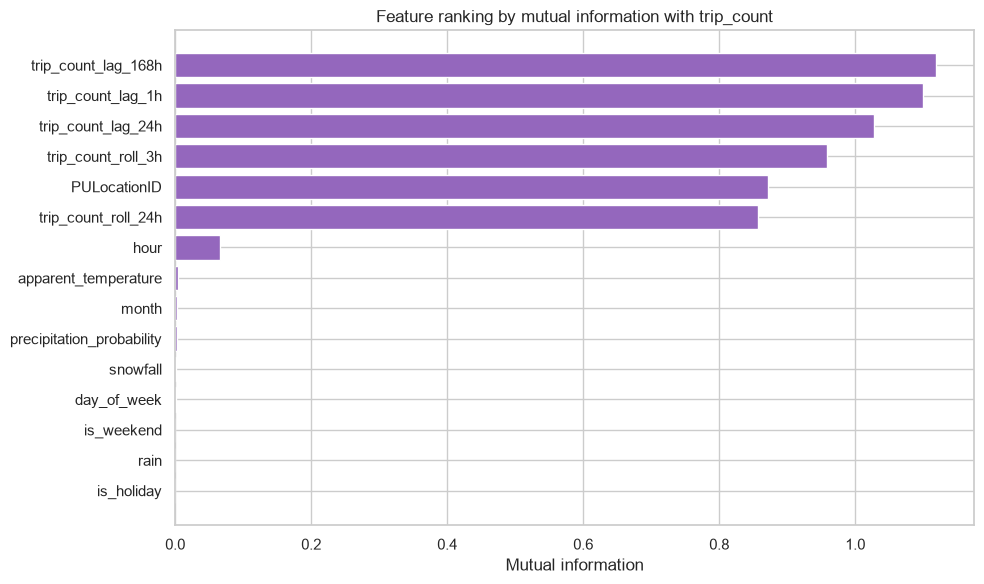

,feature,mutual_information
12,trip_count_lag_168h,1.119
10,trip_count_lag_1h,1.100
11,trip_count_lag_24h,1.027
13,trip_count_roll_3h,0.958
0,PULocationID,0.872
14,trip_count_roll_24h,0.857
5,hour,0.066
1,apparent_temperature,0.005
7,month,0.002
4,precipitation_probability,0.002


In [75]:
from sklearn.feature_selection import mutual_info_regression

mi_cols = ["PULocationID"] + FEATURE_COLS
sample = feat.sample(100000, random_state=42)
discrete = [col in ["PULocationID", "hour", "day_of_week", "month", "is_weekend", "is_holiday"] for col in mi_cols]

mi_values = mutual_info_regression(sample[mi_cols], sample["trip_count"], discrete_features=discrete, random_state=42)
mi = pd.DataFrame({"feature": mi_cols, "mutual_information": mi_values}).sort_values("mutual_information")

plt.figure(figsize=(10, 6))
plt.barh(mi["feature"], mi["mutual_information"], color="tab:purple")
plt.xlabel("Mutual information")
plt.title("Feature ranking by mutual information with trip_count")
save_fig("G6_mutual_information")
mi.sort_values("mutual_information", ascending=False).round(3)

**Finding:** Ranking: lag_168h, lag_1h, lag_24h, roll_3h, zone ID, roll_24h, then hour. Weather and calendar features carry little information on their own; they adjust demand rather than set its level.